<!-- update2-explanatory-markdown-v1 -->

# Update 2: Forensic Auditing and Identity Drift

This notebook extends Update 1 with Human-origin stylometry, held-out identity trajectories, original-source attribution and paraphraser fingerprints across seven domains and seven configurations.

**Research questions.** RQ1 concerns stylistic change relative to semantic change; RQ2 concerns recoverability of the original source; RQ3 concerns paraphraser-specific linguistic traces.

**Scope.** The full clean-chain set contains 16,659 originals. Human-origin descriptive analyses use 2,351 originals; held-out Human trajectory analyses use 355. Source and paraphraser classifiers use 2,543 held-out originals.

**Execution status.** Existing saved outputs are retained. Prediction tables and reported classification metrics were checked for consistency. A fresh-kernel end-to-end rerun has not been performed during this documentation update. No experiments are executed by adding these notes.

## 1. Environment and analysis definitions

Define project paths, seven domains, seven paraphraser configurations, T0-T3 labels and feature names. The random seed is 6120. Text identities use `(domain, source, key, version_name)`.

In [2]:
from pathlib import Path
from collections import Counter
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from tqdm.auto import tqdm

# Project paths.
project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

data_root = (
    project_root.parent
    / "Ship_of_theseus_paraphrased_copus"
    / "paraphrased_datasets"
)

manifest_path = project_root / "data/metadata/shared_sample_manifest.csv"
legacy_style_dir = project_root / "experiments/style_features_spacy_v1"

output_dir = project_root / "experiments/update2"
feature_dir = output_dir / "style_features_full_clean_v1"
feature_path = feature_dir / "full_style_features.csv"
figure_dir = project_root / "figures/update2"

for directory in [output_dir, feature_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

# Experiment settings.
RANDOM_SEED = 6120
EXPECTED_ORIGINALS = 16659
CHUNK_SIZE = 500

domains = ["cmv", "eli5", "sci_gen", "tldr", "wp", "xsum", "yelp"]

configuration_labels = {
    "chatgpt": "ChatGPT",
    "palm": "PaLM",
    "pegasus(full)": "Pegasus full",
    "pegasus(slight)": "Pegasus slight",
    "dipper": "DIPPER",
    "dipper(low)": "DIPPER low",
    "dipper(high)": "DIPPER high",
}

configurations = list(configuration_labels)
stage_order = ["T0", "T1", "T2", "T3"]
split_order = ["train", "validation", "test"]

version_metadata = {
    "original": {"configuration": "original", "iteration": 0},
    **{
        "_".join([configuration] * iteration): {
            "configuration": configuration,
            "iteration": iteration,
        }
        for configuration in configurations
        for iteration in range(1, 4)
    },
}

sample_keys = ["domain", "source", "key"]
identity_columns = sample_keys + ["version_name"]

pos_tags = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET",
    "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN",
    "SCONJ", "SYM", "VERB", "X", "PUNCT",
]

pos_columns = [f"pos_{tag}" for tag in pos_tags]

numeric_columns = [
    "token_count",
    "sentence_count",
    "mean_sentence_length",
    "sentence_length_std",
    "sentence_length_cv",
    "mean_dependency_depth",
    *pos_columns,
]

required_columns = identity_columns + numeric_columns

sns.set_theme(style="whitegrid", context="notebook")

print(f"Project root: {project_root}")
print(f"Target sample: {EXPECTED_ORIGINALS:,} complete original chains")
print(f"Complete feature table available: {feature_path.is_file()}")

Project root: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus
Target sample: 16,659 complete original chains
Complete feature table available: True


/Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Complete clean-chain feature table

Load the authoritative 16,659-original manifest and validate all 366,498 text versions. Reuse the complete feature cache when available; otherwise reuse Update 1 records and resumable extraction checkpoints.

POS proportions exclude tokens marked as spaces or punctuation. Dependency depth is the maximum ancestor-edge count within each sentence, averaged over nonempty sentences. The complete sample contains 2,351 Human originals.

In [3]:
def read_features(path):
    return pd.read_csv(
        path,
        usecols=required_columns,
        dtype={column: str for column in identity_columns},
        keep_default_na=False,
        na_values=[""],
    )


def validate_features(frame):
    assert not frame.duplicated(identity_columns).any(), (
        "Duplicate text identities detected."
    )

    assert frame[identity_columns].notna().all().all()

    assert np.isfinite(
        frame[numeric_columns].to_numpy(dtype=float)
    ).all(), "Missing or infinite feature values detected."

    assert frame["token_count"].gt(0).all()

    assert np.allclose(
        frame[pos_columns].sum(axis=1),
        1.0,
    ), "Invalid POS proportions."


def extract_style_features(doc):
    tokens = [
        token for token in doc
        if not token.is_space and not token.is_punct
    ]

    lengths = []
    depths = []

    for sentence in doc.sents:
        sentence_tokens = [
            token for token in sentence
            if not token.is_space and not token.is_punct
        ]

        if sentence_tokens:
            lengths.append(len(sentence_tokens))
            depths.append(
                max(len(list(token.ancestors)) for token in sentence_tokens)
            )

    mean_length = float(np.mean(lengths)) if lengths else np.nan
    std_length = float(np.std(lengths, ddof=0)) if lengths else np.nan

    counts = Counter(token.pos_ for token in tokens)
    token_count = len(tokens)

    return {
        "token_count": token_count,
        "sentence_count": len(lengths),
        "mean_sentence_length": mean_length,
        "sentence_length_std": std_length,
        "sentence_length_cv": (
            std_length / mean_length if mean_length > 0 else np.nan
        ),
        "mean_dependency_depth": (
            float(np.mean(depths)) if depths else np.nan
        ),
        **{
            f"pos_{tag}": counts[tag] / token_count if token_count else np.nan
            for tag in pos_tags
        },
    }


# Load the authoritative clean-chain sample.
manifest = (
    pd.read_csv(manifest_path, dtype=str, keep_default_na=False)
    [sample_keys]
    .sort_values(sample_keys)
    .reset_index(drop=True)
)

assert len(manifest) == EXPECTED_ORIGINALS
assert not manifest.duplicated(sample_keys).any()
assert set(manifest["domain"]) == set(domains)

# Construct the exact set of expected text identities.
versions = pd.DataFrame({"version_name": list(version_metadata)})
expected_ids = manifest.merge(versions, how="cross")

if feature_path.is_file():
    style_features = read_features(feature_path)
    print("Loaded the complete feature table.")

else:
    # Load raw texts for the selected complete chains.
    text_frames = []

    for domain in domains:
        raw = pd.read_csv(
            data_root / f"{domain}_paraphrased.csv",
            dtype=str,
            keep_default_na=False,
            encoding="utf-8-sig",
        )

        selected = raw.loc[
            raw["version_name"].isin(version_metadata),
            ["source", "key", "version_name", "text"],
        ].merge(
            manifest.loc[
                manifest["domain"].eq(domain),
                ["source", "key"],
            ],
            on=["source", "key"],
            how="inner",
            validate="many_to_one",
        )

        selected.insert(0, "domain", domain)
        text_frames.append(selected)

    texts = pd.concat(text_frames, ignore_index=True)

    assert not texts.duplicated(identity_columns).any()

    text_coverage = expected_ids.merge(
        texts[identity_columns],
        on=identity_columns,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    assert text_coverage["_merge"].eq("both").all()

    assert texts["text"].map(
        lambda text: any(character.isalnum() for character in text)
    ).all()

    # Reuse the Update 1 per-text caches.
    legacy_paths = [
        path
        for domain in domains
        for path in sorted((legacy_style_dir / domain).glob("*.csv"))
    ]

    if legacy_paths:
        cached = pd.concat(
            [read_features(path) for path in legacy_paths],
            ignore_index=True,
        )

        validate_features(cached)

        cached = cached.merge(
            expected_ids,
            on=identity_columns,
            how="inner",
            validate="one_to_one",
        )[required_columns]

    else:
        cached = pd.DataFrame(columns=required_columns)

    missing = texts.merge(
        cached[identity_columns],
        on=identity_columns,
        how="left",
        validate="one_to_one",
        indicator=True,
    )

    missing = (
        missing.loc[
            missing["_merge"].eq("left_only"),
            identity_columns + ["text"],
        ]
        .sort_values(identity_columns)
        .reset_index(drop=True)
    )

    print(f"Reused feature records: {len(cached):,}")
    print(f"Additional records to process or reload: {len(missing):,}")

    chunk_dir = feature_dir / "chunks"
    chunk_dir.mkdir(exist_ok=True)

    additional_frames = []

    if len(missing):
        nlp = spacy.load("en_core_web_sm", disable=["ner"])

        assert spacy.__version__ == "3.8.16", (
            "Match the Update 1 spaCy version: 3.8.16."
        )
        assert nlp.meta["version"] == "3.8.0", (
            "Match the Update 1 parser model version: 3.8.0."
        )

        nlp.max_length = max(
            nlp.max_length,
            int(missing["text"].str.len().max()) + 1,
        )

        # Text progress bar avoids the optional ipywidgets dependency.
        from tqdm import tqdm as text_progress

        with text_progress(
            total=len(missing),
            desc="Style features",
            unit="text",
        ) as progress:
            for start in range(0, len(missing), CHUNK_SIZE):
                chunk = missing.iloc[start:start + CHUNK_SIZE]
                path = chunk_dir / f"features_{start:06d}.csv"

                if path.is_file():
                    output = read_features(path)

                else:
                    docs = nlp.pipe(
                        chunk["text"].tolist(),
                        batch_size=32,
                        n_process=1,
                        disable=["lemmatizer"],
                    )

                    records = [
                        {
                            **dict(zip(identity_columns, identity)),
                            **extract_style_features(doc),
                        }
                        for identity, doc in zip(
                            chunk[identity_columns].itertuples(
                                index=False,
                                name=None,
                            ),
                            docs,
                        )
                    ]

                    output = pd.DataFrame(
                        records,
                        columns=required_columns,
                    )

                assert output[identity_columns].reset_index(drop=True).equals(
                    chunk[identity_columns].reset_index(drop=True)
                ), f"Checkpoint identity mismatch: {path.name}"

                validate_features(output)

                if not path.is_file():
                    temporary_path = path.with_suffix(".tmp")
                    output.to_csv(temporary_path, index=False)
                    temporary_path.replace(path)

                additional_frames.append(output)
                progress.update(len(chunk))

        del nlp

    style_features = pd.concat(
        [cached, *additional_frames],
        ignore_index=True,
    )[required_columns]

    validate_features(style_features)

    final_coverage = expected_ids.merge(
        style_features[identity_columns],
        on=identity_columns,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    assert final_coverage["_merge"].eq("both").all()

    temporary_path = feature_path.with_suffix(".tmp")
    style_features.to_csv(temporary_path, index=False)
    temporary_path.replace(feature_path)

# Validate loaded and newly generated tables identically.
validate_features(style_features)

coverage_check = expected_ids.merge(
    style_features[identity_columns],
    on=identity_columns,
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert coverage_check["_merge"].eq("both").all()

metadata = (
    pd.DataFrame.from_dict(version_metadata, orient="index")
    .rename_axis("version_name")
    .reset_index()
)

style_features = style_features.merge(
    metadata,
    on="version_name",
    how="left",
    validate="many_to_one",
)

style_features["stage"] = "T" + style_features["iteration"].astype(str)

originals = style_features.loc[
    style_features["iteration"].eq(0)
].copy()

human_features = style_features.loc[
    style_features["source"].eq("Human")
].copy()

human_originals = human_features.loc[
    human_features["iteration"].eq(0)
].copy()

print(f"\nValidated text records: {len(style_features):,}")
print(f"T0 originals: {len(originals):,}")
print(f"Human T0 originals: {len(human_originals):,}")
print(f"Complete feature table saved: {feature_path}")

display(
    originals.groupby(["domain", "source"])
    .size()
    .unstack(fill_value=0)
    .reindex(domains)
)

Loaded the complete feature table.

Validated text records: 366,498
T0 originals: 16,659
Human T0 originals: 2,351
Complete feature table saved: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/style_features_full_clean_v1/full_style_features.csv


source,BigScience,Eleuther-AI,Human,LLAMA,OpenAI,PaLM,Tsinghua
domain,,,,,,,
cmv,224,181,227,237,233,159,228
eli5,439,358,452,444,457,460,451
sci_gen,177,97,227,233,464,231,202
tldr,344,291,371,349,373,246,356
wp,318,220,255,311,415,89,311
xsum,460,407,336,459,452,433,453
yelp,448,444,483,475,447,468,464


## 3. Grouped train, validation and test splits

Keep all source variants and rewrites of each `(domain, key)` group in one split. Assign groups within domains using approximately 70/15/15 proportions.

| Split | Groups | Originals | Human originals |
| --- | ---: | ---: | ---: |
| Train | 2,092 | 11,620 | 1,637 |
| Validation | 447 | 2,496 | 359 |
| Test | 455 | 2,543 | 355 |

Use the current `full_clean_v1` split files. Historical manifests for the 12,523-original subset are not interchangeable with these.

In [4]:
# Split the full clean-chain sample by document group within each domain.
split_path = output_dir / "group_split_full_clean_v1.csv"

groups = (
    originals[["domain", "key"]]
    .drop_duplicates()
    .sort_values(["domain", "key"])
    .reset_index(drop=True)
)

if split_path.is_file():
    group_splits = pd.read_csv(
        split_path,
        dtype=str,
        keep_default_na=False,
    )

    assert set(group_splits.columns) == {"domain", "key", "split"}
    assert not group_splits.duplicated(["domain", "key"]).any()
    assert set(group_splits["split"]) == set(split_order)

    saved_groups = set(
        group_splits[["domain", "key"]]
        .itertuples(index=False, name=None)
    )
    expected_groups = set(
        groups.itertuples(index=False, name=None)
    )

    assert saved_groups == expected_groups, (
        "The saved split does not match the full clean-chain sample."
    )

    print("Loaded the saved full-sample split.")

else:
    rng = np.random.default_rng(RANDOM_SEED)
    frames = []

    for domain in domains:
        domain_groups = groups.loc[
            groups["domain"].eq(domain)
        ].copy()

        domain_groups = domain_groups.iloc[
            rng.permutation(len(domain_groups))
        ].reset_index(drop=True)

        n = len(domain_groups)
        n_train = int(np.floor(0.70 * n))
        n_validation = int(np.floor(0.15 * n))

        domain_groups["split"] = (
            ["train"] * n_train
            + ["validation"] * n_validation
            + ["test"] * (n - n_train - n_validation)
        )

        frames.append(domain_groups)

    group_splits = (
        pd.concat(frames, ignore_index=True)
        .sort_values(["domain", "key"])
        .reset_index(drop=True)
    )

    print("Created the full-sample split.")

style_features = (
    style_features.drop(columns=["split"], errors="ignore")
    .merge(
        group_splits,
        on=["domain", "key"],
        how="left",
        validate="many_to_one",
    )
)

assert len(style_features) == EXPECTED_ORIGINALS * 22
assert style_features["split"].notna().all()

assert (
    style_features.groupby(["domain", "key"])["split"]
    .nunique()
    .eq(1)
    .all()
), "Document groups cross split boundaries."

originals = style_features.loc[
    style_features["iteration"].eq(0)
].copy()

human_features = style_features.loc[
    style_features["source"].eq("Human")
].copy()

human_originals = human_features.loc[
    human_features["iteration"].eq(0)
].copy()

source_counts = pd.crosstab(
    originals["source"],
    originals["split"],
).reindex(columns=split_order, fill_value=0)

domain_source_counts = pd.crosstab(
    [originals["domain"], originals["source"]],
    originals["split"],
).reindex(columns=split_order, fill_value=0)

assert domain_source_counts.gt(0).all().all(), (
    "At least one domain-source category is absent from a split."
)

group_splits.to_csv(split_path, index=False)

originals[
    sample_keys + ["split"]
].sort_values(sample_keys).to_csv(
    output_dir / "original_split_full_clean_v1.csv",
    index=False,
)

summary = pd.DataFrame({
    "document_groups": group_splits.groupby("split").size(),
    "all_source_originals": originals.groupby("split").size(),
    "human_originals": human_originals.groupby("split").size(),
}).reindex(split_order)

human_counts = pd.crosstab(
    human_originals["domain"],
    human_originals["split"],
).reindex(
    index=domains,
    columns=split_order,
    fill_value=0,
)

summary.to_csv(output_dir / "split_summary_full_clean_v1.csv")

print(f"Random seed: {RANDOM_SEED}")
print(f"Total originals: {len(originals):,}")
print(f"Document groups: {len(group_splits):,}")
print("Validation passed: no group overlap; all domain-source classes covered.")
print(f"Saved split: {split_path}")

print("\nSplit summary:")
display(summary)

print("\nSource counts:")
display(source_counts)

print("\nHuman originals by domain:")
display(human_counts)

Loaded the saved full-sample split.
Random seed: 6120
Total originals: 16,659
Document groups: 2,994
Validation passed: no group overlap; all domain-source classes covered.
Saved split: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/group_split_full_clean_v1.csv

Split summary:


,document_groups,all_source_originals,human_originals
split,,,
train,2092,11620,1637
validation,447,2496,359
test,455,2543,355



Source counts:


split,train,validation,test
source,,,
BigScience,1679,362,369
Eleuther-AI,1396,301,301
Human,1637,359,355
LLAMA,1752,369,387
OpenAI,1990,427,424
PaLM,1453,307,326
Tsinghua,1713,371,381



Human originals by domain:


split,train,validation,test
domain,,,
cmv,163,33,31
eli5,317,68,67
sci_gen,158,36,33
tldr,258,57,56
wp,175,39,41
xsum,228,55,53
yelp,338,71,74


## 4. Human-origin stylometric profiles

Compare each rewrite with its own Human T0 using POS total variation distance and signed changes in structural features. T0 distances and changes must equal zero; actual T0 feature values are measured rather than set to zero.

These are descriptive means across all splits, based on 2,351 paired originals per configuration. T0 is repeated across configurations for plotting, not counted as independent additional data. Greater POS distance indicates distributional change, not calibrated loss of meaning or individual authorship.

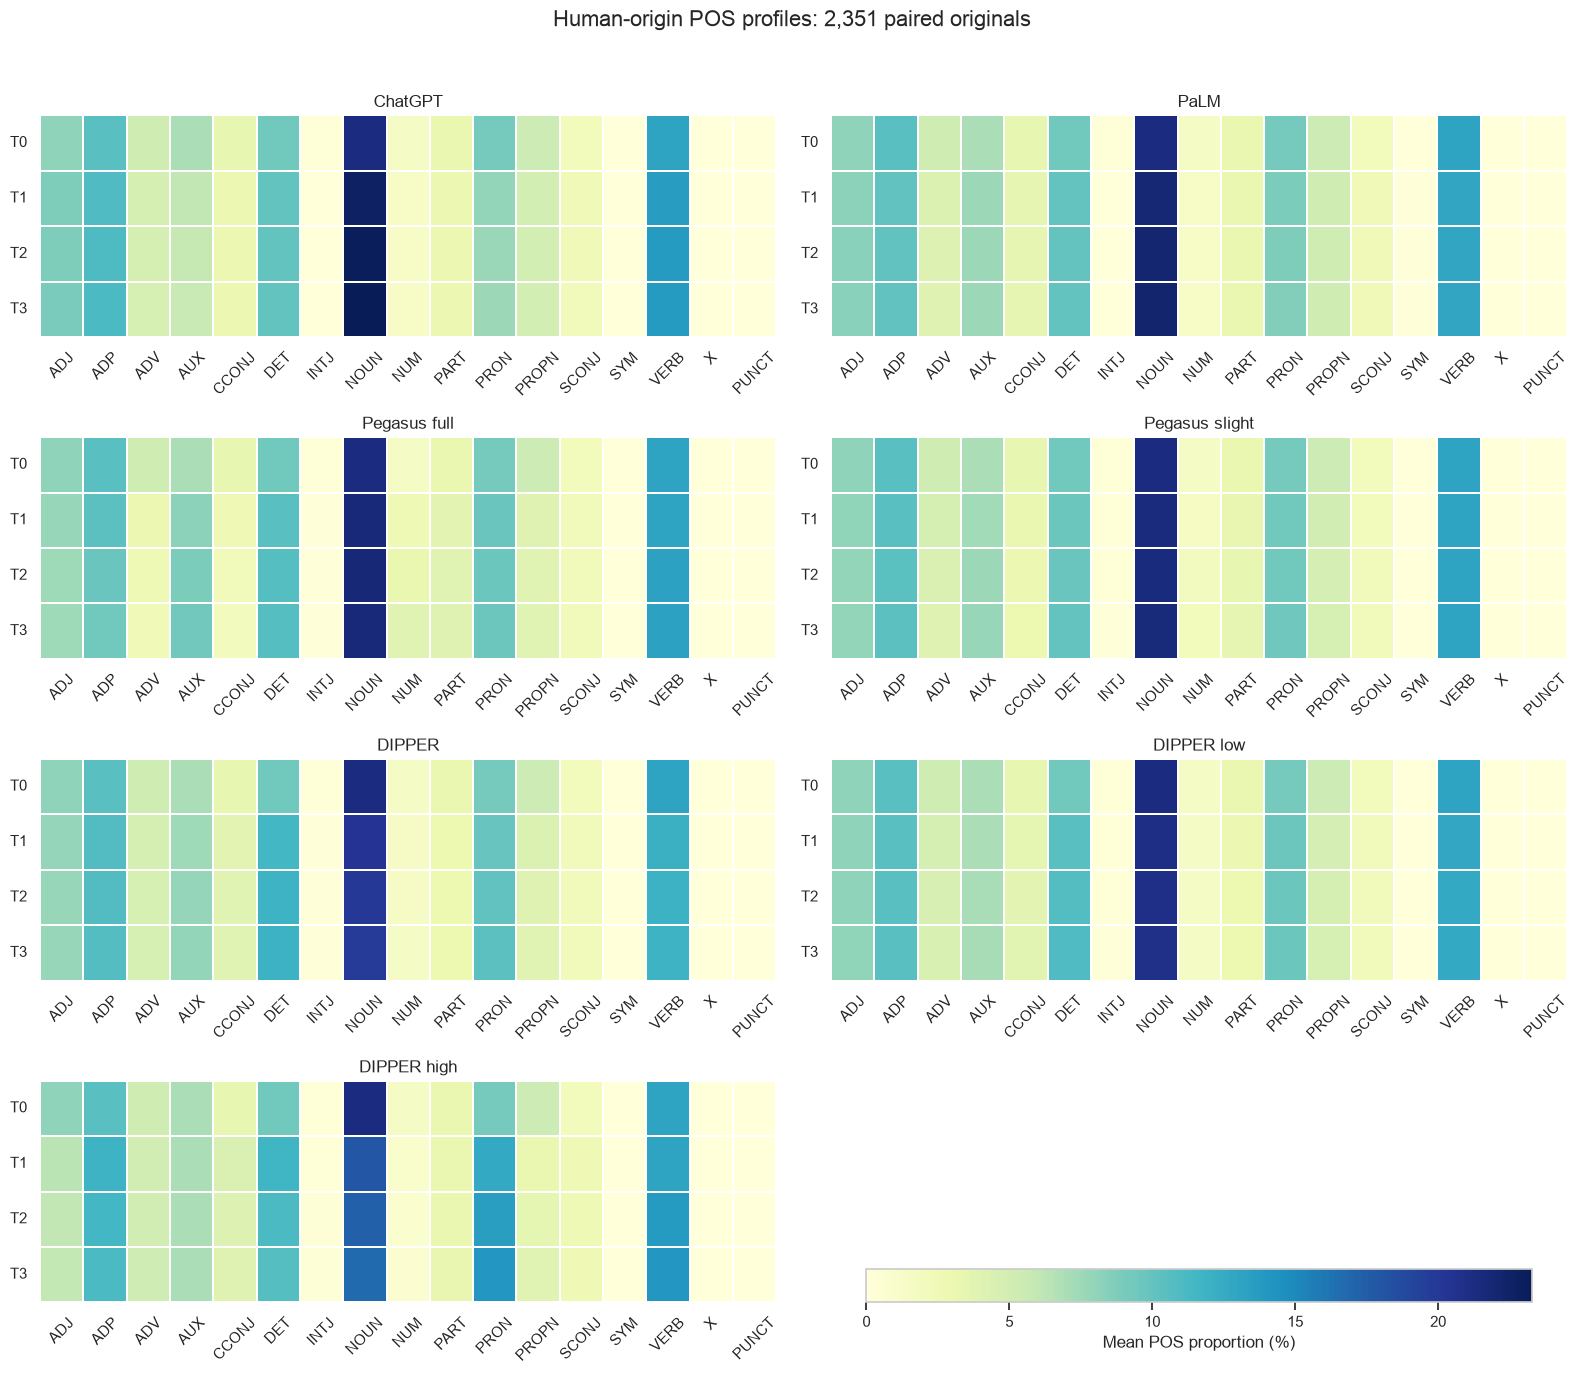

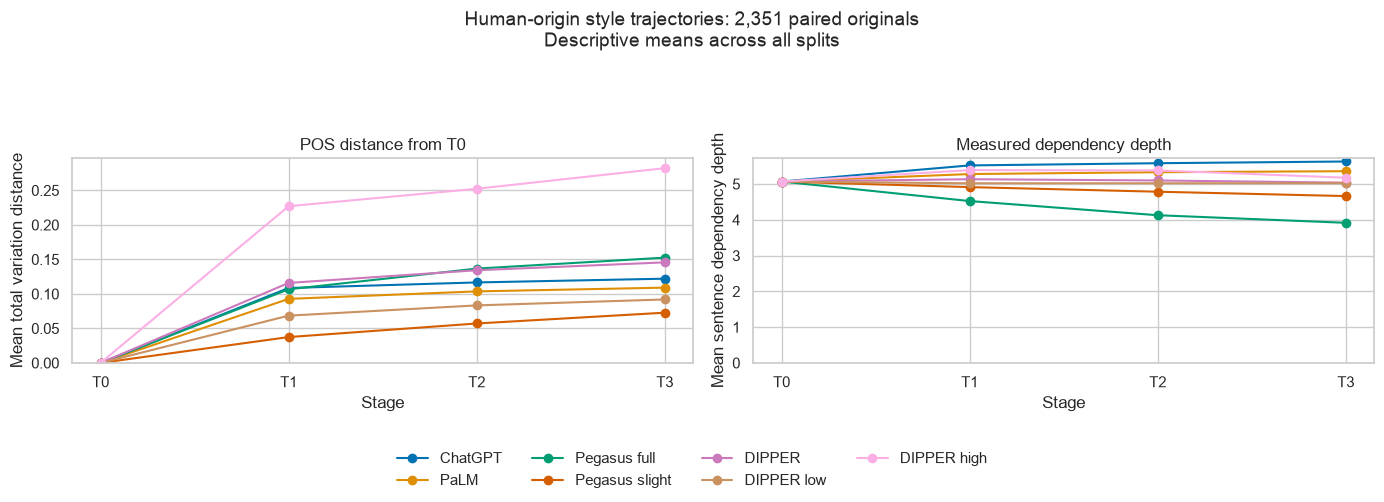

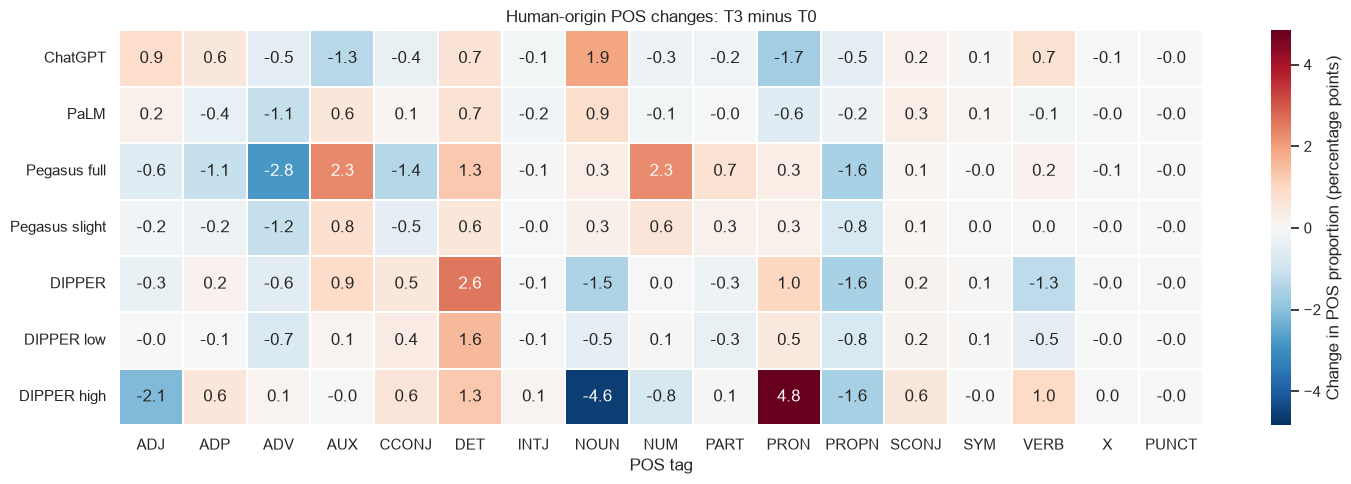

Human originals per trajectory: 2,351
T0 checks passed: paired distances and changes equal zero.
Tables saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/stylometry
Figures saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/figures/update2


,configuration,n_originals,pos_distance,mean_dependency_depth,mean_dependency_depth_change,mean_sentence_length_change
3,chatgpt,2351,0.1220,5.6295,0.5604,0.8949
7,palm,2351,0.1091,5.3582,0.2891,0.2177
11,pegasus(full),2351,0.1525,3.9159,-1.1532,-5.1409
15,pegasus(slight),2351,0.0728,4.6633,-0.4058,-2.1385
19,dipper,2351,0.1457,5.0381,-0.0310,0.6462
23,dipper(low),2351,0.0919,5.0226,-0.0465,-0.0311
27,dipper(high),2351,0.2822,5.1769,0.1077,4.5286


In [5]:
# Human-origin stylometric profiling across T0-T3.
stylometry_dir = output_dir / "stylometry"
stylometry_dir.mkdir(exist_ok=True)

human_t0 = (
    human_originals
    .set_index(sample_keys)
    .sort_index()
)

paired_frames = []

for configuration in configurations:
    for iteration in range(4):
        version = (
            "original"
            if iteration == 0
            else "_".join([configuration] * iteration)
        )

        current = (
            human_features.loc[
                human_features["version_name"].eq(version)
            ]
            .set_index(sample_keys)
            .reindex(human_t0.index)
        )

        assert current[numeric_columns].notna().all().all()

        frame = current.reset_index().copy()
        frame["configuration"] = configuration
        frame["iteration"] = iteration
        frame["stage"] = f"T{iteration}"

        frame["pos_distance"] = 0.5 * np.abs(
            current[pos_columns].to_numpy()
            - human_t0[pos_columns].to_numpy()
        ).sum(axis=1)

        for feature in [
            "mean_dependency_depth",
            "mean_sentence_length",
            "sentence_count",
        ]:
            frame[f"{feature}_change"] = (
                current[feature].to_numpy()
                - human_t0[feature].to_numpy()
            )

        for column in pos_columns:
            frame[f"{column}_change"] = (
                current[column].to_numpy()
                - human_t0[column].to_numpy()
            )

        paired_frames.append(frame)

human_style_pairs = pd.concat(paired_frames, ignore_index=True)

change_columns = [
    "pos_distance",
    "mean_dependency_depth_change",
    "mean_sentence_length_change",
    "sentence_count_change",
    *[f"{column}_change" for column in pos_columns],
]

assert len(human_style_pairs) == len(human_t0) * 7 * 4
assert np.allclose(
    human_style_pairs.loc[
        human_style_pairs["iteration"].eq(0),
        change_columns,
    ],
    0.0,
)

# Each document receives equal weight.
summary_metrics = [
    *pos_columns,
    "mean_dependency_depth",
    "mean_sentence_length",
    "sentence_count",
    *change_columns,
]

def summarize_style(frame, group_columns):
    grouped = frame.groupby(group_columns, sort=False)

    return (
        grouped[summary_metrics].mean()
        .join(grouped.size().rename("n_originals"))
        .reset_index()
    )

human_style_overall = summarize_style(
    human_style_pairs,
    ["configuration", "iteration", "stage"],
)

human_style_by_domain = summarize_style(
    human_style_pairs,
    ["domain", "configuration", "iteration", "stage"],
)

for filename, table in {
    "human_style_pairs.csv": human_style_pairs,
    "human_style_overall.csv": human_style_overall,
    "human_style_by_domain.csv": human_style_by_domain,
}.items():
    table.to_csv(stylometry_dir / filename, index=False)

# Figure 1: measured POS frequencies at every stage.
pos_values = human_style_overall[pos_columns].to_numpy() * 100
pos_vmax = float(pos_values.max())

fig, axes = plt.subplots(4, 2, figsize=(16, 14))

for ax, configuration in zip(axes.flat, configurations):
    values = (
        human_style_overall.loc[
            human_style_overall["configuration"].eq(configuration)
        ]
        .set_index("stage")
        .reindex(stage_order)[pos_columns]
        * 100
    )

    values.columns = pos_tags

    sns.heatmap(
        values,
        ax=ax,
        cmap="YlGnBu",
        vmin=0,
        vmax=pos_vmax,
        cbar=False,
        linewidths=0.3,
    )

    ax.set_title(configuration_labels[configuration])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

axes.flat[-1].axis("off")

colorbar = fig.colorbar(
    plt.cm.ScalarMappable(
        norm=plt.Normalize(0, pos_vmax),
        cmap="YlGnBu",
    ),
    ax=axes.flat[-1],
    orientation="horizontal",
    fraction=0.15,
    pad=0.3,
)
colorbar.set_label("Mean POS proportion (%)")

fig.suptitle(
    f"Human-origin POS profiles: {len(human_t0):,} paired originals",
    fontsize=16,
)

fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(
    figure_dir / "01_human_pos_profiles.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Figure 2: POS distance and measured dependency depth.
colors = dict(zip(
    configurations,
    sns.color_palette("colorblind", len(configurations)),
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for configuration in configurations:
    values = (
        human_style_overall.loc[
            human_style_overall["configuration"].eq(configuration)
        ]
        .sort_values("iteration")
    )

    for ax, metric in zip(
        axes,
        ["pos_distance", "mean_dependency_depth"],
    ):
        ax.plot(
            values["iteration"],
            values[metric],
            marker="o",
            color=colors[configuration],
            label=configuration_labels[configuration],
        )

axes[0].set_title("POS distance from T0")
axes[0].set_ylabel("Mean total variation distance")

axes[1].set_title("Measured dependency depth")
axes[1].set_ylabel("Mean sentence dependency depth")

for ax in axes:
    ax.set_xticks(range(4), stage_order)
    ax.set_xlabel("Stage")
    ax.set_ylim(bottom=0)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.suptitle(
    f"Human-origin style trajectories: {len(human_t0):,} paired originals\n"
    "Descriptive means across all splits",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0.14, 1, 0.88])
fig.savefig(
    figure_dir / "02_human_style_trajectories.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Figure 3: signed POS changes from T0 to T3.
pos_changes = (
    human_style_overall.loc[
        human_style_overall["iteration"].eq(3)
    ]
    .set_index("configuration")
    .reindex(configurations)[
        [f"{column}_change" for column in pos_columns]
    ]
    * 100
)

pos_changes.index = [
    configuration_labels[configuration]
    for configuration in configurations
]
pos_changes.columns = pos_tags

limit = float(np.abs(pos_changes.to_numpy()).max())

fig, ax = plt.subplots(figsize=(15, 5))

sns.heatmap(
    pos_changes,
    ax=ax,
    cmap="RdBu_r",
    center=0,
    vmin=-limit,
    vmax=limit,
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "Change in POS proportion (percentage points)"},
)

ax.set_title("Human-origin POS changes: T3 minus T0")
ax.set_xlabel("POS tag")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
fig.savefig(
    figure_dir / "03_human_pos_changes_t3.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(f"Human originals per trajectory: {len(human_t0):,}")
print("T0 checks passed: paired distances and changes equal zero.")
print(f"Tables saved to: {stylometry_dir}")
print(f"Figures saved to: {figure_dir}")

display(
    human_style_overall.loc[
        human_style_overall["iteration"].eq(3),
        [
            "configuration",
            "n_originals",
            "pos_distance",
            "mean_dependency_depth",
            "mean_dependency_depth_change",
            "mean_sentence_length_change",
        ],
    ].round(4)
)

## 5. Stylometric uncertainty and domain differences

Use 2,000 paired bootstrap replicates within domains, preserving domain sample sizes and pairing across configurations and stages. Report overall trajectories, domain-specific estimates and changes between successive stages.

All reported overall POS-distance increments are positive at the pointwise 95% interval level. Dependency-depth changes vary by configuration and domain; they do not support universal syntactic simplification. Intervals have no multiple-comparison adjustment.

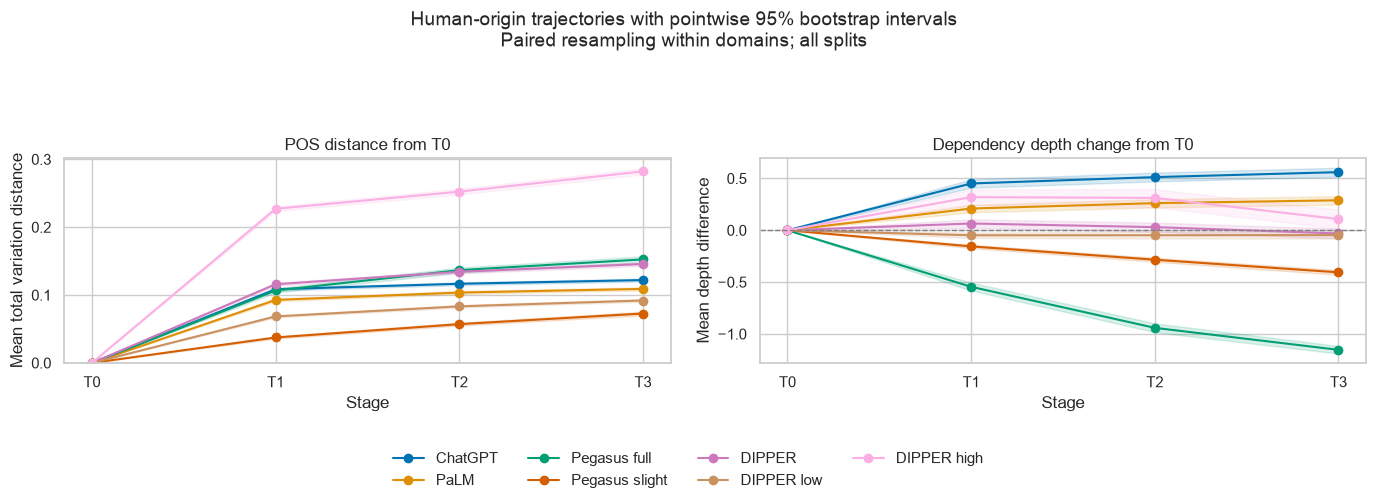

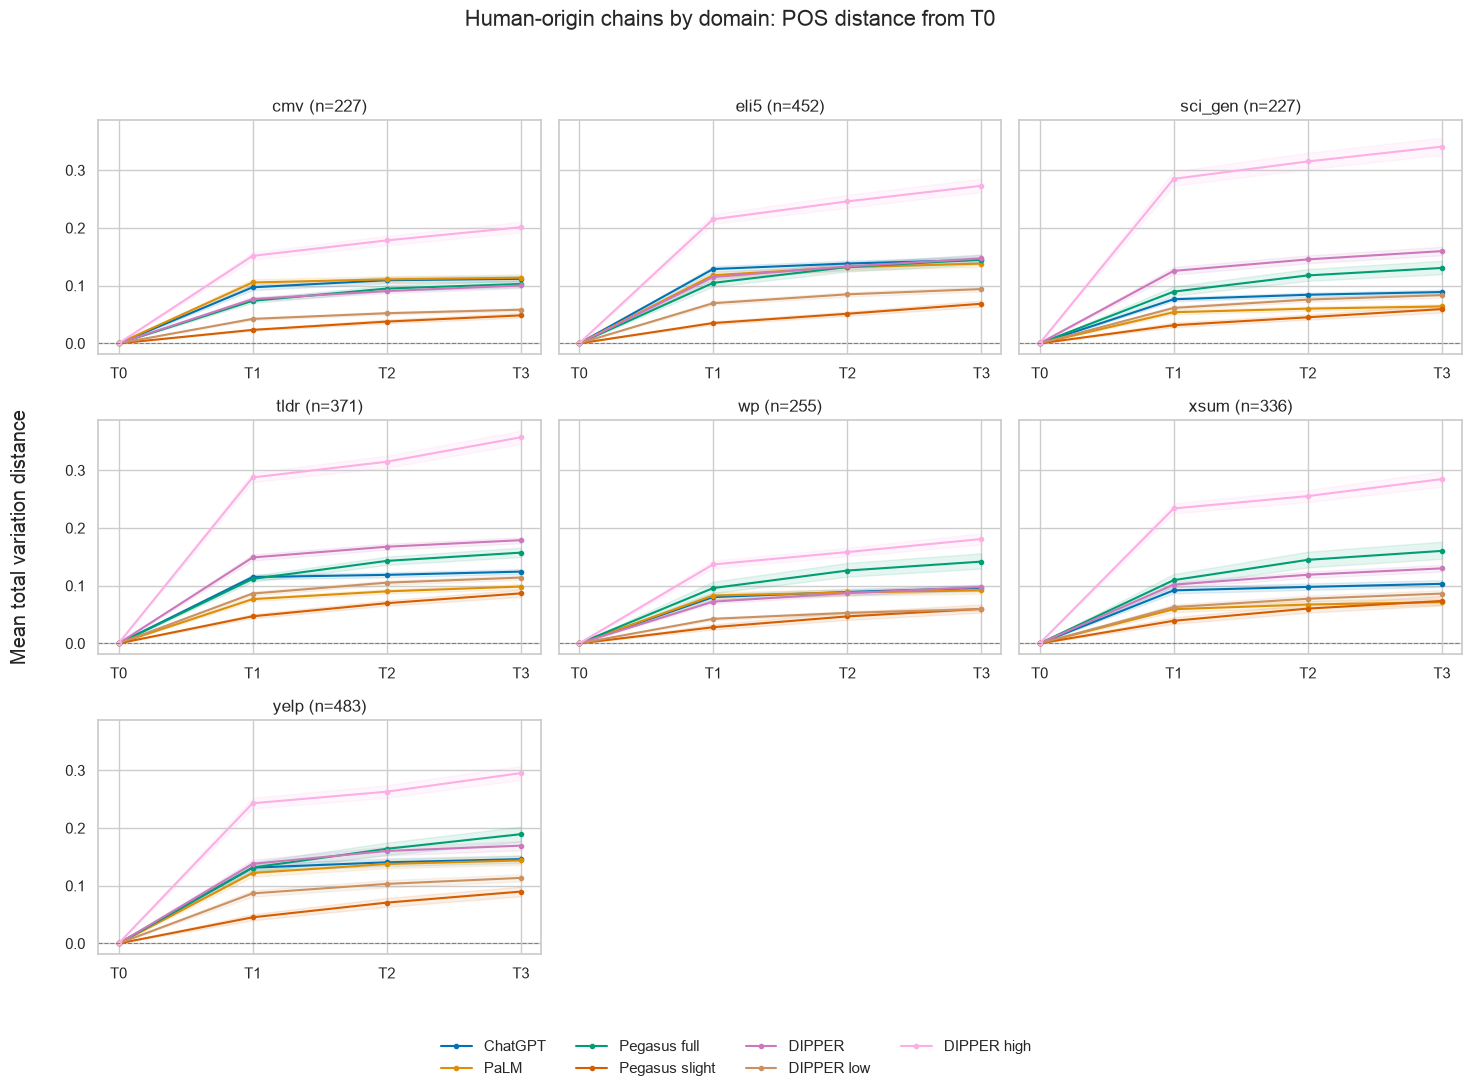

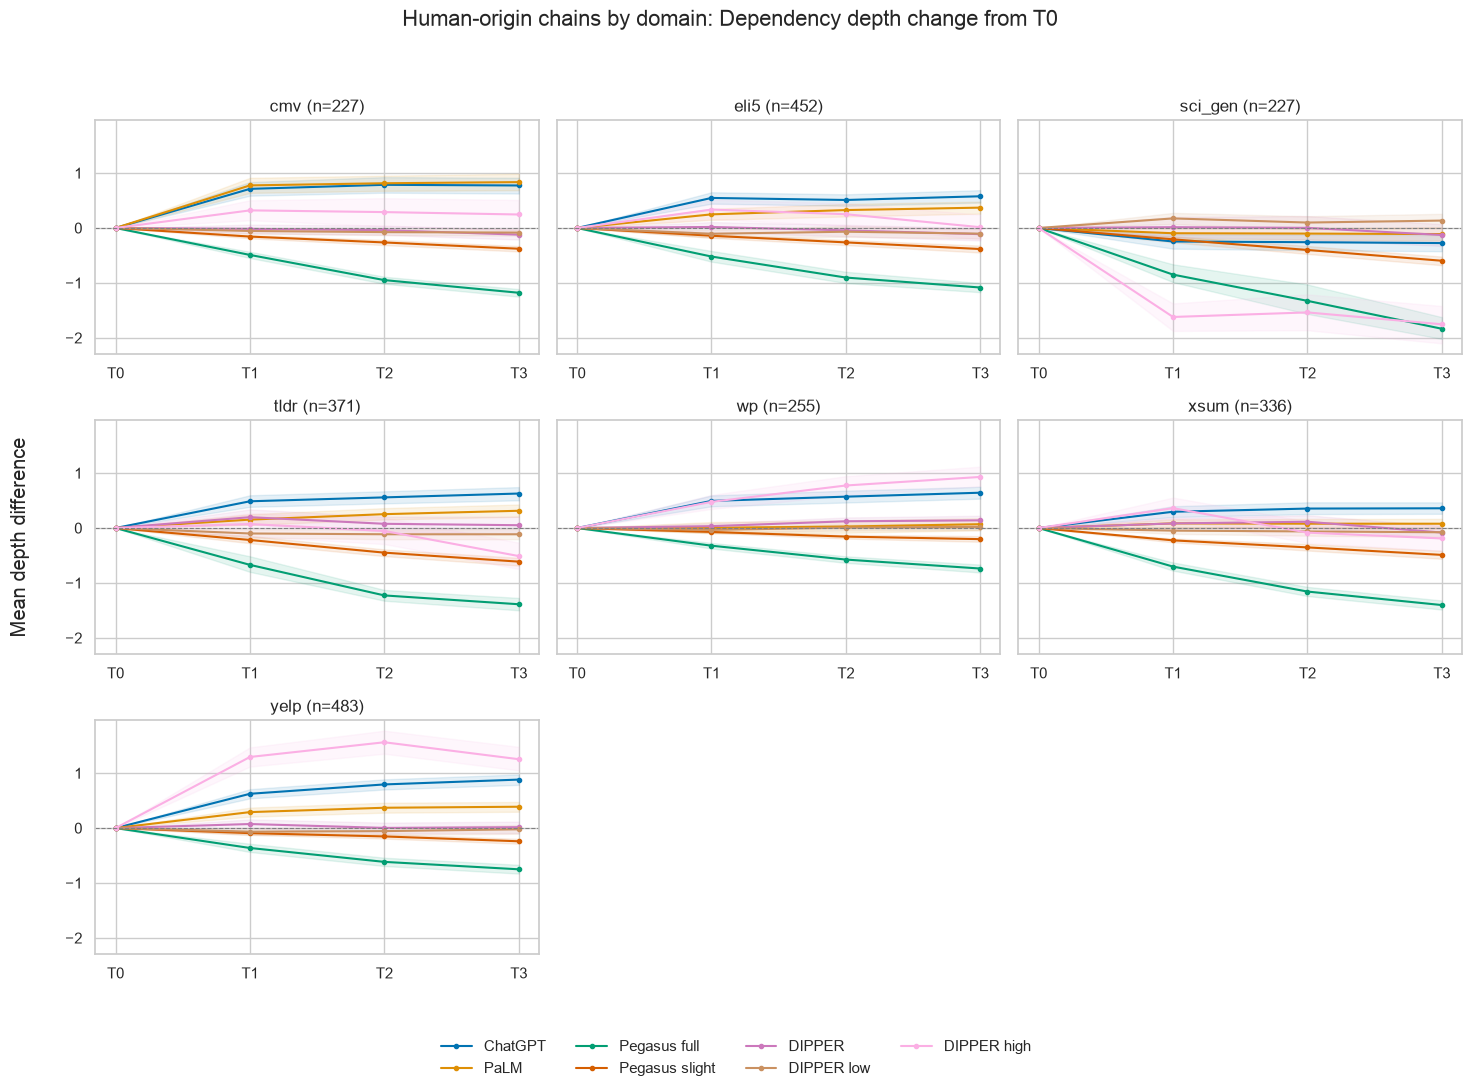

Bootstrap replicates: 2,000
Intervals are pointwise, without multiple-comparison adjustment.

T3 estimates and 95% intervals:


,configuration,iteration,metric,mean,ci_low,ci_high,n_originals
6,chatgpt,3,pos_distance,0.1220,0.1199,0.1242,2351
7,chatgpt,3,mean_dependency_depth_change,0.5604,0.5166,0.6030,2351
14,palm,3,pos_distance,0.1091,0.1068,0.1114,2351
15,palm,3,mean_dependency_depth_change,0.2891,0.2468,0.3290,2351
22,pegasus(full),3,pos_distance,0.1525,0.1480,0.1570,2351
23,pegasus(full),3,mean_dependency_depth_change,-1.1532,-1.1897,-1.1157,2351
30,pegasus(slight),3,pos_distance,0.0728,0.0701,0.0755,2351
31,pegasus(slight),3,mean_dependency_depth_change,-0.4058,-0.4291,-0.3837,2351
38,dipper,3,pos_distance,0.1457,0.1430,0.1481,2351
39,dipper,3,mean_dependency_depth_change,-0.0310,-0.0778,0.0162,2351



POS-distance changes between successive stages:


,configuration,metric,transition,mean_change,ci_low,ci_high
0,chatgpt,pos_distance,T0->T1,0.1085,0.1065,0.1105
1,chatgpt,pos_distance,T1->T2,0.0081,0.0068,0.0093
2,chatgpt,pos_distance,T2->T3,0.0054,0.0043,0.0065
6,palm,pos_distance,T0->T1,0.0928,0.0908,0.0949
7,palm,pos_distance,T1->T2,0.0108,0.0098,0.0119
8,palm,pos_distance,T2->T3,0.0054,0.0046,0.0064
12,pegasus(full),pos_distance,T0->T1,0.1067,0.1037,0.1099
13,pegasus(full),pos_distance,T1->T2,0.0299,0.0274,0.0326
14,pegasus(full),pos_distance,T2->T3,0.0159,0.0135,0.0183
18,pegasus(slight),pos_distance,T0->T1,0.0374,0.0358,0.0391


In [6]:
# Paired bootstrap with fixed domain sample sizes.
N_BOOTSTRAP = 2000

bootstrap_metrics = [
    "pos_distance",
    "mean_dependency_depth_change",
]

trajectory_columns = pd.MultiIndex.from_product(
    [configurations, range(4), bootstrap_metrics],
    names=["configuration", "iteration", "metric"],
)

wide = (
    human_style_pairs.pivot(
        index=sample_keys,
        columns=["configuration", "iteration"],
        values=bootstrap_metrics,
    )
    .reorder_levels(
        ["configuration", "iteration", None],
        axis=1,
    )
)

wide.columns = wide.columns.set_names(
    ["configuration", "iteration", "metric"]
)

wide = wide.reindex(columns=trajectory_columns).sort_index()

assert not wide.isna().any().any()
assert len(wide) == len(human_originals)

values = wide.to_numpy(dtype=float)
domain_labels = wide.index.get_level_values("domain").to_numpy()

rng = np.random.default_rng(RANDOM_SEED)
bootstrap_means = np.zeros(
    (N_BOOTSTRAP, len(trajectory_columns)),
    dtype=float,
)

domain_ci_frames = []

for domain in domains:
    domain_values = values[domain_labels == domain]
    n = len(domain_values)

    # The same resampled originals support every configuration and stage.
    weights = rng.multinomial(
        n,
        np.full(n, 1.0 / n),
        size=N_BOOTSTRAP,
    )

    domain_bootstrap = (weights @ domain_values) / n

    bootstrap_means += domain_bootstrap * (n / len(values))

    domain_result = trajectory_columns.to_frame(index=False)
    domain_result.insert(0, "domain", domain)
    domain_result["mean"] = domain_values.mean(axis=0)
    domain_result["ci_low"] = np.quantile(
        domain_bootstrap, 0.025, axis=0
    )
    domain_result["ci_high"] = np.quantile(
        domain_bootstrap, 0.975, axis=0
    )
    domain_result["n_originals"] = n

    domain_ci_frames.append(domain_result)

human_style_ci = trajectory_columns.to_frame(index=False)
human_style_ci["mean"] = values.mean(axis=0)
human_style_ci["ci_low"] = np.quantile(
    bootstrap_means, 0.025, axis=0
)
human_style_ci["ci_high"] = np.quantile(
    bootstrap_means, 0.975, axis=0
)
human_style_ci["n_originals"] = len(values)

human_style_domain_ci = pd.concat(
    domain_ci_frames,
    ignore_index=True,
)

# Estimate changes between successive stages using paired replicates.
bootstrap_lookup = {
    column: index
    for index, column in enumerate(trajectory_columns)
}

transition_rows = []

for configuration in configurations:
    for metric in bootstrap_metrics:
        for previous, current in [(0, 1), (1, 2), (2, 3)]:
            previous_index = bootstrap_lookup[
                (configuration, previous, metric)
            ]
            current_index = bootstrap_lookup[
                (configuration, current, metric)
            ]

            differences = (
                bootstrap_means[:, current_index]
                - bootstrap_means[:, previous_index]
            )

            transition_rows.append({
                "configuration": configuration,
                "metric": metric,
                "transition": f"T{previous}->T{current}",
                "mean_change": (
                    values[:, current_index].mean()
                    - values[:, previous_index].mean()
                ),
                "ci_low": np.quantile(differences, 0.025),
                "ci_high": np.quantile(differences, 0.975),
            })

human_style_transitions = pd.DataFrame(transition_rows)

for filename, table in {
    "human_style_bootstrap_ci.csv": human_style_ci,
    "human_style_domain_bootstrap_ci.csv": human_style_domain_ci,
    "human_style_transition_ci.csv": human_style_transitions,
}.items():
    table.to_csv(stylometry_dir / filename, index=False)

# Overall trajectories with pointwise 95% bootstrap intervals.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_settings = [
    ("pos_distance", "POS distance from T0", "Mean total variation distance"),
    (
        "mean_dependency_depth_change",
        "Dependency depth change from T0",
        "Mean depth difference",
    ),
]

for ax, (metric, title, ylabel) in zip(axes, plot_settings):
    for configuration in configurations:
        subset = human_style_ci.loc[
            human_style_ci["configuration"].eq(configuration)
            & human_style_ci["metric"].eq(metric)
        ].sort_values("iteration")

        x = subset["iteration"].to_numpy()
        mean = subset["mean"].to_numpy()

        ax.plot(
            x,
            mean,
            marker="o",
            color=colors[configuration],
            label=configuration_labels[configuration],
        )

        ax.fill_between(
            x,
            subset["ci_low"].to_numpy(),
            subset["ci_high"].to_numpy(),
            color=colors[configuration],
            alpha=0.15,
        )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(4), stage_order)
    ax.set_xlabel("Stage")
    ax.set_ylabel(ylabel)
    ax.set_title(title)

axes[0].set_ylim(bottom=0)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.suptitle(
    "Human-origin trajectories with pointwise 95% bootstrap intervals\n"
    "Paired resampling within domains; all splits",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0.14, 1, 0.88])
fig.savefig(
    figure_dir / "04_human_style_bootstrap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Domain-level trajectories reveal differences hidden by pooled means.
for metric, title, ylabel in plot_settings:
    fig, axes = plt.subplots(
        3, 3,
        figsize=(15, 11),
        sharex=True,
        sharey=True,
    )

    for ax, domain in zip(axes.flat, domains):
        for configuration in configurations:
            subset = human_style_domain_ci.loc[
                human_style_domain_ci["domain"].eq(domain)
                & human_style_domain_ci["configuration"].eq(configuration)
                & human_style_domain_ci["metric"].eq(metric)
            ].sort_values("iteration")

            x = subset["iteration"].to_numpy()

            ax.plot(
                x,
                subset["mean"].to_numpy(),
                marker="o",
                markersize=3,
                color=colors[configuration],
                label=configuration_labels[configuration],
            )

            ax.fill_between(
                x,
                subset["ci_low"].to_numpy(),
                subset["ci_high"].to_numpy(),
                color=colors[configuration],
                alpha=0.10,
            )

        n = int(subset["n_originals"].iloc[0])
        ax.set_title(f"{domain} (n={n})")
        ax.set_xticks(range(4), stage_order)
        ax.tick_params(labelbottom=True)
        ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    for ax in list(axes.flat)[len(domains):]:
        ax.set_visible(False)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        frameon=False,
    )

    fig.suptitle(f"Human-origin chains by domain: {title}", fontsize=16)
    fig.supylabel(ylabel)
    fig.tight_layout(rect=[0.02, 0.08, 1, 0.95])

    filename = (
        "05_human_pos_distance_by_domain.png"
        if metric == "pos_distance"
        else "06_human_depth_change_by_domain.png"
    )

    fig.savefig(
        figure_dir / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

print(f"Bootstrap replicates: {N_BOOTSTRAP:,}")
print("Intervals are pointwise, without multiple-comparison adjustment.")

print("\nT3 estimates and 95% intervals:")
display(
    human_style_ci.loc[
        human_style_ci["iteration"].eq(3)
    ].round(4)
)

print("\nPOS-distance changes between successive stages:")
display(
    human_style_transitions.loc[
        human_style_transitions["metric"].eq("pos_distance")
    ].round(4)
)

## 6. Held-out PCA trajectories and style dispersion

Fit standardization and PCA on 1,637 training Human T0 originals only. Transform all versions of 355 held-out Human originals in the shared space. The selected features comprise 13 POS proportions and three sentence/syntax statistics.

PC1 and PC2 explain approximately 37.4% of training variance. Centroid movement describes average displacement. Dispersion is the trace of the sample covariance in the full selected standardized feature space, not the apparent spread in two PCA dimensions.

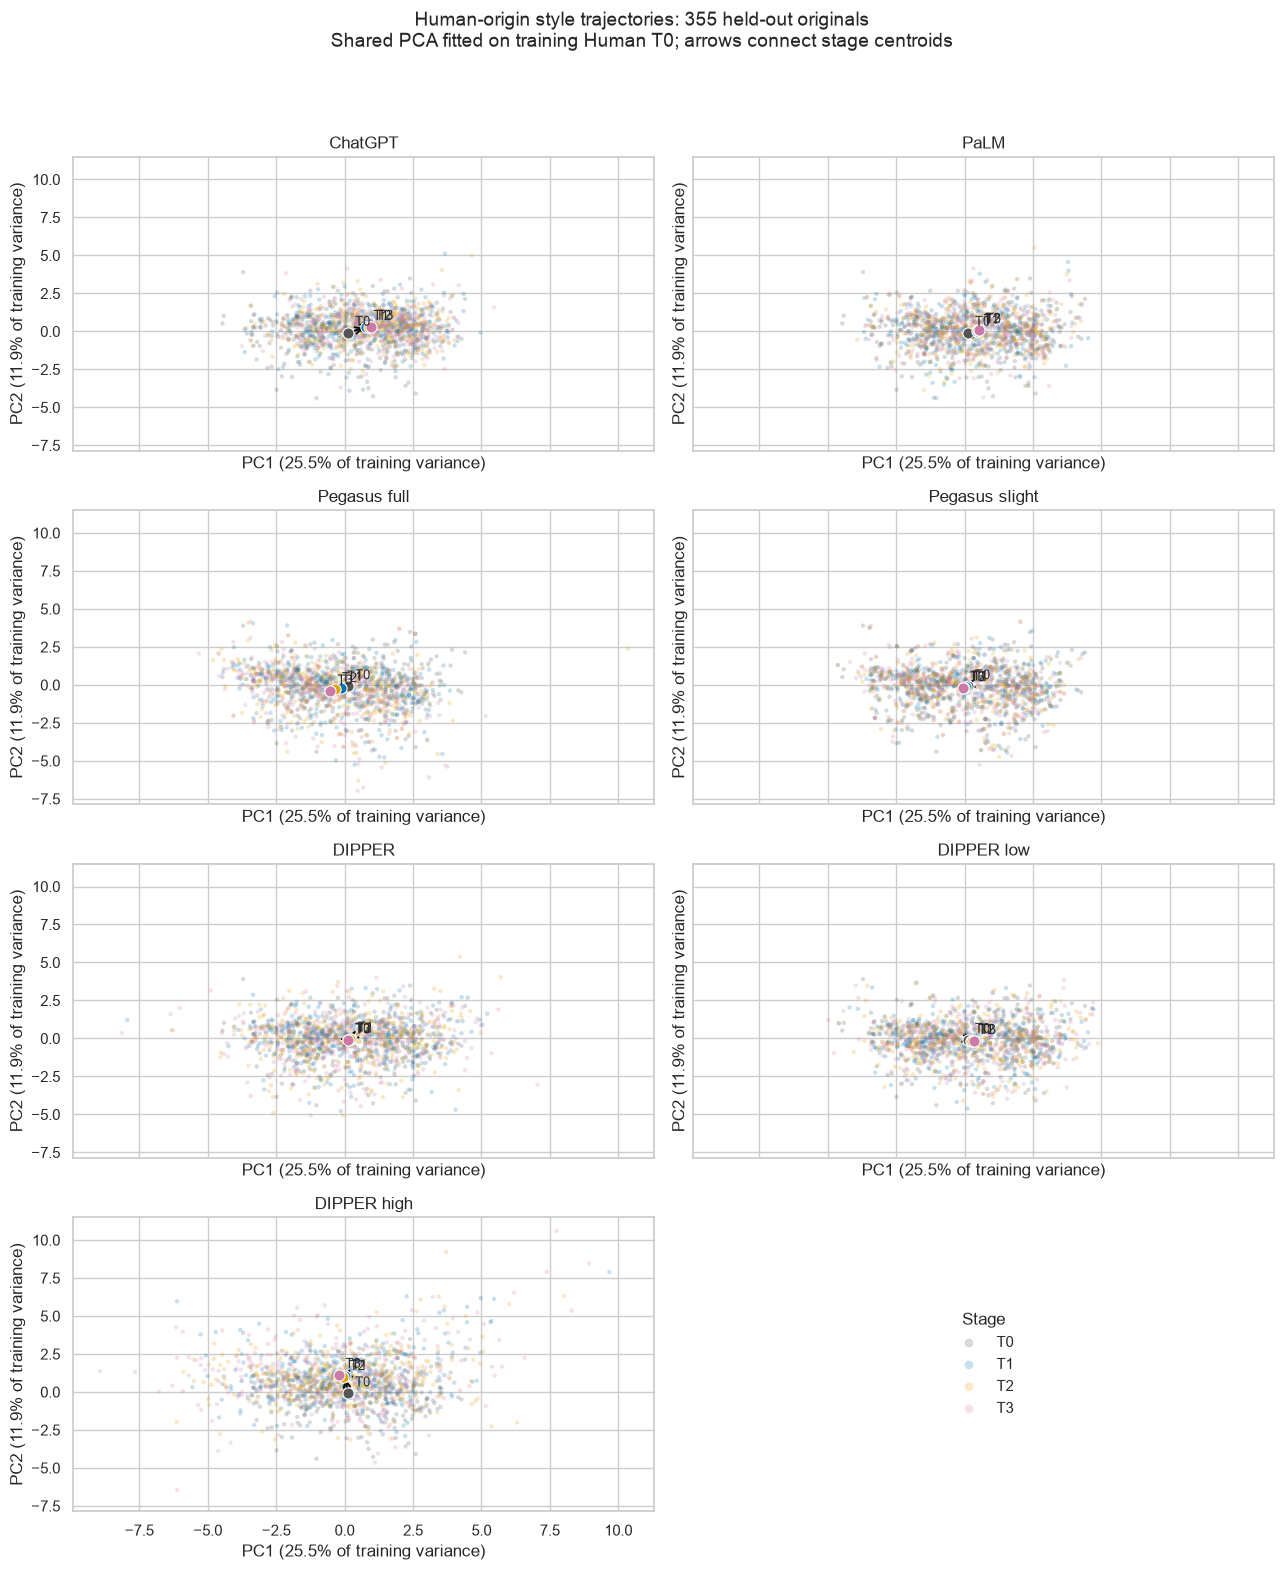

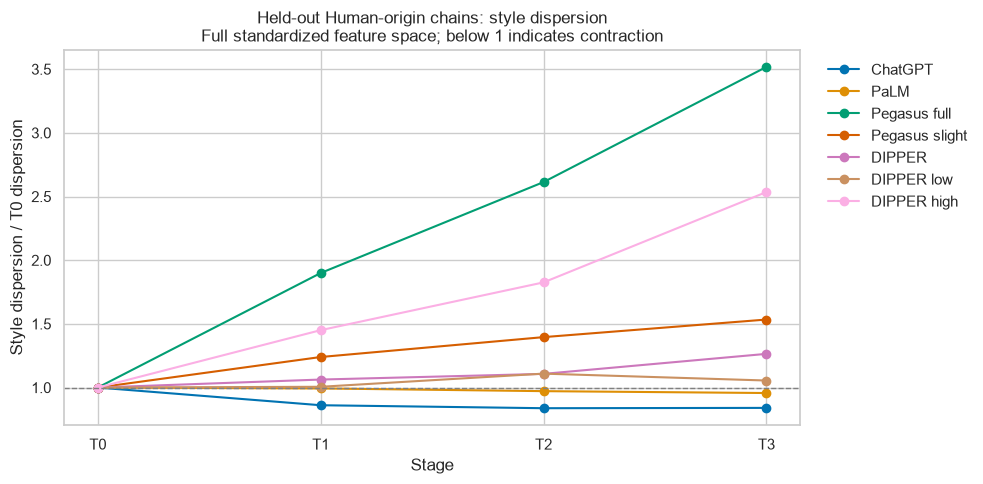

PCA fitting originals: 1,637
Held-out originals per trajectory: 355
Variance explained by PC1 and PC2: 37.4%

T3 dispersion and centroid movement:


,configuration,n_originals,dispersion_ratio,centroid_distance_from_t0
3,chatgpt,355,0.8403,1.2059
7,palm,355,0.9570,0.8091
11,pegasus(full),355,3.5175,2.3026
15,pegasus(slight),355,1.5339,0.8537
19,dipper,355,1.2645,1.1688
23,dipper(low),355,1.0551,0.7667
27,dipper(high),355,2.5351,1.9612


In [7]:
# Fit a shared style space using training Human T0 only.
trajectory_dir = output_dir / "identity_trajectory"
trajectory_dir.mkdir(exist_ok=True)

# Exclude rare POS categories and raw document-length counts.
trajectory_features = [
    f"pos_{tag}"
    for tag in pos_tags
    if tag not in {"INTJ", "SYM", "X", "PUNCT"}
] + [
    "mean_sentence_length",
    "sentence_length_cv",
    "mean_dependency_depth",
]

fit_data = human_originals.loc[
    human_originals["split"].eq("train")
].copy()

test_data = human_features.loc[
    human_features["split"].eq("test")
].copy()

fit_values = fit_data[trajectory_features].to_numpy(dtype=float)

feature_mean = fit_values.mean(axis=0)
feature_scale = fit_values.std(axis=0, ddof=0)

assert (feature_scale > 0).all(), (
    "A selected feature has zero training variance."
)

fit_standardized = (fit_values - feature_mean) / feature_scale

# PCA via singular value decomposition.
_, singular_values, components = np.linalg.svd(
    fit_standardized,
    full_matrices=False,
)

explained_variance_ratio = (
    singular_values ** 2 / np.sum(singular_values ** 2)
)

test_standardized = (
    test_data[trajectory_features].to_numpy(dtype=float)
    - feature_mean
) / feature_scale

coordinates = test_standardized @ components[:2].T

trajectory_points = test_data[
    identity_columns + ["configuration", "iteration", "stage", "split"]
].copy()

trajectory_points["PC1"] = coordinates[:, 0]
trajectory_points["PC2"] = coordinates[:, 1]

standardized_test = pd.DataFrame(
    test_standardized,
    columns=trajectory_features,
    index=pd.MultiIndex.from_frame(
        test_data[identity_columns]
    ),
)

# Save the fitted transformation for reproducibility.
pd.DataFrame({
    "feature": trajectory_features,
    "training_mean": feature_mean,
    "training_scale": feature_scale,
    "PC1_loading": components[0],
    "PC2_loading": components[1],
}).to_csv(
    trajectory_dir / "pca_feature_settings.csv",
    index=False,
)

pd.DataFrame({
    "component": np.arange(1, len(explained_variance_ratio) + 1),
    "explained_variance_ratio": explained_variance_ratio,
}).to_csv(
    trajectory_dir / "pca_explained_variance.csv",
    index=False,
)

trajectory_points.to_csv(
    trajectory_dir / "human_test_pca_coordinates.csv",
    index=False,
)

np.savez_compressed(
    trajectory_dir / "human_test_standardized_features.npz",
    features=np.array(trajectory_features, dtype=str),
    identities=test_data[identity_columns].to_numpy(dtype=str),
    values=test_standardized,
    training_mean=feature_mean,
    training_scale=feature_scale,
    pca_components=components,
)

# Plot the same test originals at every stage in one shared PCA space.
stage_colors = {
    "T0": "#555555",
    "T1": "#0072B2",
    "T2": "#E69F00",
    "T3": "#CC79A7",
}

fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 16),
    sharex=True,
    sharey=True,
)

centroid_rows = []

for ax, configuration in zip(axes.flat, configurations):
    centers = []

    for iteration, stage in enumerate(stage_order):
        version = (
            "original"
            if iteration == 0
            else "_".join([configuration] * iteration)
        )

        points = trajectory_points.loc[
            trajectory_points["version_name"].eq(version)
        ]

        center = points[["PC1", "PC2"]].mean().to_numpy()
        centers.append(center)

        centroid_rows.append({
            "configuration": configuration,
            "iteration": iteration,
            "stage": stage,
            "PC1": center[0],
            "PC2": center[1],
            "n_originals": len(points),
        })

        ax.scatter(
            points["PC1"],
            points["PC2"],
            s=10,
            alpha=0.22,
            color=stage_colors[stage],
            edgecolors="none",
            label=stage,
        )

        ax.scatter(
            *center,
            s=65,
            color=stage_colors[stage],
            edgecolors="white",
            linewidths=0.8,
            zorder=5,
        )

        ax.annotate(
            stage,
            center,
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            zorder=6,
        )

    for start, end in zip(centers[:-1], centers[1:]):
        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops={
                "arrowstyle": "->",
                "color": "black",
                "lw": 1.3,
            },
        )

    ax.set_title(configuration_labels[configuration])
    ax.set_xlabel(f"PC1 ({explained_variance_ratio[0]:.1%} of training variance)")
    ax.set_ylabel(f"PC2 ({explained_variance_ratio[1]:.1%} of training variance)")

axes.flat[-1].axis("off")

handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(
    handles,
    labels,
    loc="center",
    frameon=False,
    markerscale=2,
    title="Stage",
)

n_test = len(test_data.loc[test_data["iteration"].eq(0)])

fig.suptitle(
    f"Human-origin style trajectories: {n_test} held-out originals\n"
    "Shared PCA fitted on training Human T0; arrows connect stage centroids",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(
    figure_dir / "07_human_test_pca_trajectories.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

pd.DataFrame(centroid_rows).to_csv(
    trajectory_dir / "human_test_pca_centroids.csv",
    index=False,
)

# Measure dispersion in the full standardized feature space.
# Use sample covariance trace to describe spread around each stage's own center.
test_t0 = (
    standardized_test.xs("original", level="version_name")
    .sort_index()
)

def dispersion(matrix):
    centered = matrix - matrix.mean(axis=0)
    return np.square(centered).sum() / (len(matrix) - 1)

dispersion_rows = []

for domain in ["overall", *domains]:
    reference = (
        test_t0
        if domain == "overall"
        else test_t0.loc[
            test_t0.index.get_level_values("domain") == domain
        ]
    )

    reference_values = reference.to_numpy()
    reference_dispersion = dispersion(reference_values)

    for configuration in configurations:
        for iteration in range(4):
            version = (
                "original"
                if iteration == 0
                else "_".join([configuration] * iteration)
            )

            current = (
                standardized_test
                .xs(version, level="version_name")
                .reindex(reference.index)
            )

            assert not current.isna().any().any()

            current_values = current.to_numpy()

            dispersion_rows.append({
                "domain": domain,
                "configuration": configuration,
                "iteration": iteration,
                "stage": f"T{iteration}",
                "n_originals": len(reference),
                "dispersion": dispersion(current_values),
                "dispersion_ratio": (
                    dispersion(current_values) / reference_dispersion
                ),
                "centroid_distance_from_t0": np.linalg.norm(
                    current_values.mean(axis=0)
                    - reference_values.mean(axis=0)
                ),
            })

human_dispersion = pd.DataFrame(dispersion_rows)

assert np.allclose(
    human_dispersion.loc[
        human_dispersion["iteration"].eq(0),
        "dispersion_ratio",
    ],
    1.0,
)

human_dispersion.to_csv(
    trajectory_dir / "human_test_style_dispersion.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(10, 5))

for configuration in configurations:
    subset = human_dispersion.loc[
        human_dispersion["domain"].eq("overall")
        & human_dispersion["configuration"].eq(configuration)
    ].sort_values("iteration")

    ax.plot(
        subset["iteration"],
        subset["dispersion_ratio"],
        marker="o",
        color=colors[configuration],
        label=configuration_labels[configuration],
    )

ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(4), stage_order)
ax.set_xlabel("Stage")
ax.set_ylabel("Style dispersion / T0 dispersion")
ax.set_title(
    "Held-out Human-origin chains: style dispersion\n"
    "Full standardized feature space; below 1 indicates contraction"
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)

fig.tight_layout()
fig.savefig(
    figure_dir / "08_human_test_style_dispersion.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(f"PCA fitting originals: {len(fit_data):,}")
print(f"Held-out originals per trajectory: {n_test:,}")
print(
    "Variance explained by PC1 and PC2: "
    f"{explained_variance_ratio[:2].sum():.1%}"
)

print("\nT3 dispersion and centroid movement:")
display(
    human_dispersion.loc[
        human_dispersion["domain"].eq("overall")
        & human_dispersion["iteration"].eq(3),
        [
            "configuration",
            "n_originals",
            "dispersion_ratio",
            "centroid_distance_from_t0",
        ],
    ].round(4)
)

## 7. Dispersion uncertainty and feature-set sensitivity

Estimate paired bootstrap intervals for the rewrite-to-T0 dispersion ratio, conditioning on the fitted training transformation. Compare all selected features, POS-only features and syntax-only features. Pooled within-domain ratios provide a supplementary check excluding differences between domain centroids.

At T3, the full-feature ratio is approximately 0.84 for ChatGPT and 3.52 for Pegasus full. PaLM's interval includes 1. The evidence therefore does not support universal convergence toward a compressed machine region.

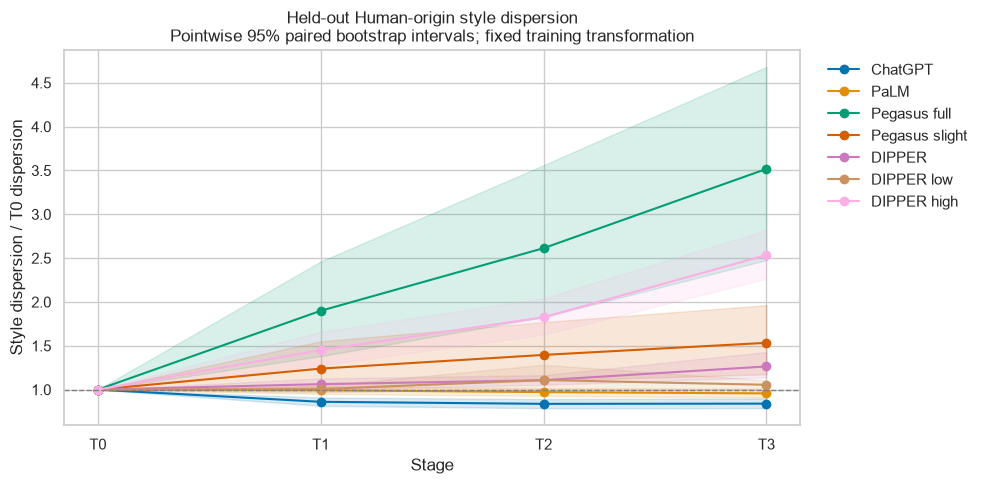

Intervals condition on the fitted training transformation and preserve test-domain sample sizes.
Pointwise intervals; no multiple-comparison adjustment.

T3 full-feature results:


,configuration,dispersion_ratio,ci_low,ci_high,within_domain_ratio,interpretation
3,chatgpt,0.8403,0.7884,0.8996,0.8709,contraction
7,palm,0.9570,0.9101,1.0085,0.9807,interval includes 1
11,pegasus(full),3.5175,2.4770,4.6810,4.2193,expansion
15,pegasus(slight),1.5339,1.1744,1.9635,1.6948,expansion
19,dipper,1.2645,1.1402,1.4288,1.3224,expansion
23,dipper(low),1.0551,1.0069,1.1071,1.0582,expansion
27,dipper(high),2.5351,2.2651,2.8194,3.2147,expansion



T3 feature-set sensitivity:


feature_set,all_style,pos_only,syntax_only
configuration,,,
chatgpt,0.8403,0.9032,0.5764
palm,0.9570,1.0189,0.6974
pegasus(full),3.5175,3.9204,1.8272
pegasus(slight),1.5339,1.6459,1.0640
dipper,1.2645,1.2720,1.2330
dipper(low),1.0551,1.0524,1.0666
dipper(high),2.5351,2.2146,3.8796


In [26]:
# Test the stability of style-dispersion estimates.
N_DISPERSION_BOOTSTRAP = 2000

feature_sets = {
    "all_style": trajectory_features,
    "pos_only": [
        feature for feature in trajectory_features
        if feature.startswith("pos_")
    ],
    "syntax_only": [
        feature for feature in trajectory_features
        if not feature.startswith("pos_")
    ],
}

reference = (
    standardized_test
    .xs("original", level="version_name")
    .sort_index()
)

reference_domains = (
    reference.index.get_level_values("domain").to_numpy()
)

domain_indices = [
    np.flatnonzero(reference_domains == domain)
    for domain in domains
]

# Reuse identical paired resamples for all stages and configurations.
rng = np.random.default_rng(RANDOM_SEED)

bootstrap_weights = np.zeros(
    (N_DISPERSION_BOOTSTRAP, len(reference)),
    dtype=float,
)

for indices in domain_indices:
    bootstrap_weights[:, indices] = rng.multinomial(
        len(indices),
        np.full(len(indices), 1.0 / len(indices)),
        size=N_DISPERSION_BOOTSTRAP,
    )


def bootstrap_spread(matrix, weights):
    """Sample covariance trace for each bootstrap replicate."""
    n = weights.sum(axis=1)
    sums = weights @ matrix
    squared_sums = weights @ np.square(matrix).sum(axis=1)

    return np.maximum(
        (squared_sums - np.square(sums).sum(axis=1) / n) / (n - 1),
        0.0,
    )


def within_domain_spread(matrix):
    """Pooled within-domain variance, excluding domain-center differences."""
    residual_sum = 0.0

    for indices in domain_indices:
        subset = matrix[indices]
        residual_sum += np.square(
            subset - subset.mean(axis=0)
        ).sum()

    return residual_sum / (len(matrix) - len(domain_indices))


dispersion_ci_rows = []

for feature_set, selected_features in feature_sets.items():
    baseline = reference[selected_features].to_numpy()

    baseline_spread = dispersion(baseline)
    baseline_bootstrap = bootstrap_spread(
        baseline,
        bootstrap_weights,
    )
    baseline_within = within_domain_spread(baseline)

    assert baseline_spread > 0
    assert baseline_within > 0
    assert (baseline_bootstrap > 0).all()

    for configuration in configurations:
        for iteration in range(4):
            version = (
                "original"
                if iteration == 0
                else "_".join([configuration] * iteration)
            )

            current = (
                standardized_test
                .xs(version, level="version_name")
                .reindex(reference.index)[selected_features]
                .to_numpy()
            )

            ratios = (
                bootstrap_spread(current, bootstrap_weights)
                / baseline_bootstrap
            )

            low, high = np.quantile(ratios, [0.025, 0.975])

            if high < 1:
                interpretation = "contraction"
            elif low > 1:
                interpretation = "expansion"
            else:
                interpretation = "interval includes 1"

            dispersion_ci_rows.append({
                "feature_set": feature_set,
                "configuration": configuration,
                "iteration": iteration,
                "stage": f"T{iteration}",
                "n_originals": len(reference),
                "dispersion_ratio": (
                    dispersion(current) / baseline_spread
                ),
                "ci_low": low,
                "ci_high": high,
                "within_domain_ratio": (
                    within_domain_spread(current) / baseline_within
                ),
                "interpretation": interpretation,
            })

dispersion_robustness = pd.DataFrame(dispersion_ci_rows)

dispersion_robustness.to_csv(
    trajectory_dir / "human_test_dispersion_robustness.csv",
    index=False,
)

# Plot full-feature dispersion with pointwise uncertainty intervals.
fig, ax = plt.subplots(figsize=(10, 5))

for configuration in configurations:
    subset = dispersion_robustness.loc[
        dispersion_robustness["feature_set"].eq("all_style")
        & dispersion_robustness["configuration"].eq(configuration)
    ].sort_values("iteration")

    x = subset["iteration"].to_numpy()

    ax.plot(
        x,
        subset["dispersion_ratio"].to_numpy(),
        marker="o",
        color=colors[configuration],
        label=configuration_labels[configuration],
    )

    ax.fill_between(
        x,
        subset["ci_low"].to_numpy(),
        subset["ci_high"].to_numpy(),
        color=colors[configuration],
        alpha=0.15,
    )

ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(4), stage_order)
ax.set_xlabel("Stage")
ax.set_ylabel("Style dispersion / T0 dispersion")
ax.set_title(
    "Held-out Human-origin style dispersion\n"
    "Pointwise 95% paired bootstrap intervals; fixed training transformation"
)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

fig.tight_layout()
fig.savefig(
    figure_dir / "09_human_test_dispersion_ci.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    "Intervals condition on the fitted training transformation "
    "and preserve test-domain sample sizes."
)
print("Pointwise intervals; no multiple-comparison adjustment.")

print("\nT3 full-feature results:")
display(
    dispersion_robustness.loc[
        dispersion_robustness["feature_set"].eq("all_style")
        & dispersion_robustness["iteration"].eq(3),
        [
            "configuration",
            "dispersion_ratio",
            "ci_low",
            "ci_high",
            "within_domain_ratio",
            "interpretation",
        ],
    ].round(4)
)

print("\nT3 feature-set sensitivity:")
display(
    dispersion_robustness.loc[
        dispersion_robustness["iteration"].eq(3)
    ].pivot(
        index="configuration",
        columns="feature_set",
        values="dispersion_ratio",
    ).reindex(configurations).round(4)
)

## 8. RQ1: Matched style and semantic trajectories

Align saved style features, BERTScore and SBERT results on the same
11,125-original encoder-compatible sample. All configurations and stages
must contain exactly the same original identities.

POS total variation and semantic distances have different scales.
Their raw values or slopes are not directly compared. This section first
constructs and validates the paired analysis table. Current grouped split
assignments are retained so that subsequent reference calibration can use
training originals separately from held-out evaluation.

In [27]:
# Build the matched RQ1 table from existing feature and semantic caches.
from pathlib import Path

import numpy as np
import pandas as pd

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

experiment_root = project_root / "experiments"
rq1_dir = experiment_root / "update2/rq1_style_content"
rq1_dir.mkdir(parents=True, exist_ok=True)

domains = ["cmv", "eli5", "sci_gen", "tldr", "wp", "xsum", "yelp"]
configurations = [
    "chatgpt", "palm", "pegasus(full)", "pegasus(slight)",
    "dipper", "dipper(low)", "dipper(high)",
]
keys = ["domain", "source", "key"]
pair_keys = keys + ["configuration", "iteration"]

manifest_path = project_root / "data/metadata/sbert_sample_manifest.csv"
feature_path = (
    experiment_root
    / "update2/style_features_full_clean_v1/full_style_features.csv"
)
split_path = (
    experiment_root / "update2/original_split_full_clean_v1.csv"
)
sbert_dir = experiment_root / "sbert_mpnet_384_v1"
bert_dir = experiment_root / "bertscore_roberta_large_L17_v1"

required_paths = [
    manifest_path,
    feature_path,
    split_path,
    *[sbert_dir / f"{domain}_pair_scores.csv" for domain in domains],
]

missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        "Required saved files are missing; no models were run:\n"
        + "\n".join(missing_paths)
    )

def read_identity_csv(path, **kwargs):
    return pd.read_csv(
        path,
        dtype={column: str for column in keys},
        keep_default_na=False,
        **kwargs,
    )

manifest = (
    read_identity_csv(manifest_path, usecols=keys)
    .sort_values(keys)
    .reset_index(drop=True)
)

assert len(manifest) == 11125
assert not manifest.duplicated(keys).any()
assert set(manifest["domain"]) == set(domains)

splits = read_identity_csv(
    split_path,
    usecols=keys + ["split"],
)

manifest = manifest.merge(
    splits,
    on=keys,
    how="left",
    validate="one_to_one",
)
assert manifest["split"].isin(["train", "validation", "test"]).all()

# Load full style features, then restrict to the common semantic sample.
features = read_identity_csv(feature_path)

required_features = keys + [
    "version_name",
    "token_count",
    "sentence_count",
    "mean_sentence_length",
    "sentence_length_cv",
    "mean_dependency_depth",
]
pos_columns = [
    column for column in features.columns if column.startswith("pos_")
]

if len(pos_columns) != 17:
    raise ValueError(f"Expected 17 POS columns, found {len(pos_columns)}.")

missing_columns = sorted(set(required_features) - set(features.columns))
if missing_columns:
    raise ValueError(f"Missing feature columns: {missing_columns}")

features = features[
    required_features + pos_columns
].merge(
    manifest,
    on=keys,
    how="inner",
    validate="many_to_one",
)

assert len(features) == len(manifest) * 22
assert not features.duplicated(keys + ["version_name"]).any()

numeric_columns = required_features[len(keys) + 1:] + pos_columns
assert np.isfinite(features[numeric_columns].to_numpy(dtype=float)).all()
assert np.allclose(features[pos_columns].sum(axis=1), 1.0)

baseline = (
    features.loc[features["version_name"].eq("original")]
    .set_index(keys)
    .sort_index()
)

assert len(baseline) == len(manifest)

style_rows = []

for configuration in configurations:
    for iteration in [1, 2, 3]:
        version = "_".join([configuration] * iteration)

        current = (
            features.loc[features["version_name"].eq(version)]
            .set_index(keys)
            .sort_index()
        )

        assert current.index.equals(baseline.index)

        output = baseline.index.to_frame(index=False)
        output["configuration"] = configuration
        output["iteration"] = iteration
        output["split"] = baseline["split"].to_numpy()

        output["pos_distance"] = (
            0.5
            * np.abs(
                current[pos_columns].to_numpy(dtype=float)
                - baseline[pos_columns].to_numpy(dtype=float)
            ).sum(axis=1)
        )

        for column in [
            "token_count",
            "sentence_count",
            "mean_sentence_length",
            "sentence_length_cv",
            "mean_dependency_depth",
        ]:
            output[f"t0_{column}"] = baseline[column].to_numpy()
            output[column] = current[column].to_numpy()
            output[f"{column}_change"] = (
                current[column].to_numpy()
                - baseline[column].to_numpy()
            )

        output["token_count_ratio"] = (
            output["token_count"] / output["t0_token_count"]
        )
        output["both_multisentence"] = (
            output["t0_sentence_count"].ge(2)
            & output["sentence_count"].ge(2)
        )
        style_rows.append(output)

style_pairs = pd.concat(style_rows, ignore_index=True)
assert len(style_pairs) == 233625

# Load saved SBERT pair scores.
sbert = pd.concat(
    [
        read_identity_csv(
            sbert_dir / f"{domain}_pair_scores.csv",
            usecols=pair_keys + ["SBERT_cosine"],
        )
        for domain in domains
    ],
    ignore_index=True,
)

# Load only per-text BERTScore checkpoint files.
bert_frames = []
bert_file_count = 0

for domain in domains:
    paths = sorted((bert_dir / domain).glob("*.csv"))
    if not paths:
        raise FileNotFoundError(
            f"No saved BERTScore checkpoints found for {domain}. "
            "No model inference was performed."
        )

    for path in paths:
        bert_frames.append(
            read_identity_csv(
                path,
                usecols=pair_keys + ["BERTScore_F1"],
            )
        )
        bert_file_count += 1

bert = pd.concat(bert_frames, ignore_index=True).merge(
    manifest[keys],
    on=keys,
    how="inner",
    validate="many_to_one",
)

for name, table in [("SBERT", sbert), ("BERTScore", bert)]:
    table["iteration"] = pd.to_numeric(
        table["iteration"], errors="raise"
    ).astype(int)

    assert len(table) == 233625, f"Unexpected {name} pair count."
    assert not table.duplicated(pair_keys).any(), (
        f"Duplicate {name} identities."
    )

matched = style_pairs.merge(
    sbert,
    on=pair_keys,
    how="outer",
    validate="one_to_one",
    indicator=True,
)
assert matched["_merge"].eq("both").all(), "SBERT alignment failed."
matched = matched.drop(columns="_merge")

matched = matched.merge(
    bert,
    on=pair_keys,
    how="outer",
    validate="one_to_one",
    indicator=True,
)
assert matched["_merge"].eq("both").all(), "BERTScore alignment failed."
matched = matched.drop(columns="_merge")

assert np.isfinite(
    matched[["pos_distance", "SBERT_cosine", "BERTScore_F1"]]
    .to_numpy(dtype=float)
).all()
assert matched["SBERT_cosine"].between(-1.00001, 1.00001).all()
assert matched["pos_distance"].between(0, 1.00001).all()

# Preserve raw semantic scores; do not rescale or clip them.
matched["sbert_distance"] = 1.0 - matched["SBERT_cosine"]
matched["bertscore_distance"] = 1.0 - matched["BERTScore_F1"]

expected_ids = set(
    manifest[keys].itertuples(index=False, name=None)
)

for _, subset in matched.groupby(["configuration", "iteration"]):
    assert set(
        subset[keys].itertuples(index=False, name=None)
    ) == expected_ids

matched = matched.sort_values(pair_keys).reset_index(drop=True)

summary = (
    matched.groupby(["configuration", "iteration"])
    .agg(
        n_originals=("key", "size"),
        mean_pos_distance=("pos_distance", "mean"),
        mean_dependency_depth_change=(
            "mean_dependency_depth_change", "mean"
        ),
        mean_BERTScore_F1=("BERTScore_F1", "mean"),
        mean_SBERT_cosine=("SBERT_cosine", "mean"),
    )
    .reset_index()
)

# Inventory the cached T0 embeddings needed for reference calibration.
embedding_rows = []

for domain in domains:
    paths = sorted(
        (sbert_dir / domain / "embeddings").glob("original_*.npz")
    )

    embedding_rows.append({
        "domain": domain,
        "t0_embedding_files": len(paths),
        "total_size_mb": sum(
            path.stat().st_size for path in paths
        ) / 1024**2,
    })

embedding_inventory = pd.DataFrame(embedding_rows)

matched.to_csv(rq1_dir / "matched_style_semantic_pairs.csv", index=False)
manifest.to_csv(rq1_dir / "matched_original_manifest.csv", index=False)
summary.to_csv(rq1_dir / "matched_raw_summary.csv", index=False)
embedding_inventory.to_csv(
    rq1_dir / "t0_embedding_inventory.csv",
    index=False,
)

print(f"Common originals: {len(manifest):,}")
print(f"Matched comparisons: {len(matched):,}")
print(f"BERTScore checkpoint files loaded: {bert_file_count:,}")
print("Every configuration and round uses identical original identities.")
print("No feature extraction, semantic inference, or classifier training performed.")

print("\nCommon-sample split counts:")
display(
    manifest.groupby("split").size()
    .rename("originals")
    .to_frame()
)

print("\nT0 embedding cache availability:")
display(embedding_inventory.round(2))

print("\nMatched raw summaries; metric magnitudes are not directly comparable:")
display(summary.round(4))

print(f"\nRQ1 tables saved to: {rq1_dir}")

Common originals: 11,125
Matched comparisons: 233,625
BERTScore checkpoint files loaded: 2,688
Every configuration and round uses identical original identities.
No feature extraction, semantic inference, or classifier training performed.

Common-sample split counts:


,originals
split,
test,1711
train,7737
validation,1677



T0 embedding cache availability:


,domain,t0_embedding_files,total_size_mb
0,cmv,2,1.96
1,eli5,5,5.49
2,sci_gen,3,3.29
3,tldr,4,5.04
4,wp,2,2.39
5,xsum,5,5.74
6,yelp,5,6.45



Matched raw summaries; metric magnitudes are not directly comparable:


,configuration,iteration,n_originals,mean_pos_distance,mean_dependency_depth_change,mean_BERTScore_F1,mean_SBERT_cosine
0,chatgpt,1,11125,0.1150,0.2188,0.9347,0.9148
1,chatgpt,2,11125,0.1230,0.2466,0.9277,0.9005
2,chatgpt,3,11125,0.1297,0.2991,0.9219,0.8889
3,dipper,1,11125,0.1337,-0.0547,0.9077,0.8150
4,dipper,2,11125,0.1553,-0.1795,0.8926,0.7574
5,dipper,3,11125,0.1691,-0.2639,0.8812,0.7078
6,dipper(high),1,11125,0.2600,-0.0971,0.8114,0.1287
7,dipper(high),2,11125,0.2914,-0.1621,0.8106,0.0706
8,dipper(high),3,11125,0.3236,-0.3663,0.8114,0.0515
9,dipper(low),1,11125,0.0785,-0.0656,0.9565,0.9315



RQ1 tables saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/rq1_style_content


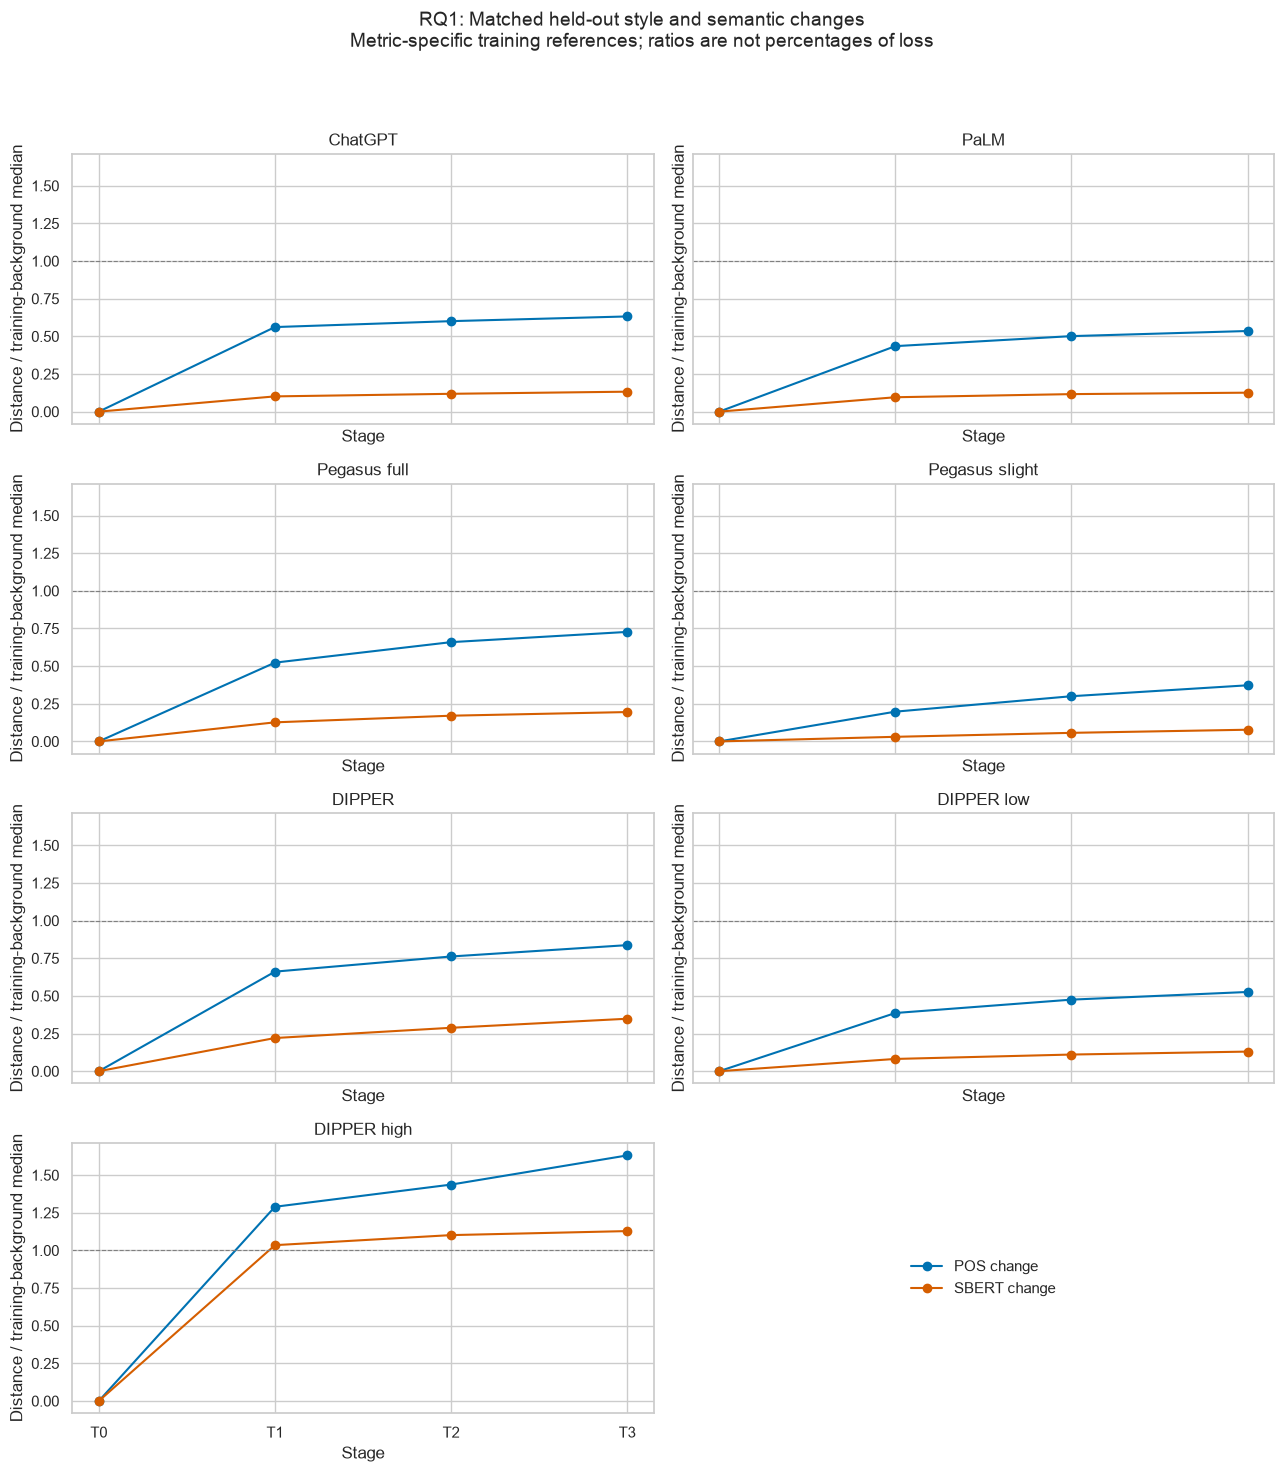

Held-out originals per configuration: 1,711
Held-out document groups: 444
Training-reference strata: 49
Positive gap: greater background-normalized POS change.
Negative gap: greater background-normalized SBERT change.
Ratios are not percentages of stylistic or semantic loss.
Intervals are pointwise and condition on fixed training references.
No semantic model inference, feature extraction, or classifier training.

T3 comparisons: median reference and mean-reference sensitivity


,reference_statistic,configuration,iteration,n_originals,pos_relative,semantic_relative,gap,ci_low,ci_high
2,median,chatgpt,3,1711,0.6321,0.1325,0.4996,0.4864,0.5135
5,median,palm,3,1711,0.5354,0.1259,0.4095,0.3960,0.4237
8,median,pegasus(full),3,1711,0.7272,0.1950,0.5322,0.5095,0.5569
11,median,pegasus(slight),3,1711,0.3727,0.0777,0.2950,0.2826,0.3085
14,median,dipper,3,1711,0.8371,0.3484,0.4887,0.4703,0.5068
17,median,dipper(low),3,1711,0.5261,0.1302,0.3959,0.3829,0.4092
20,median,dipper(high),3,1711,1.6307,1.1282,0.5024,0.4687,0.5349
23,mean,chatgpt,3,1711,0.5975,0.1342,0.4633,0.4505,0.4765
26,mean,palm,3,1711,0.5054,0.1275,0.3780,0.3653,0.3913
29,mean,pegasus(full),3,1711,0.6877,0.1977,0.4900,0.4685,0.5135



Accumulated trajectory and later growth-rate comparisons


,reference_statistic,configuration,comparison,n_originals,estimate,ci_low,ci_high
0,median,chatgpt,mean_trajectory_gap_T0_T3,1711,0.3975,0.3878,0.4082
1,median,chatgpt,growth_rate_gap_T1_T3,1711,0.0196,0.0157,0.0233
2,median,palm,mean_trajectory_gap_T0_T3,1711,0.3097,0.2992,0.3205
3,median,palm,growth_rate_gap_T1_T3,1711,0.0351,0.0311,0.0389
4,median,pegasus(full),mean_trajectory_gap_T0_T3,1711,0.3836,0.3705,0.3979
5,median,pegasus(full),growth_rate_gap_T1_T3,1711,0.0679,0.0593,0.0783
6,median,pegasus(slight),mean_trajectory_gap_T0_T3,1711,0.1859,0.1778,0.1942
7,median,pegasus(slight),growth_rate_gap_T1_T3,1711,0.0640,0.0593,0.0687
8,median,dipper,mean_trajectory_gap_T0_T3,1711,0.3862,0.3750,0.3975
9,median,dipper,growth_rate_gap_T1_T3,1711,0.0239,0.0165,0.0315



Results saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/rq1_style_content


In [28]:
# Compare background-normalized POS and SBERT changes on held-out originals.
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

root = project_root / "experiments"
rq1_dir = root / "update2/rq1_style_content"
figure_dir = project_root / "figures/update2"
figure_dir.mkdir(parents=True, exist_ok=True)

keys = ["domain", "source", "key"]
domains = ["cmv", "eli5", "sci_gen", "tldr", "wp", "xsum", "yelp"]
labels = {
    "chatgpt": "ChatGPT",
    "palm": "PaLM",
    "pegasus(full)": "Pegasus full",
    "pegasus(slight)": "Pegasus slight",
    "dipper": "DIPPER",
    "dipper(low)": "DIPPER low",
    "dipper(high)": "DIPPER high",
}
configs = list(labels)

seed = 6120
max_reference_pairs = 5000
n_bootstrap = 2000

manifest = pd.read_csv(
    rq1_dir / "matched_original_manifest.csv",
    dtype={column: str for column in keys},
    keep_default_na=False,
)
pairs = pd.read_csv(
    rq1_dir / "matched_style_semantic_pairs.csv",
    dtype={column: str for column in keys},
    keep_default_na=False,
)

assert len(manifest) == 11125
assert not manifest.duplicated(keys).any()
assert len(pairs) == 233625
assert not pairs.duplicated(
    keys + ["configuration", "iteration"]
).any()

pos_tags = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ",
    "NOUN", "NUM", "PART", "PRON", "PROPN", "SCONJ",
    "SYM", "VERB", "X", "PUNCT",
]
pos_columns = [f"pos_{tag}" for tag in pos_tags]

features = pd.read_csv(
    root / "update2/style_features_full_clean_v1/full_style_features.csv",
    usecols=keys + ["version_name"] + pos_columns,
    dtype={column: str for column in keys},
    keep_default_na=False,
)
t0 = features.loc[
    features["version_name"].eq("original"),
    keys + pos_columns,
].merge(
    manifest,
    on=keys,
    how="inner",
    validate="one_to_one",
)
assert len(t0) == len(manifest)
t0 = t0.set_index(keys).sort_index()

# Load cached T0 embeddings only; no encoder is loaded.
embedding_arrays = []
embedding_id_rows = []

for domain in domains:
    paths = sorted(
        (root / "sbert_mpnet_384_v1" / domain / "embeddings")
        .glob("original_*.npz")
    )
    if not paths:
        raise FileNotFoundError(f"Missing T0 embedding cache: {domain}")

    for path in paths:
        with np.load(path, allow_pickle=False) as saved:
            sources = saved["sources"].astype(str)
            document_keys = saved["keys"].astype(str)
            matrix = saved["embeddings"].astype(np.float64)

        assert len(sources) == len(document_keys) == len(matrix)
        assert np.isfinite(matrix).all()
        assert np.allclose(
            np.linalg.norm(matrix, axis=1), 1.0, atol=1e-4
        )

        embedding_arrays.append(matrix)
        embedding_id_rows.extend(
            (domain, source, key)
            for source, key in zip(sources, document_keys)
        )

embedding_index = pd.MultiIndex.from_tuples(
    embedding_id_rows, names=keys
)
assert not embedding_index.duplicated().any()

all_embeddings = np.concatenate(embedding_arrays, axis=0)
positions = embedding_index.get_indexer(t0.index)
assert (positions >= 0).all()
assert len(embedding_index) == len(t0)

t0_embeddings = all_embeddings[positions]
t0_pos = t0[pos_columns].to_numpy(dtype=float)

# Build training-only reference distances within domain/source strata.
rng = np.random.default_rng(seed)
reference_rows = []

for (domain, source), subset in t0.reset_index().groupby(
    ["domain", "source"], sort=True
):
    train_subset = subset.loc[subset["split"].eq("train")]
    train_index = pd.MultiIndex.from_frame(train_subset[keys])
    train_positions = t0.index.get_indexer(train_index)

    n = len(train_positions)
    if n < 2:
        raise ValueError(
            f"Insufficient training originals for reference: {domain}, {source}"
        )

    # Unique unordered pairs of different originals.
    left, right = np.triu_indices(n, k=1)
    total_possible = len(left)

    if total_possible > max_reference_pairs:
        selection = rng.choice(
            total_possible,
            size=max_reference_pairs,
            replace=False,
        )
        left = left[selection]
        right = right[selection]

    a = train_positions[left]
    b = train_positions[right]

    pos_reference = 0.5 * np.abs(t0_pos[a] - t0_pos[b]).sum(axis=1)
    semantic_reference = 1.0 - np.einsum(
        "ij,ij->i", t0_embeddings[a], t0_embeddings[b]
    )

    row = {
        "domain": domain,
        "source": source,
        "training_originals": n,
        "reference_pairs": len(a),
    }

    for metric, values in [
        ("pos", pos_reference),
        ("sbert", semantic_reference),
    ]:
        row[f"{metric}_median"] = float(np.median(values))
        row[f"{metric}_mean"] = float(np.mean(values))

        if (
            row[f"{metric}_median"] <= 1e-8
            or row[f"{metric}_mean"] <= 1e-8
        ):
            raise ValueError(
                f"Degenerate {metric} reference: {domain}, {source}"
            )

    reference_rows.append(row)

references = pd.DataFrame(reference_rows)
assert len(references) == 49

# Calibrate only held-out pairs using training reference values.
test = pairs.loc[pairs["split"].eq("test")].merge(
    references,
    on=["domain", "source"],
    how="left",
    validate="many_to_one",
)
assert test["pos_median"].notna().all()
assert test["sbert_median"].notna().all()

test_ids = (
    manifest.loc[manifest["split"].eq("test"), keys]
    .sort_values(keys)
    .reset_index(drop=True)
)
assert len(test_ids) == 1711

for denominator in ["median", "mean"]:
    test[f"pos_relative_{denominator}"] = (
        test["pos_distance"] / test[f"pos_{denominator}"]
    )
    test[f"semantic_relative_{denominator}"] = (
        test["sbert_distance"] / test[f"sbert_{denominator}"]
    )
    test[f"gap_{denominator}"] = (
        test[f"pos_relative_{denominator}"]
        - test[f"semantic_relative_{denominator}"]
    )

# Positive gaps indicate greater background-normalized POS change.
# Preserve source variants in the same document-group bootstrap.
groups = (
    test_ids[["domain", "key"]]
    .drop_duplicates()
    .sort_values(["domain", "key"])
    .reset_index(drop=True)
)
group_index = pd.MultiIndex.from_frame(groups)

rng_boot = np.random.default_rng(seed)
weights = np.zeros((n_bootstrap, len(groups)), dtype=float)

for domain in domains:
    indices = np.flatnonzero(groups["domain"].eq(domain).to_numpy())
    if len(indices) == 0:
        raise ValueError(f"No held-out groups in domain: {domain}")

    weights[:, indices] = rng_boot.multinomial(
        len(indices),
        np.full(len(indices), 1.0 / len(indices)),
        size=n_bootstrap,
    )

def paired_mean_interval(frame, values):
    positions = group_index.get_indexer(
        pd.MultiIndex.from_frame(frame[["domain", "key"]])
    )
    assert (positions >= 0).all()

    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()

    sums = np.bincount(
        positions, weights=values, minlength=len(groups)
    )
    counts = np.bincount(positions, minlength=len(groups))

    bootstrap_counts = weights @ counts
    assert (bootstrap_counts > 0).all()

    resampled = (weights @ sums) / bootstrap_counts
    low, high = np.quantile(resampled, [0.025, 0.975])
    return float(values.mean()), float(low), float(high)

stage_rows = []
trajectory_rows = []

for denominator in ["median", "mean"]:
    for configuration in configs:
        subset = test.loc[
            test["configuration"].eq(configuration)
        ].copy()

        for iteration in [1, 2, 3]:
            current = subset.loc[
                subset["iteration"].eq(iteration)
            ].sort_values(keys)

            assert len(current) == len(test_ids)
            assert current[keys].reset_index(drop=True).equals(test_ids)

            gap, low, high = paired_mean_interval(
                current, current[f"gap_{denominator}"]
            )

            stage_rows.append({
                "reference_statistic": denominator,
                "configuration": configuration,
                "iteration": iteration,
                "n_originals": len(current),
                "pos_relative": current[
                    f"pos_relative_{denominator}"
                ].mean(),
                "semantic_relative": current[
                    f"semantic_relative_{denominator}"
                ].mean(),
                "gap": gap,
                "ci_low": low,
                "ci_high": high,
            })

        wide = subset.pivot(
            index=keys,
            columns="iteration",
            values=f"gap_{denominator}",
        ).reindex(pd.MultiIndex.from_frame(test_ids))
        assert wide.notna().all().all()

        # T0 relative distances are exactly zero by definition.
        # Trapezoidal AUC over T0-T3, divided by the interval length.
        auc_gap = (wide[1] + wide[2] + 0.5 * wide[3]) / 3.0

        # Distinguish accumulated departure from subsequent growth.
        later_slope_gap = (wide[3] - wide[1]) / 2.0

        for comparison, values in [
            ("mean_trajectory_gap_T0_T3", auc_gap),
            ("growth_rate_gap_T1_T3", later_slope_gap),
        ]:
            estimate, low, high = paired_mean_interval(
                test_ids, values.to_numpy()
            )
            trajectory_rows.append({
                "reference_statistic": denominator,
                "configuration": configuration,
                "comparison": comparison,
                "n_originals": len(test_ids),
                "estimate": estimate,
                "ci_low": low,
                "ci_high": high,
            })

stage_results = pd.DataFrame(stage_rows)
trajectory_results = pd.DataFrame(trajectory_rows)

references.to_csv(
    rq1_dir / "training_background_references.csv", index=False
)
test.to_csv(
    rq1_dir / "heldout_background_normalized_pairs.csv", index=False
)
stage_results.to_csv(
    rq1_dir / "heldout_relative_change_ci.csv", index=False
)
trajectory_results.to_csv(
    rq1_dir / "heldout_trajectory_comparisons.csv", index=False
)

settings = {
    "seed": seed,
    "bootstrap_replicates": n_bootstrap,
    "test_originals": len(test_ids),
    "test_document_groups": len(groups),
    "reference_strata": ["domain", "source"],
    "reference_population": "training originals in matched semantic sample",
    "max_unique_reference_pairs_per_stratum": max_reference_pairs,
    "primary_reference": "median distance between distinct training originals",
    "sensitivity_reference": "mean distance between distinct training originals",
    "style_proxy": "17-category POS total variation",
    "semantic_proxy": "1 minus cached SBERT cosine",
    "bootstrap": "paired document groups within domains",
    "reference_uncertainty": "not included; intervals condition on references",
    "multiple_comparison_adjustment": False,
}
(rq1_dir / "background_comparison_settings.json").write_text(
    json.dumps(settings, indent=2) + "\n",
    encoding="utf-8",
)

# Show the operationally normalized trajectories.
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(4, 2, figsize=(13, 15), sharex=True, sharey=True)

for ax, configuration in zip(axes.flat, configs):
    current = stage_results.loc[
        stage_results["reference_statistic"].eq("median")
        & stage_results["configuration"].eq(configuration)
    ].sort_values("iteration")

    for column, label, color in [
        ("pos_relative", "POS change", "#0072B2"),
        ("semantic_relative", "SBERT change", "#D55E00"),
    ]:
        ax.plot(
            [0, 1, 2, 3],
            [0.0, *current[column].tolist()],
            marker="o",
            label=label,
            color=color,
        )

    ax.axhline(1, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(labels[configuration])
    ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"])
    ax.set_xlabel("Stage")
    ax.set_ylabel("Distance / training-background median")

axes.flat[-1].axis("off")
handles, legend_labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(
    handles, legend_labels, loc="center", frameon=False
)

fig.suptitle(
    "RQ1: Matched held-out style and semantic changes\n"
    "Metric-specific training references; ratios are not percentages of loss",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(
    figure_dir / "18_rq1_background_normalized_trajectories.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(f"Held-out originals per configuration: {len(test_ids):,}")
print(f"Held-out document groups: {len(groups):,}")
print(f"Training-reference strata: {len(references)}")
print("Positive gap: greater background-normalized POS change.")
print("Negative gap: greater background-normalized SBERT change.")
print("Ratios are not percentages of stylistic or semantic loss.")
print("Intervals are pointwise and condition on fixed training references.")
print("No semantic model inference, feature extraction, or classifier training.")

print("\nT3 comparisons: median reference and mean-reference sensitivity")
display(
    stage_results.loc[stage_results["iteration"].eq(3)].round(4)
)

print("\nAccumulated trajectory and later growth-rate comparisons")
display(trajectory_results.round(4))

print(f"\nResults saved to: {rq1_dir}")

### RQ1 findings: relative stylistic and semantic change

On 1,711 held-out originals from 444 document groups, we compared POS total
variation with SBERT cosine distance after dividing each by its corresponding
training-background reference within domain and original-source category.

At T3, background-normalized POS distance exceeds background-normalized SBERT
distance for all seven configurations. Every pointwise 95% paired document-group
bootstrap interval for the difference lies above zero.

The average T1-to-T3 increase per round is also greater for normalized POS
distance in all seven configurations. Positive trajectory-integrated gaps
provide complementary evidence of greater accumulated relative POS departure.
These directions persist when background means replace background medians.

Thus, under this operational definition, the results support faster relative
change in the POS-based style proxy than in the SBERT-based semantic proxy.
This is a comparison relative to metric-specific background variation, not a
comparison of percentages of style or meaning lost.

DIPPER high also shows substantial semantic departure and cannot be assumed
to preserve content. The same direction of comparison holds separately for
the other six configurations.

The findings concern pooled means over the matched encoder-compatible test
sample, not every document or every domain individually. POS captures only
part of style, and SBERT is an imperfect semantic measure. Intervals are
pointwise, have no multiple-comparison adjustment, and condition on fixed
training-reference estimates. Mean-reference sensitivity does not establish
robustness to all possible calibration methods. BERTScore remains a
supplementary metric and is not included in this normalized comparison.

## 9. RQ2: Original-source attribution

Train a standardized logistic-regression classifier on training T0 only. Select regularization using validation T0 Macro-F1, then evaluate the fixed classifier on held-out T0-T3. Report accuracy, Macro-F1, dummy baselines and source-level recall.

The seven labels are original source categories, including Human and six LLM categories; they are not individual human authors. T0 test Macro-F1 is approximately 0.423. Performance decreases after rewriting, with substantial differences across configurations.

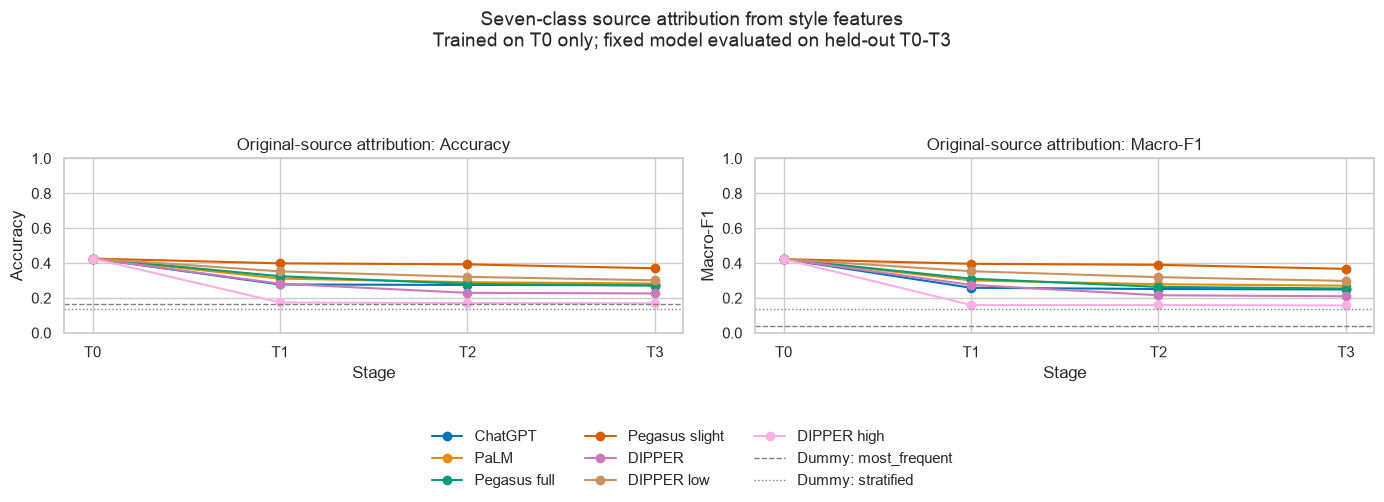

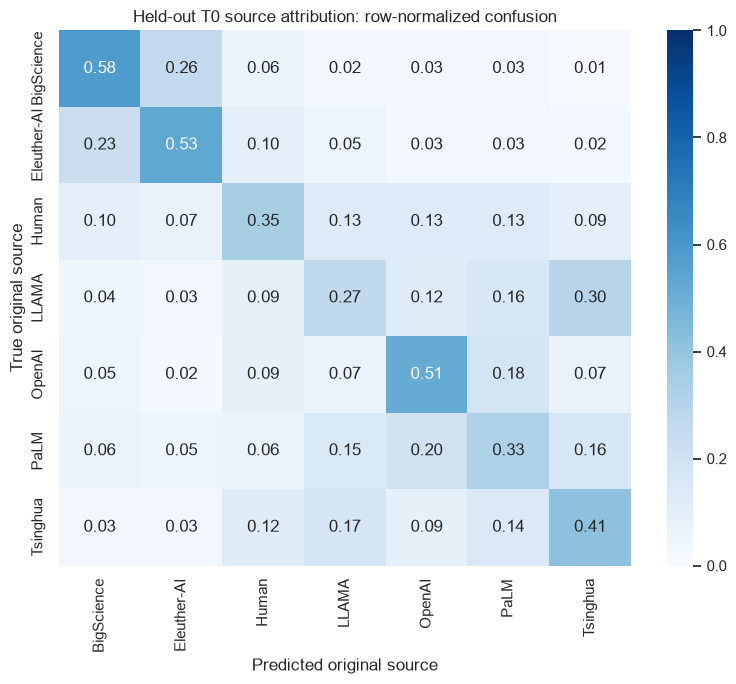

Training T0 originals: 11,620
Validation T0 originals: 2,496
Test originals per trajectory: 2,543
Selected C: 10.0

Validation results:


,C,accuracy,macro_f1
0,0.01,0.4199,0.4136
1,0.10,0.4215,0.4153
2,1.00,0.4203,0.4148
3,10.00,0.4207,0.4155



Test dummy baselines:


,baseline,accuracy,macro_f1
0,most_frequent,0.1667,0.0408
1,stratified,0.1392,0.1373



Held-out Macro-F1 across stages:


stage,T0,T1,T2,T3
configuration,,,,
chatgpt,0.423,0.2586,0.2517,0.2491
palm,0.423,0.3010,0.2790,0.2707
pegasus(full),0.423,0.3111,0.2638,0.2545
pegasus(slight),0.423,0.3960,0.3902,0.3672
dipper,0.423,0.2754,0.2158,0.2099
dipper(low),0.423,0.3537,0.3195,0.2978
dipper(high),0.423,0.1599,0.1603,0.1572


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import joblib

attribution_dir = output_dir / "source_attribution"
attribution_dir.mkdir(exist_ok=True)

source_features = trajectory_features.copy()
source_labels = sorted(originals["source"].unique())

train_t0 = originals.loc[
    originals["split"].eq("train")
].copy()

validation_t0 = originals.loc[
    originals["split"].eq("validation")
].copy()

test_t0 = (
    originals.loc[originals["split"].eq("test")]
    .sort_values(sample_keys)
    .reset_index(drop=True)
)

X_train = train_t0[source_features]
y_train = train_t0["source"]

X_validation = validation_t0[source_features]
y_validation = validation_t0["source"]

# Tune only on validation T0; retain the first model when scores tie.
candidate_models = {}
validation_rows = []

for regularization in [0.01, 0.1, 1.0, 10.0]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(
            C=regularization,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=3000,
            random_state=RANDOM_SEED,
        )),
    ])

    model.fit(X_train, y_train)
    predicted = model.predict(X_validation)

    validation_rows.append({
        "C": regularization,
        "accuracy": accuracy_score(y_validation, predicted),
        "macro_f1": f1_score(
            y_validation,
            predicted,
            labels=source_labels,
            average="macro",
            zero_division=0,
        ),
    })

    candidate_models[regularization] = model

validation_results = pd.DataFrame(validation_rows)

best_row = validation_results.sort_values(
    ["macro_f1", "C"],
    ascending=[False, True],
).iloc[0]

best_c = float(best_row["C"])
source_model = candidate_models[best_c]

# Dummy baselines are fitted on training labels only.
dummy_models = {
    strategy: DummyClassifier(
        strategy=strategy,
        random_state=RANDOM_SEED,
    ).fit(X_train, y_train)
    for strategy in ["most_frequent", "stratified"]
}

dummy_rows = []

for strategy, model in dummy_models.items():
    predicted = model.predict(test_t0[source_features])

    dummy_rows.append({
        "baseline": strategy,
        "accuracy": accuracy_score(test_t0["source"], predicted),
        "macro_f1": f1_score(
            test_t0["source"],
            predicted,
            labels=source_labels,
            average="macro",
            zero_division=0,
        ),
    })

dummy_results = pd.DataFrame(dummy_rows)

# Predict every held-out text once.
heldout = (
    style_features.loc[style_features["split"].eq("test")]
    .sort_values(identity_columns)
    .reset_index(drop=True)
)

source_predictions = heldout[
    identity_columns + ["configuration", "iteration", "stage", "split"]
].copy()

source_predictions["predicted_source"] = source_model.predict(
    heldout[source_features]
)

probabilities = source_model.predict_proba(heldout[source_features])
model_classes = list(source_model.named_steps["classifier"].classes_)

for index, label in enumerate(model_classes):
    source_predictions[f"probability_{label}"] = probabilities[:, index]

# Score each rewrite on the exact same held-out original identities.
expected_test_ids = set(
    test_t0[sample_keys].itertuples(index=False, name=None)
)

metric_rows = []
recall_rows = []

for configuration in configurations:
    for iteration in range(4):
        version = (
            "original"
            if iteration == 0
            else "_".join([configuration] * iteration)
        )

        subset = source_predictions.loc[
            source_predictions["version_name"].eq(version)
        ]

        actual_ids = set(
            subset[sample_keys].itertuples(index=False, name=None)
        )

        assert actual_ids == expected_test_ids
        assert len(subset) == len(test_t0)

        true = subset["source"]
        predicted = subset["predicted_source"]

        metric_rows.append({
            "configuration": configuration,
            "iteration": iteration,
            "stage": f"T{iteration}",
            "n_originals": len(subset),
            "accuracy": accuracy_score(true, predicted),
            "macro_f1": f1_score(
                true,
                predicted,
                labels=source_labels,
                average="macro",
                zero_division=0,
            ),
        })

        for label in source_labels:
            mask = true.eq(label)

            recall_rows.append({
                "configuration": configuration,
                "iteration": iteration,
                "source": label,
                "n_originals": int(mask.sum()),
                "recall": float(predicted.loc[mask].eq(label).mean()),
            })

source_metrics = pd.DataFrame(metric_rows)
source_recall = pd.DataFrame(recall_rows)

for filename, table in {
    "validation_results.csv": validation_results,
    "dummy_baselines.csv": dummy_results,
    "test_predictions.csv": source_predictions,
    "test_metrics.csv": source_metrics,
    "test_source_recall.csv": source_recall,
}.items():
    table.to_csv(attribution_dir / filename, index=False)

joblib.dump(
    {
        "model": source_model,
        "features": source_features,
        "labels": source_labels,
        "selected_C": best_c,
        "random_seed": RANDOM_SEED,
    },
    attribution_dir / "source_model.joblib",
)

# Include the measured T0 test performance in every trajectory.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, ylabel in [
    (axes[0], "accuracy", "Accuracy"),
    (axes[1], "macro_f1", "Macro-F1"),
]:
    for configuration in configurations:
        subset = source_metrics.loc[
            source_metrics["configuration"].eq(configuration)
        ].sort_values("iteration")

        ax.plot(
            subset["iteration"],
            subset[metric],
            marker="o",
            color=colors[configuration],
            label=configuration_labels[configuration],
        )

    for strategy, linestyle in [
        ("most_frequent", "--"),
        ("stratified", ":"),
    ]:
        baseline = dummy_results.loc[
            dummy_results["baseline"].eq(strategy), metric
        ].iloc[0]

        ax.axhline(
            baseline,
            color="gray",
            linestyle=linestyle,
            linewidth=1,
            label=f"Dummy: {strategy}",
        )

    ax.set_xticks(range(4), stage_order)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Stage")
    ax.set_ylabel(ylabel)
    ax.set_title(f"Original-source attribution: {ylabel}")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    frameon=False,
)

fig.suptitle(
    "Seven-class source attribution from style features\n"
    "Trained on T0 only; fixed model evaluated on held-out T0-T3",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0.20, 1, 0.88])
fig.savefig(
    figure_dir / "10_source_attribution_trajectories.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# T0 confusion matrix establishes whether source identity is learnable.
t0_predictions = source_predictions.loc[
    source_predictions["iteration"].eq(0)
]

matrix = confusion_matrix(
    t0_predictions["source"],
    t0_predictions["predicted_source"],
    labels=source_labels,
    normalize="true",
)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=source_labels,
    yticklabels=source_labels,
    ax=ax,
)
ax.set_title("Held-out T0 source attribution: row-normalized confusion")
ax.set_xlabel("Predicted original source")
ax.set_ylabel("True original source")
fig.tight_layout()
fig.savefig(
    figure_dir / "11_source_attribution_t0_confusion.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(f"Training T0 originals: {len(train_t0):,}")
print(f"Validation T0 originals: {len(validation_t0):,}")
print(f"Test originals per trajectory: {len(test_t0):,}")
print(f"Selected C: {best_c}")

print("\nValidation results:")
display(validation_results.round(4))

print("\nTest dummy baselines:")
display(dummy_results.round(4))

print("\nHeld-out Macro-F1 across stages:")
display(
    source_metrics.pivot(
        index="configuration",
        columns="stage",
        values="macro_f1",
    ).reindex(
        index=configurations,
        columns=stage_order,
    ).round(4)
)

## 10. Source-attribution uncertainty and the point of no return

Use paired document-group resampling within domains, keeping related source variants together. Compare Macro-F1 with a domain-conditioned independence reference constructed from true and predicted margins. This is a descriptive reference, not a retrained permutation test.

DIPPER high has T3 Macro-F1 of approximately 0.1572 and a reference gap of 0.0238, with pointwise 95% interval [0.0102, 0.0381]. Under this classifier and comparator, no complete loss of source signal is observed through T3. This does not establish a universal detectability boundary. Intervals condition on the fitted classifier.

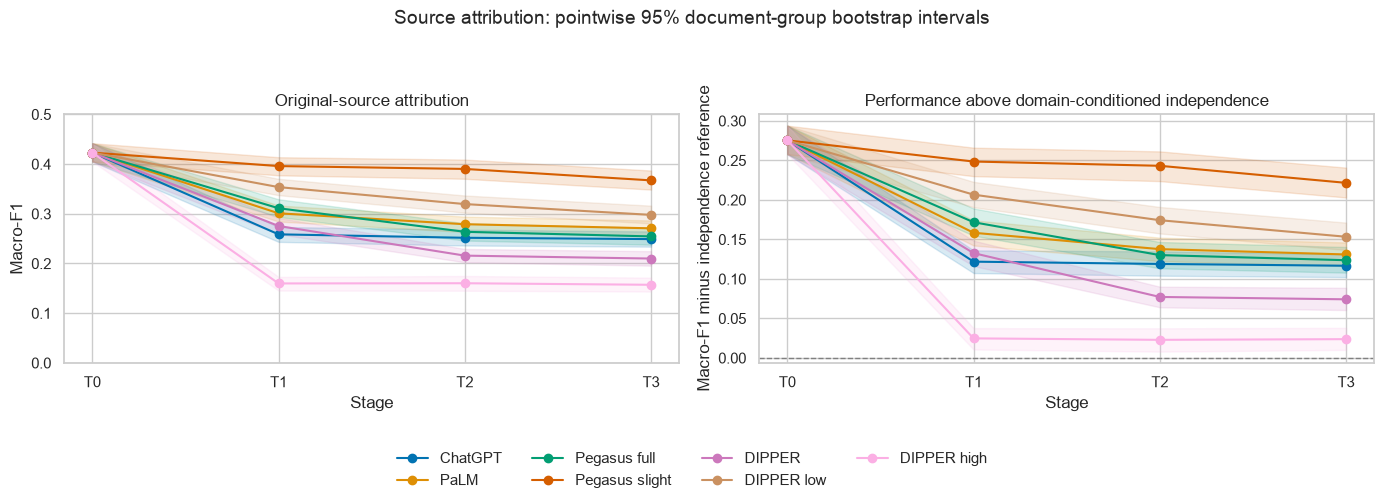

Fixed classifier; paired document-group resampling within domains.
The independence reference is a descriptive chance comparator, not a retrained permutation test.
Pointwise intervals; no multiple-comparison adjustment.

T0 estimate:


,version_name,configuration,iteration,accuracy,accuracy_low,accuracy_high,macro_f1,f1_low,f1_high,reference_macro_f1,gap,gap_low,gap_high
0,original,original,0,0.4263,0.4084,0.4452,0.423,0.4052,0.4419,0.1477,0.2753,0.2579,0.2939



Rewritten-text estimates:


,configuration,iteration,macro_f1,f1_low,f1_high,reference_macro_f1,gap,gap_low,gap_high
1,chatgpt,1,0.2586,0.2435,0.2735,0.1368,0.1219,0.1074,0.1361
2,chatgpt,2,0.2517,0.2362,0.2682,0.1327,0.1190,0.1041,0.1349
3,chatgpt,3,0.2491,0.2338,0.2645,0.1324,0.1167,0.1023,0.1312
4,palm,1,0.3010,0.2844,0.3166,0.1426,0.1584,0.1423,0.1741
5,palm,2,0.2790,0.2633,0.2943,0.1413,0.1377,0.1225,0.1523
6,palm,3,0.2707,0.2556,0.2866,0.1398,0.1310,0.1163,0.1462
7,pegasus(full),1,0.3111,0.2937,0.3292,0.1394,0.1717,0.1548,0.1891
8,pegasus(full),2,0.2638,0.2461,0.2809,0.1336,0.1302,0.1134,0.1467
9,pegasus(full),3,0.2545,0.2378,0.2718,0.1308,0.1237,0.1079,0.1404
10,pegasus(slight),1,0.3960,0.3773,0.4138,0.1474,0.2485,0.2300,0.2661


In [10]:
# Grouped bootstrap for source attribution.
N_SOURCE_BOOTSTRAP = 2000

group_table = (
    test_t0[["domain", "key"]]
    .drop_duplicates()
    .sort_values(["domain", "key"])
    .reset_index(drop=True)
)

group_index = pd.MultiIndex.from_frame(group_table)
group_domains = group_table["domain"].to_numpy()

rng = np.random.default_rng(RANDOM_SEED)
group_weights = np.zeros(
    (N_SOURCE_BOOTSTRAP, len(group_table)),
    dtype=float,
)

domain_group_indices = {}

for domain in domains:
    indices = np.flatnonzero(group_domains == domain)
    domain_group_indices[domain] = indices

    group_weights[:, indices] = rng.multinomial(
        len(indices),
        np.full(len(indices), 1.0 / len(indices)),
        size=N_SOURCE_BOOTSTRAP,
    )

label_index = {
    label: index for index, label in enumerate(source_labels)
}
n_classes = len(source_labels)


def scores_from_confusion(matrices):
    diagonal = np.diagonal(matrices, axis1=-2, axis2=-1)
    true_counts = matrices.sum(axis=-1)
    predicted_counts = matrices.sum(axis=-2)

    denominator = true_counts + predicted_counts

    class_f1 = np.divide(
        2 * diagonal,
        denominator,
        out=np.zeros_like(diagonal, dtype=float),
        where=denominator > 0,
    )

    accuracy = (
        diagonal.sum(axis=-1)
        / matrices.sum(axis=(-2, -1))
    )

    return accuracy, class_f1.mean(axis=-1)


ci_rows = []
source_bootstrap_scores = {}

for version, metadata_row in version_metadata.items():
    subset = source_predictions.loc[
        source_predictions["version_name"].eq(version)
    ].copy()

    positions = group_index.get_indexer(
        pd.MultiIndex.from_frame(subset[["domain", "key"]])
    )

    assert (positions >= 0).all()

    true_indices = subset["source"].map(label_index).to_numpy()
    predicted_indices = (
        subset["predicted_source"].map(label_index).to_numpy()
    )

    # One confusion matrix per underlying document group.
    group_confusion = np.zeros(
        (len(group_table), n_classes, n_classes),
        dtype=float,
    )

    np.add.at(
        group_confusion,
        (positions, true_indices, predicted_indices),
        1,
    )

    bootstrap_confusion = (
        group_weights @ group_confusion.reshape(len(group_table), -1)
    ).reshape(-1, n_classes, n_classes)

    accuracy_boot, f1_boot = scores_from_confusion(
        bootstrap_confusion
    )

    # Domain-conditioned independence reference.
    reference_boot = np.zeros_like(bootstrap_confusion)
    reference_observed = np.zeros((n_classes, n_classes))

    for indices in domain_group_indices.values():
        domain_confusion_boot = (
            group_weights[:, indices]
            @ group_confusion[indices].reshape(len(indices), -1)
        ).reshape(-1, n_classes, n_classes)

        true_margin = domain_confusion_boot.sum(axis=2)
        predicted_margin = domain_confusion_boot.sum(axis=1)
        totals = domain_confusion_boot.sum(axis=(1, 2))

        reference_boot += (
            true_margin[:, :, None]
            * predicted_margin[:, None, :]
            / totals[:, None, None]
        )

        domain_observed = group_confusion[indices].sum(axis=0)

        reference_observed += (
            np.outer(
                domain_observed.sum(axis=1),
                domain_observed.sum(axis=0),
            )
            / domain_observed.sum()
        )

    _, reference_f1_boot = scores_from_confusion(reference_boot)
    gap_boot = f1_boot - reference_f1_boot

    observed_accuracy, observed_f1 = scores_from_confusion(
        group_confusion.sum(axis=0)
    )
    _, reference_f1 = scores_from_confusion(reference_observed)

    source_bootstrap_scores[version] = {
        "accuracy": accuracy_boot,
        "macro_f1": f1_boot,
        "reference_macro_f1": reference_f1_boot,
        "gap": gap_boot,
    }

    ci_rows.append({
        "version_name": version,
        "configuration": metadata_row["configuration"],
        "iteration": metadata_row["iteration"],
        "accuracy": float(observed_accuracy),
        "accuracy_low": np.quantile(accuracy_boot, 0.025),
        "accuracy_high": np.quantile(accuracy_boot, 0.975),
        "macro_f1": float(observed_f1),
        "f1_low": np.quantile(f1_boot, 0.025),
        "f1_high": np.quantile(f1_boot, 0.975),
        "reference_macro_f1": float(reference_f1),
        "gap": float(observed_f1 - reference_f1),
        "gap_low": np.quantile(gap_boot, 0.025),
        "gap_high": np.quantile(gap_boot, 0.975),
    })

source_attribution_ci = pd.DataFrame(ci_rows)

source_attribution_ci.to_csv(
    attribution_dir / "test_group_bootstrap_ci.csv",
    index=False,
)

# Compare each stage with T0 using the same resampled groups.
drop_rows = []
t0_boot = source_bootstrap_scores["original"]["macro_f1"]
t0_f1 = float(
    source_attribution_ci.loc[
        source_attribution_ci["version_name"].eq("original"),
        "macro_f1",
    ].iloc[0]
)

for row in source_attribution_ci.itertuples(index=False):
    difference = (
        source_bootstrap_scores[row.version_name]["macro_f1"]
        - t0_boot
    )

    drop_rows.append({
        "version_name": row.version_name,
        "macro_f1_change_from_t0": row.macro_f1 - t0_f1,
        "change_low": np.quantile(difference, 0.025),
        "change_high": np.quantile(difference, 0.975),
    })

pd.DataFrame(drop_rows).to_csv(
    attribution_dir / "test_macro_f1_change_from_t0.csv",
    index=False,
)

# Show uncertainty around the measured T0-T3 trajectories.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for configuration in configurations:
    versions = ["original"] + [
        "_".join([configuration] * iteration)
        for iteration in range(1, 4)
    ]

    subset = (
        source_attribution_ci
        .set_index("version_name")
        .loc[versions]
    )

    for ax, mean_column, low_column, high_column in [
        (axes[0], "macro_f1", "f1_low", "f1_high"),
        (axes[1], "gap", "gap_low", "gap_high"),
    ]:
        ax.plot(
            range(4),
            subset[mean_column].to_numpy(),
            marker="o",
            color=colors[configuration],
            label=configuration_labels[configuration],
        )

        ax.fill_between(
            range(4),
            subset[low_column].to_numpy(),
            subset[high_column].to_numpy(),
            color=colors[configuration],
            alpha=0.15,
        )

axes[0].set_title("Original-source attribution")
axes[0].set_ylabel("Macro-F1")
axes[0].set_ylim(0, 0.5)

axes[1].set_title("Performance above domain-conditioned independence")
axes[1].set_ylabel("Macro-F1 minus independence reference")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)

for ax in axes:
    ax.set_xticks(range(4), stage_order)
    ax.set_xlabel("Stage")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.suptitle(
    "Source attribution: pointwise 95% document-group bootstrap intervals",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0.14, 1, 0.92])
fig.savefig(
    figure_dir / "12_source_attribution_group_bootstrap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    "Fixed classifier; paired document-group resampling within domains."
)
print(
    "The independence reference is a descriptive chance comparator, "
    "not a retrained permutation test."
)
print("Pointwise intervals; no multiple-comparison adjustment.")

print("\nT0 estimate:")
display(
    source_attribution_ci.loc[
        source_attribution_ci["iteration"].eq(0)
    ].round(4)
)

print("\nRewritten-text estimates:")
display(
    source_attribution_ci.loc[
        source_attribution_ci["iteration"].gt(0),
        [
            "configuration", "iteration",
            "macro_f1", "f1_low", "f1_high",
            "reference_macro_f1", "gap", "gap_low", "gap_high",
        ],
    ].round(4)
)

## 11. RQ3: Paraphraser-family fingerprints

Identify ChatGPT, PaLM, Pegasus or DIPPER using POS and syntax features from rewritten text. T0 is excluded because no paraphraser has acted on it. Use the same grouped split and select regularization on validation data.

Weight configurations equally within each family and give the four families equal contribution. Overall weighted accuracy is 0.5128; accuracy rises from 0.4741 at T1 to 0.5440 at T3, compared with a uniform-chance accuracy reference of 0.25. Configuration-level results remain visible rather than being replaced by family means.

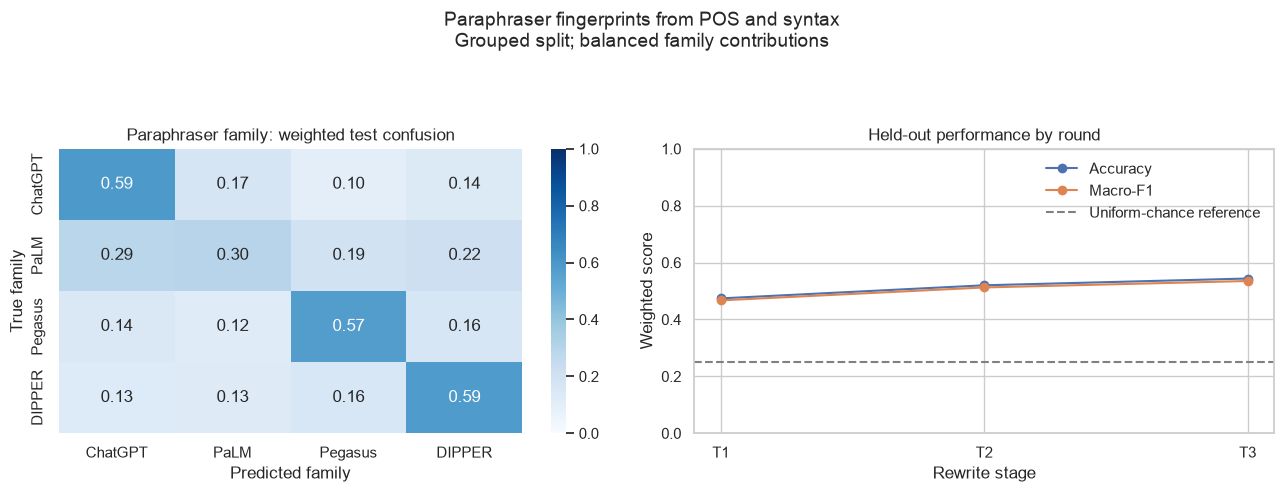

Training rewrite records: 244,020
Validation rewrite records: 52,416
Test rewrite records: 53,403
Selected C: 0.1
T0 is excluded because no paraphraser has acted on it.
Evaluation averages settings within each family, then gives all four families equal contribution.

Validation results:


,C,weighted_accuracy,weighted_macro_f1
0,0.01,0.5181,0.5113
1,0.10,0.5192,0.5125
2,1.00,0.5191,0.5124
3,10.00,0.5189,0.5122



Held-out results:


,evaluation,text_records,originals,weighted_accuracy,weighted_macro_f1
0,all_rounds,53403,2543,0.5128,0.5054
1,T1,17801,2543,0.4741,0.4672
2,T2,17801,2543,0.5202,0.5126
3,T3,17801,2543,0.5440,0.5353



Correct-family rate by configuration and round:


iteration,1,2,3
configuration,,,
chatgpt,0.5474,0.6005,0.6315
palm,0.2855,0.3020,0.3075
pegasus(full),0.6123,0.7660,0.8309
pegasus(slight),0.3327,0.4133,0.4908
dipper,0.5678,0.6020,0.6182
dipper(low),0.3740,0.4058,0.4310
dipper(high),0.8313,0.7578,0.6791


In [11]:
# Identify the paraphraser family from syntax and POS features.
fingerprint_dir = output_dir / "paraphraser_fingerprints"
fingerprint_dir.mkdir(exist_ok=True)

family_map = {
    "chatgpt": "ChatGPT",
    "palm": "PaLM",
    "pegasus(full)": "Pegasus",
    "pegasus(slight)": "Pegasus",
    "dipper": "DIPPER",
    "dipper(low)": "DIPPER",
    "dipper(high)": "DIPPER",
}

family_labels = ["ChatGPT", "PaLM", "Pegasus", "DIPPER"]
family_configuration_counts = Counter(family_map.values())
fingerprint_features = trajectory_features.copy()

rewrites = style_features.loc[
    style_features["iteration"].gt(0)
].copy()

rewrites["paraphraser_family"] = rewrites["configuration"].map(family_map)

# Each original contributes equal total weight to each family.
rewrites["evaluation_weight"] = rewrites["paraphraser_family"].map(
    lambda family: 1.0 / family_configuration_counts[family]
)

fingerprint_train = rewrites.loc[rewrites["split"].eq("train")].copy()
fingerprint_validation = rewrites.loc[
    rewrites["split"].eq("validation")
].copy()
fingerprint_test = rewrites.loc[rewrites["split"].eq("test")].copy()

train_weights = fingerprint_train["evaluation_weight"].to_numpy()
train_weights = train_weights / train_weights.mean()

validation_weights = (
    fingerprint_validation["evaluation_weight"].to_numpy()
)

candidate_fingerprint_models = {}
fingerprint_validation_rows = []

for regularization in [0.01, 0.1, 1.0, 10.0]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(
            C=regularization,
            solver="lbfgs",
            max_iter=3000,
            random_state=RANDOM_SEED,
        )),
    ])

    model.fit(
        fingerprint_train[fingerprint_features],
        fingerprint_train["paraphraser_family"],
        scale__sample_weight=train_weights,
        classifier__sample_weight=train_weights,
    )

    predicted = model.predict(
        fingerprint_validation[fingerprint_features]
    )

    fingerprint_validation_rows.append({
        "C": regularization,
        "weighted_accuracy": accuracy_score(
            fingerprint_validation["paraphraser_family"],
            predicted,
            sample_weight=validation_weights,
        ),
        "weighted_macro_f1": f1_score(
            fingerprint_validation["paraphraser_family"],
            predicted,
            labels=family_labels,
            average="macro",
            sample_weight=validation_weights,
            zero_division=0,
        ),
    })

    candidate_fingerprint_models[regularization] = model

fingerprint_validation_results = pd.DataFrame(
    fingerprint_validation_rows
)

selected_row = fingerprint_validation_results.sort_values(
    ["weighted_macro_f1", "C"],
    ascending=[False, True],
).iloc[0]

fingerprint_c = float(selected_row["C"])
fingerprint_model = candidate_fingerprint_models[fingerprint_c]

fingerprint_predictions = fingerprint_test[
    identity_columns
    + [
        "configuration", "iteration", "stage",
        "paraphraser_family", "evaluation_weight",
    ]
].copy()

fingerprint_predictions["predicted_family"] = fingerprint_model.predict(
    fingerprint_test[fingerprint_features]
)

# Report overall and per-round results.
fingerprint_metric_rows = []

evaluation_subsets = [
    ("all_rounds", fingerprint_predictions),
    *[
        (
            f"T{iteration}",
            fingerprint_predictions.loc[
                fingerprint_predictions["iteration"].eq(iteration)
            ],
        )
        for iteration in range(1, 4)
    ],
]

for evaluation_name, subset in evaluation_subsets:
    weights = subset["evaluation_weight"]

    fingerprint_metric_rows.append({
        "evaluation": evaluation_name,
        "text_records": len(subset),
        "originals": len(subset[sample_keys].drop_duplicates()),
        "weighted_accuracy": accuracy_score(
            subset["paraphraser_family"],
            subset["predicted_family"],
            sample_weight=weights,
        ),
        "weighted_macro_f1": f1_score(
            subset["paraphraser_family"],
            subset["predicted_family"],
            labels=family_labels,
            average="macro",
            sample_weight=weights,
            zero_division=0,
        ),
    })

fingerprint_metrics = pd.DataFrame(fingerprint_metric_rows)

# Keep configuration-level results visible.
configuration_rows = []

for (configuration, iteration), subset in (
    fingerprint_predictions.groupby(["configuration", "iteration"])
):
    configuration_rows.append({
        "configuration": configuration,
        "iteration": iteration,
        "family": family_map[configuration],
        "n_originals": len(subset),
        "correct_family_rate": (
            subset["predicted_family"]
            .eq(subset["paraphraser_family"])
            .mean()
        ),
    })

fingerprint_configuration_results = pd.DataFrame(configuration_rows)

for filename, table in {
    "syntax_validation_results.csv": fingerprint_validation_results,
    "syntax_test_predictions.csv": fingerprint_predictions,
    "syntax_test_metrics.csv": fingerprint_metrics,
    "syntax_configuration_results.csv": fingerprint_configuration_results,
}.items():
    table.to_csv(fingerprint_dir / filename, index=False)

joblib.dump(
    {
        "model": fingerprint_model,
        "features": fingerprint_features,
        "family_map": family_map,
        "selected_C": fingerprint_c,
        "weighting": "equal family contribution; equal settings within family",
    },
    fingerprint_dir / "syntax_fingerprint_model.joblib",
)

# Family confusion matrix with balanced configuration contributions.
matrix = confusion_matrix(
    fingerprint_predictions["paraphraser_family"],
    fingerprint_predictions["predicted_family"],
    labels=family_labels,
    sample_weight=fingerprint_predictions["evaluation_weight"],
    normalize="true",
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=family_labels,
    yticklabels=family_labels,
    ax=axes[0],
)

axes[0].set_title("Paraphraser family: weighted test confusion")
axes[0].set_xlabel("Predicted family")
axes[0].set_ylabel("True family")

round_results = fingerprint_metrics.loc[
    fingerprint_metrics["evaluation"].ne("all_rounds")
]

for metric, label in [
    ("weighted_accuracy", "Accuracy"),
    ("weighted_macro_f1", "Macro-F1"),
]:
    axes[1].plot(
        range(1, 4),
        round_results[metric],
        marker="o",
        label=label,
    )

axes[1].axhline(
    0.25,
    color="gray",
    linestyle="--",
    label="Uniform-chance reference",
)

axes[1].set_xticks([1, 2, 3], ["T1", "T2", "T3"])
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Rewrite stage")
axes[1].set_ylabel("Weighted score")
axes[1].set_title("Held-out performance by round")
axes[1].legend(frameon=False)

fig.suptitle(
    "Paraphraser fingerprints from POS and syntax\n"
    "Grouped split; balanced family contributions",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(
    figure_dir / "13_paraphraser_syntax_baseline.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(f"Training rewrite records: {len(fingerprint_train):,}")
print(f"Validation rewrite records: {len(fingerprint_validation):,}")
print(f"Test rewrite records: {len(fingerprint_test):,}")
print(f"Selected C: {fingerprint_c}")
print(
    "T0 is excluded because no paraphraser has acted on it."
)
print(
    "Evaluation averages settings within each family, "
    "then gives all four families equal contribution."
)

print("\nValidation results:")
display(fingerprint_validation_results.round(4))

print("\nHeld-out results:")
display(fingerprint_metrics.round(4))

print("\nCorrect-family rate by configuration and round:")
display(
    fingerprint_configuration_results.pivot(
        index="configuration",
        columns="iteration",
        values="correct_family_rate",
    ).reindex(configurations).round(4)
)

## 12. Fingerprint uncertainty and feature associations

Load saved predictions and the fitted model without retraining. Use 2,000 paired document-group bootstrap replicates within domains. Estimate round-to-round differences and evaluate a test-set sensitivity analysis excluding DIPPER high with family rebalancing.

The T3-minus-T1 weighted accuracy difference is approximately 0.0699 with pointwise 95% interval [0.0631, 0.0766]. Exclusion changes the evaluation population; it does not retrain the classifier.

The coefficient table lists the five largest signed coefficients per family, so negative values may appear. Coefficients describe conditional model associations. Correlated POS proportions cannot be interpreted as independent or causal linguistic rules.

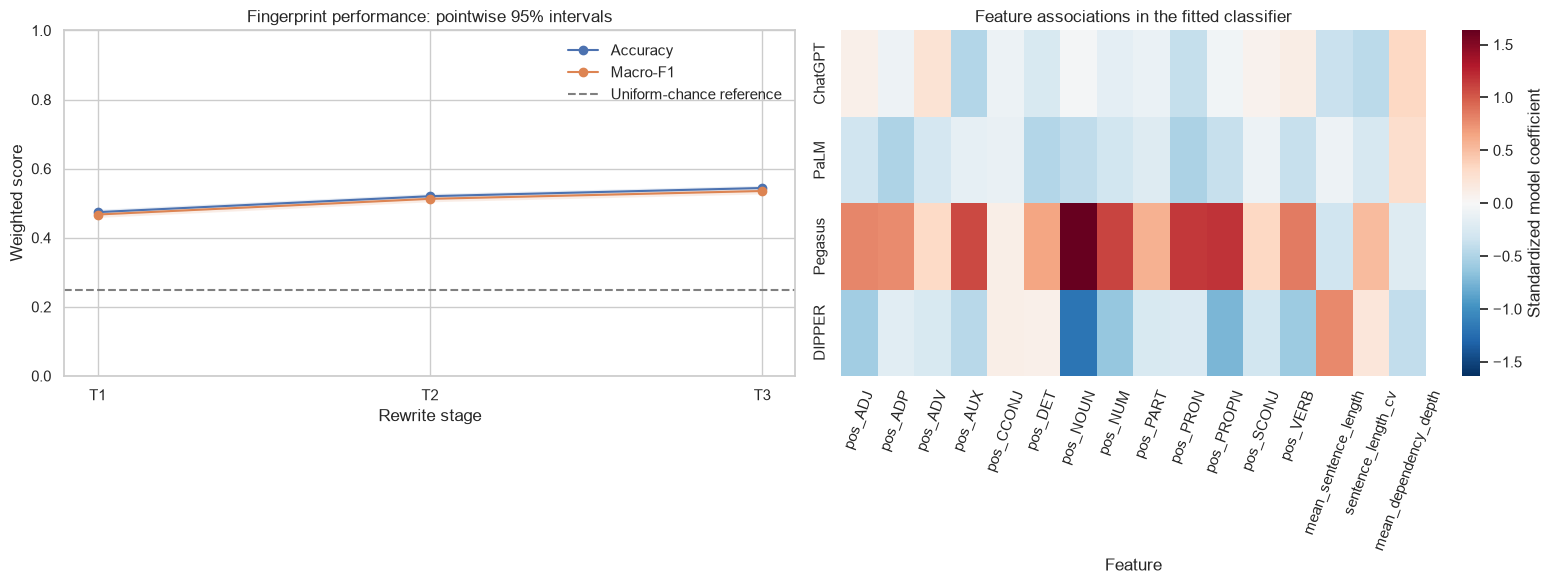

Bootstrap replicates: 2,000
Held-out document groups: 455
Loaded saved predictions and model; no retraining performed.
Paired group resampling within domains; fixed classifier.
Pointwise intervals; no multiple-comparison adjustment.
The exclusion analysis removes DIPPER high from the test set and rebalances families without retraining.
Coefficients describe model associations, not causal effects.

Performance with 95% intervals:


,evaluation,text_records,originals,weighted_accuracy,accuracy_low,accuracy_high,weighted_macro_f1,f1_low,f1_high
0,all_rounds,53403,2543,0.5128,0.5052,0.5197,0.5054,0.4974,0.5126
1,T1,17801,2543,0.4741,0.4659,0.4821,0.4672,0.4586,0.4757
2,T2,17801,2543,0.5202,0.5120,0.5280,0.5126,0.5040,0.5209
3,T3,17801,2543,0.5440,0.5357,0.5516,0.5353,0.5267,0.5433
4,exclude_dipper_high,45774,2543,0.4914,0.4837,0.4985,0.4850,0.4771,0.4926



Paired performance differences:


,comparison,metric,mean_change,ci_low,ci_high
0,T2 minus T1,accuracy,0.0461,0.0395,0.0523
1,T2 minus T1,macro_f1,0.0454,0.0386,0.0515
2,T3 minus T2,accuracy,0.0238,0.0178,0.0298
3,T3 minus T2,macro_f1,0.0227,0.0166,0.0287
4,T3 minus T1,accuracy,0.0699,0.0631,0.0766
5,T3 minus T1,macro_f1,0.0680,0.0610,0.0749
6,exclude_dipper_high minus all_rounds,accuracy,-0.0214,-0.0232,-0.0197
7,exclude_dipper_high minus all_rounds,macro_f1,-0.0204,-0.0225,-0.0185



Top five standardized coefficients per family (descending):


,family,feature,coefficient
0,ChatGPT,mean_dependency_depth,0.3390
1,ChatGPT,pos_ADV,0.2350
2,ChatGPT,pos_VERB,0.1231
3,ChatGPT,pos_ADJ,0.1002
4,ChatGPT,pos_SCONJ,0.0659
5,PaLM,mean_dependency_depth,0.2817
6,PaLM,mean_sentence_length,-0.0883
7,PaLM,pos_SCONJ,-0.0924
8,PaLM,pos_CCONJ,-0.1190
9,PaLM,pos_AUX,-0.1486


In [12]:
# Fingerprint uncertainty, sensitivity analysis, and feature interpretation.
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

current_dir = Path.cwd().resolve()

project_root = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

output_dir = project_root / "experiments" / "update2"
figure_dir = project_root / "figures" / "update2"
figure_dir.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 6120

domains = ["cmv", "eli5", "sci_gen", "tldr", "wp", "xsum", "yelp"]
sample_keys = ["domain", "source", "key"]
identity_columns = sample_keys + ["version_name"]

sns.set_theme(style="whitegrid", context="notebook")

fingerprint_dir = output_dir / "paraphraser_fingerprints"
N_BOOTSTRAP = 2000

family_labels = ["ChatGPT", "PaLM", "Pegasus", "DIPPER"]
family_index = {
    family: index for index, family in enumerate(family_labels)
}

saved_model = joblib.load(
    fingerprint_dir / "syntax_fingerprint_model.joblib"
)

fingerprint_model = saved_model["model"]
fingerprint_features = saved_model["features"]

predictions = pd.read_csv(
    fingerprint_dir / "syntax_test_predictions.csv",
    dtype={
        "domain": str,
        "source": str,
        "key": str,
        "configuration": str,
        "paraphraser_family": str,
        "predicted_family": str,
    },
)

assert not predictions.duplicated(identity_columns).any()
assert set(predictions["paraphraser_family"]) == set(family_labels)
assert set(predictions["predicted_family"]).issubset(family_labels)
assert set(predictions["iteration"]) == {1, 2, 3}

# Preserve all source variants, settings, and rounds of each document group.
groups = (
    predictions[["domain", "key"]]
    .drop_duplicates()
    .sort_values(["domain", "key"])
    .reset_index(drop=True)
)

group_index = pd.MultiIndex.from_frame(groups)
rng = np.random.default_rng(RANDOM_SEED)

bootstrap_weights = np.zeros(
    (N_BOOTSTRAP, len(groups)),
    dtype=float,
)

for domain in domains:
    indices = np.flatnonzero(groups["domain"].eq(domain).to_numpy())
    assert len(indices) > 0

    bootstrap_weights[:, indices] = rng.multinomial(
        len(indices),
        np.full(len(indices), 1.0 / len(indices)),
        size=N_BOOTSTRAP,
    )


def confusion_scores(matrices):
    diagonal = np.diagonal(matrices, axis1=-2, axis2=-1)
    denominator = matrices.sum(axis=-1) + matrices.sum(axis=-2)

    class_f1 = np.divide(
        2 * diagonal,
        denominator,
        out=np.zeros_like(diagonal, dtype=float),
        where=denominator > 0,
    )

    accuracy = (
        diagonal.sum(axis=-1)
        / matrices.sum(axis=(-2, -1))
    )

    return accuracy, class_f1.mean(axis=-1)


evaluation_sets = {
    "all_rounds": predictions,
    **{
        f"T{iteration}": predictions.loc[
            predictions["iteration"].eq(iteration)
        ]
        for iteration in range(1, 4)
    },
    "exclude_dipper_high": predictions.loc[
        predictions["configuration"].ne("dipper(high)")
    ],
}

result_rows = []
bootstrap_scores = {}

for name, subset in evaluation_sets.items():
    # Give families equal weight and settings equal weight within each family.
    settings_per_family = (
        subset[["configuration", "paraphraser_family"]]
        .drop_duplicates()
        .groupby("paraphraser_family")
        .size()
    )

    sample_weights = (
        1.0
        / subset["paraphraser_family"].map(settings_per_family)
    ).to_numpy()

    positions = group_index.get_indexer(
        pd.MultiIndex.from_frame(subset[["domain", "key"]])
    )

    assert (positions >= 0).all()

    true_indices = (
        subset["paraphraser_family"].map(family_index).to_numpy()
    )
    predicted_indices = (
        subset["predicted_family"].map(family_index).to_numpy()
    )

    group_confusion = np.zeros((len(groups), 4, 4), dtype=float)

    np.add.at(
        group_confusion,
        (positions, true_indices, predicted_indices),
        sample_weights,
    )

    observed_confusion = group_confusion.sum(axis=0)

    assert np.allclose(
        observed_confusion.sum(axis=1),
        observed_confusion.sum() / 4,
    ), "Family contributions are not balanced."

    observed_accuracy, observed_f1 = confusion_scores(
        observed_confusion
    )

    resampled_confusion = (
        bootstrap_weights @ group_confusion.reshape(len(groups), -1)
    ).reshape(N_BOOTSTRAP, 4, 4)

    accuracy_boot, f1_boot = confusion_scores(resampled_confusion)

    bootstrap_scores[name] = {
        "accuracy": accuracy_boot,
        "macro_f1": f1_boot,
    }

    result_rows.append({
        "evaluation": name,
        "text_records": len(subset),
        "originals": len(subset[sample_keys].drop_duplicates()),
        "weighted_accuracy": float(observed_accuracy),
        "accuracy_low": np.quantile(accuracy_boot, 0.025),
        "accuracy_high": np.quantile(accuracy_boot, 0.975),
        "weighted_macro_f1": float(observed_f1),
        "f1_low": np.quantile(f1_boot, 0.025),
        "f1_high": np.quantile(f1_boot, 0.975),
    })

fingerprint_ci = pd.DataFrame(result_rows)
estimates = fingerprint_ci.set_index("evaluation")

# Paired differences use identical document-group resamples.
comparison_rows = []

comparisons = [
    ("T1", "T2"),
    ("T2", "T3"),
    ("T1", "T3"),
    ("all_rounds", "exclude_dipper_high"),
]

for previous, current in comparisons:
    for metric, column in [
        ("accuracy", "weighted_accuracy"),
        ("macro_f1", "weighted_macro_f1"),
    ]:
        differences = (
            bootstrap_scores[current][metric]
            - bootstrap_scores[previous][metric]
        )

        comparison_rows.append({
            "comparison": f"{current} minus {previous}",
            "metric": metric,
            "mean_change": (
                estimates.loc[current, column]
                - estimates.loc[previous, column]
            ),
            "ci_low": np.quantile(differences, 0.025),
            "ci_high": np.quantile(differences, 0.975),
        })

fingerprint_changes = pd.DataFrame(comparison_rows)

# Coefficients refer to standardized input features.
classifier = fingerprint_model.named_steps["classifier"]

coefficients = pd.DataFrame(
    classifier.coef_,
    index=classifier.classes_,
    columns=fingerprint_features,
).reindex(family_labels)

coefficients.index.name = "paraphraser_family"

top_rows = []

for family in family_labels:
    for feature, coefficient in (
        coefficients.loc[family]
        .sort_values(ascending=False)
        .head(5)
        .items()
    ):
        top_rows.append({
            "family": family,
            "feature": feature,
            "coefficient": coefficient,
        })

top_features = pd.DataFrame(top_rows)

# Save tables and bootstrap replicates.
fingerprint_ci.to_csv(
    fingerprint_dir / "syntax_test_group_bootstrap_ci.csv",
    index=False,
)

fingerprint_changes.to_csv(
    fingerprint_dir / "syntax_paired_comparisons.csv",
    index=False,
)

coefficients.to_csv(
    fingerprint_dir / "syntax_standardized_coefficients.csv"
)

top_features.to_csv(
    fingerprint_dir / "syntax_top_positive_coefficients.csv",
    index=False,
)

np.savez_compressed(
    fingerprint_dir / "syntax_bootstrap_scores.npz",
    **{
        f"{name}_{metric}": values
        for name, scores in bootstrap_scores.items()
        for metric, values in scores.items()
    },
)

# Plot performance uncertainty and feature associations.
round_ci = estimates.loc[["T1", "T2", "T3"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for metric, low, high, label in [
    ("weighted_accuracy", "accuracy_low", "accuracy_high", "Accuracy"),
    ("weighted_macro_f1", "f1_low", "f1_high", "Macro-F1"),
]:
    mean = round_ci[metric].to_numpy()

    axes[0].plot(
        [1, 2, 3],
        mean,
        marker="o",
        label=label,
    )

    axes[0].fill_between(
        [1, 2, 3],
        round_ci[low].to_numpy(),
        round_ci[high].to_numpy(),
        alpha=0.15,
    )

axes[0].axhline(
    0.25,
    color="gray",
    linestyle="--",
    label="Uniform-chance reference",
)
axes[0].set_xticks([1, 2, 3], ["T1", "T2", "T3"])
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("Rewrite stage")
axes[0].set_ylabel("Weighted score")
axes[0].set_title("Fingerprint performance: pointwise 95% intervals")
axes[0].legend(frameon=False)

limit = float(np.abs(coefficients.to_numpy()).max())

sns.heatmap(
    coefficients,
    cmap="RdBu_r",
    center=0,
    vmin=-limit,
    vmax=limit,
    ax=axes[1],
    cbar_kws={"label": "Standardized model coefficient"},
)
axes[1].set_title("Feature associations in the fitted classifier")
axes[1].set_xlabel("Feature")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=70)

fig.tight_layout()
fig.savefig(
    figure_dir / "14_paraphraser_fingerprint_ci_and_features.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(f"Bootstrap replicates: {N_BOOTSTRAP:,}")
print(f"Held-out document groups: {len(groups):,}")
print("Loaded saved predictions and model; no retraining performed.")
print("Paired group resampling within domains; fixed classifier.")
print("Pointwise intervals; no multiple-comparison adjustment.")
print(
    "The exclusion analysis removes DIPPER high from the test set "
    "and rebalances families without retraining."
)
print("Coefficients describe model associations, not causal effects.")

print("\nPerformance with 95% intervals:")
display(fingerprint_ci.round(4))

print("\nPaired performance differences:")
display(fingerprint_changes.round(4))

print("\nTop five standardized coefficients per family (descending):")
display(top_features.round(4))

## 13. Refined PCA presentation

Reuse saved coordinates without fitting PCA or training a model. Separate the full point distributions from centroid trajectories. Shared axes support comparisons between configurations.

The centroid-only figure uses a closer view to show average movement; it does not display distribution spread or establish contraction. Interpret it alongside the full-space dispersion analysis.

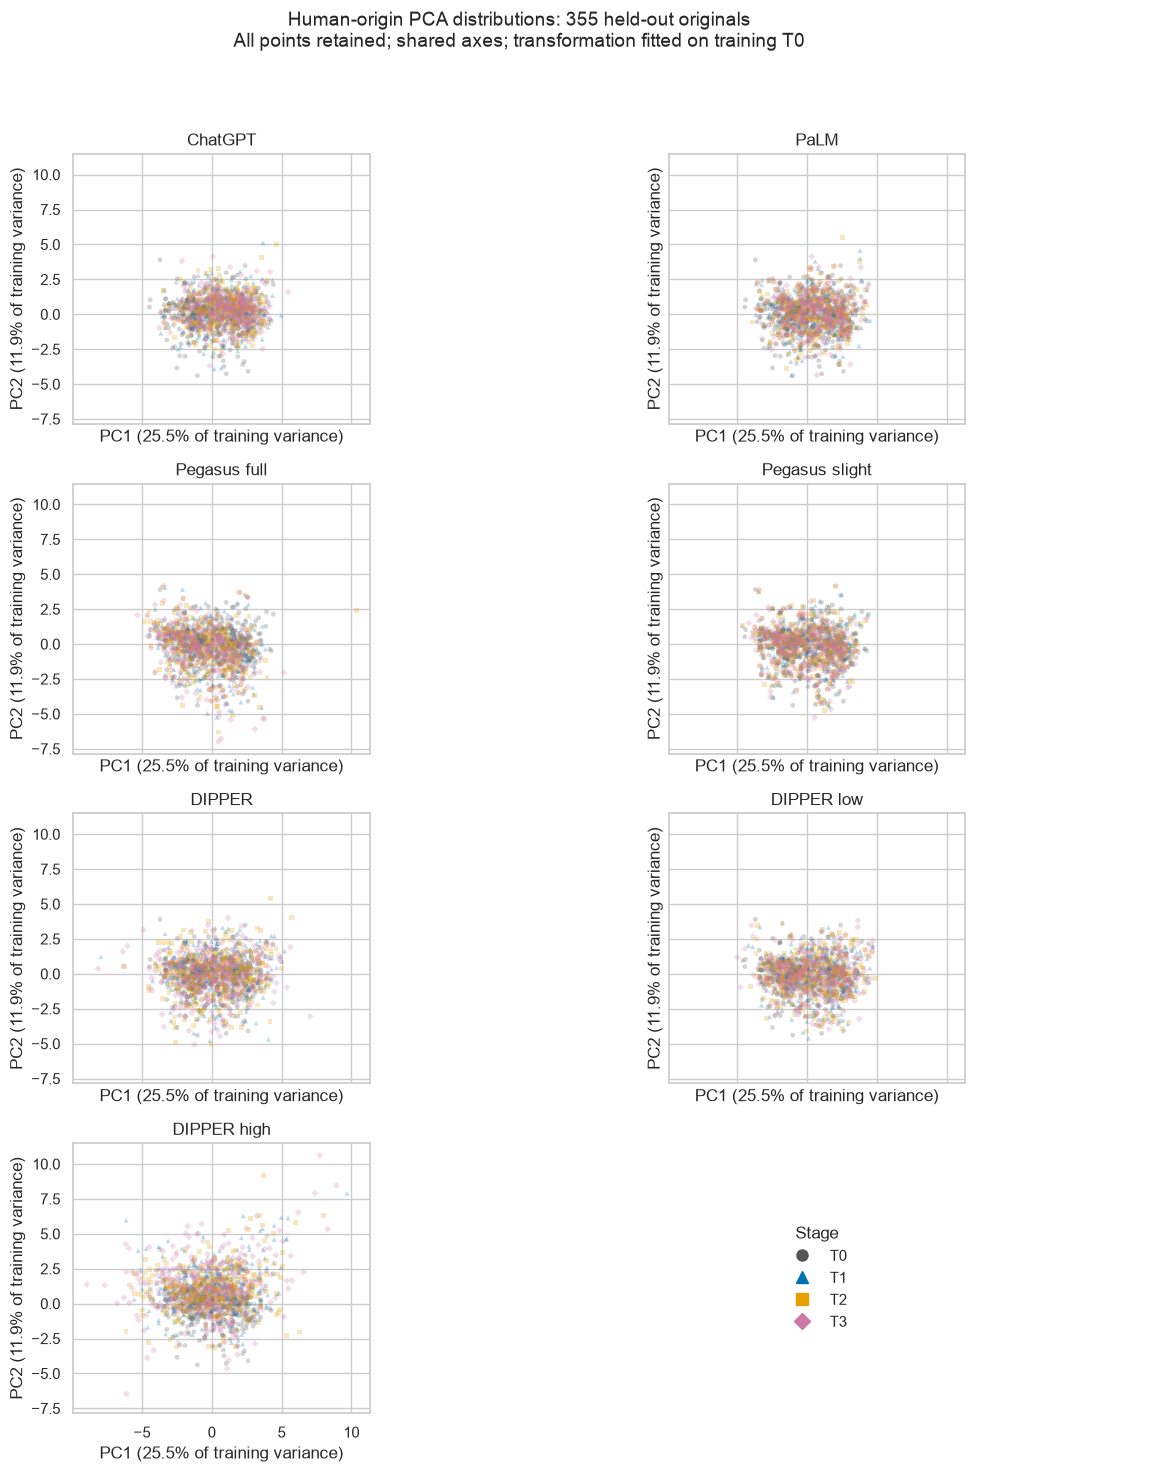

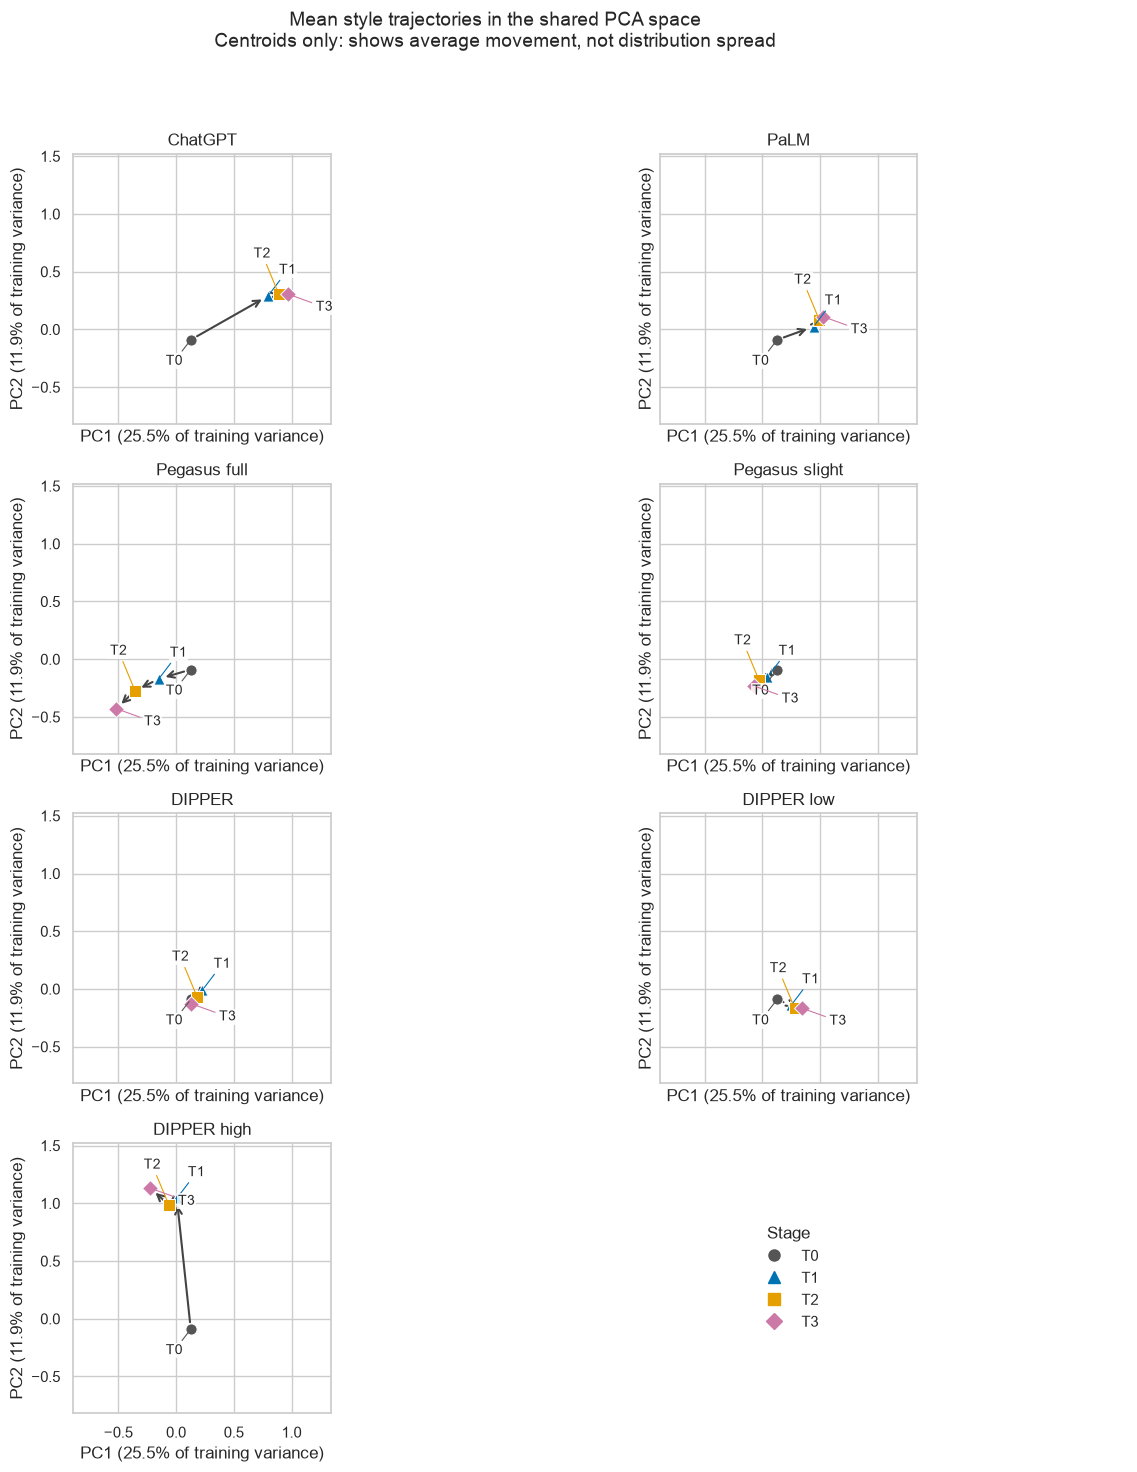

Loaded saved PCA coordinates; no fitting or training performed.
Held-out originals per stage: 355
Combined training variance explained: 37.4%
Figures saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/figures/update2


In [13]:
# Refine PCA figures using saved coordinates only.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

current_dir = Path.cwd().resolve()

project_root = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

trajectory_dir = (
    project_root / "experiments/update2/identity_trajectory"
)
figure_dir = project_root / "figures/update2"
figure_dir.mkdir(parents=True, exist_ok=True)

configuration_labels = {
    "chatgpt": "ChatGPT",
    "palm": "PaLM",
    "pegasus(full)": "Pegasus full",
    "pegasus(slight)": "Pegasus slight",
    "dipper": "DIPPER",
    "dipper(low)": "DIPPER low",
    "dipper(high)": "DIPPER high",
}

stage_order = ["T0", "T1", "T2", "T3"]

stage_colors = {
    "T0": "#555555",
    "T1": "#0072B2",
    "T2": "#E69F00",
    "T3": "#CC79A7",
}

stage_markers = {
    "T0": "o",
    "T1": "^",
    "T2": "s",
    "T3": "D",
}

points = pd.read_csv(
    trajectory_dir / "human_test_pca_coordinates.csv",
    dtype={"domain": str, "source": str, "key": str},
)

variance = pd.read_csv(
    trajectory_dir / "pca_explained_variance.csv"
)

assert np.isfinite(points[["PC1", "PC2"]].to_numpy()).all()
assert not points.duplicated(
    ["domain", "source", "key", "version_name"]
).any()

t0_points = points.loc[points["iteration"].eq(0)]
n_test = len(t0_points)

expected_ids = set(
    t0_points[["domain", "source", "key"]]
    .itertuples(index=False, name=None)
)

centroid_rows = []

for configuration in configuration_labels:
    for iteration, stage in enumerate(stage_order):
        version = (
            "original"
            if iteration == 0
            else "_".join([configuration] * iteration)
        )

        subset = points.loc[points["version_name"].eq(version)]

        actual_ids = set(
            subset[["domain", "source", "key"]]
            .itertuples(index=False, name=None)
        )

        assert actual_ids == expected_ids
        assert len(subset) == n_test

        centroid_rows.append({
            "configuration": configuration,
            "iteration": iteration,
            "stage": stage,
            "PC1": subset["PC1"].mean(),
            "PC2": subset["PC2"].mean(),
        })

centroids = pd.DataFrame(centroid_rows)

pc1_variance = variance["explained_variance_ratio"].iloc[0]
pc2_variance = variance["explained_variance_ratio"].iloc[1]

xlabel = f"PC1 ({pc1_variance:.1%} of training variance)"
ylabel = f"PC2 ({pc2_variance:.1%} of training variance)"

legend_handles = [
    Line2D(
        [0], [0],
        marker=stage_markers[stage],
        color=stage_colors[stage],
        linestyle="none",
        markersize=8,
        label=stage,
    )
    for stage in stage_order
]

sns.set_theme(style="whitegrid", context="notebook")

# Figure A: full distributions with every point retained.
fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 15),
    sharex=True,
    sharey=True,
)

for ax, configuration in zip(axes.flat, configuration_labels):
    for iteration, stage in enumerate(stage_order):
        version = (
            "original"
            if iteration == 0
            else "_".join([configuration] * iteration)
        )

        subset = points.loc[points["version_name"].eq(version)]

        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            s=12,
            alpha=0.25,
            color=stage_colors[stage],
            marker=stage_markers[stage],
            edgecolors="none",
        )

    ax.set_title(configuration_labels[configuration])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_aspect("equal", adjustable="box")

axes.flat[-1].axis("off")
axes.flat[-1].legend(
    handles=legend_handles,
    loc="center",
    title="Stage",
    frameon=False,
)

fig.suptitle(
    f"Human-origin PCA distributions: {n_test} held-out originals\n"
    "All points retained; shared axes; transformation fitted on training T0",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(
    figure_dir / "15_human_pca_distributions_clean.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Figure B: stage centroids only, in the same PCA coordinate system.
# Use shared limits and equal coordinate-unit scaling.
center_values = centroids[["PC1", "PC2"]].to_numpy()
lower = center_values.min(axis=0)
upper = center_values.max(axis=0)
span = np.maximum(upper - lower, 0.1)
padding = 0.25 * span

label_offsets = {
    "T0": (-18, -18),
    "T1": (8, 16),
    "T2": (-18, 26),
    "T3": (20, -12),
}

fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 15),
    sharex=True,
    sharey=True,
)

for ax, configuration in zip(axes.flat, configuration_labels):
    subset = (
        centroids.loc[centroids["configuration"].eq(configuration)]
        .sort_values("iteration")
    )

    coordinates = subset[["PC1", "PC2"]].to_numpy()

    for start, end in zip(coordinates[:-1], coordinates[1:]):
        ax.annotate(
            "",
            xy=end,
            xytext=start,
            arrowprops={
                "arrowstyle": "->",
                "color": "#444444",
                "lw": 1.5,
                "shrinkA": 5,
                "shrinkB": 5,
            },
        )

    for row in subset.itertuples(index=False):
        ax.scatter(
            row.PC1,
            row.PC2,
            s=65,
            marker=stage_markers[row.stage],
            color=stage_colors[row.stage],
            edgecolors="white",
            linewidths=0.7,
            zorder=5,
        )

        ax.annotate(
            row.stage,
            (row.PC1, row.PC2),
            xytext=label_offsets[row.stage],
            textcoords="offset points",
            fontsize=10,
            arrowprops={
                "arrowstyle": "-",
                "color": stage_colors[row.stage],
                "lw": 0.8,
            },
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
                "pad": 1,
            },
            zorder=6,
        )

    ax.set_xlim(lower[0] - padding[0], upper[0] + padding[0])
    ax.set_ylim(lower[1] - padding[1], upper[1] + padding[1])
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(configuration_labels[configuration])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

axes.flat[-1].axis("off")
axes.flat[-1].legend(
    handles=legend_handles,
    loc="center",
    title="Stage",
    frameon=False,
)

fig.suptitle(
    "Mean style trajectories in the shared PCA space\n"
    "Centroids only: shows average movement, not distribution spread",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(
    figure_dir / "16_human_pca_centroid_trajectories.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Loaded saved PCA coordinates; no fitting or training performed.")
print(f"Held-out originals per stage: {n_test}")
print(
    "Combined training variance explained: "
    f"{pc1_variance + pc2_variance:.1%}"
)
print(f"Figures saved to: {figure_dir}")

## 14. Length and sentence-count sensitivity

Use saved Human-origin paired features to examine whether observed style
changes depend on original text length or single-sentence cases.

Original-length groups are defined using T0 token-count quartiles within each
domain. A supplementary analysis retains only pairs where both T0 and the
rewrite contain at least two sentences. This restriction can select different
originals across stages and configurations, so sample counts are reported.

Spearman correlations summarize associations between rewrite/T0 token-count
ratios and style changes within each domain. These descriptive analyses do not
establish causal effects or fully control for length.

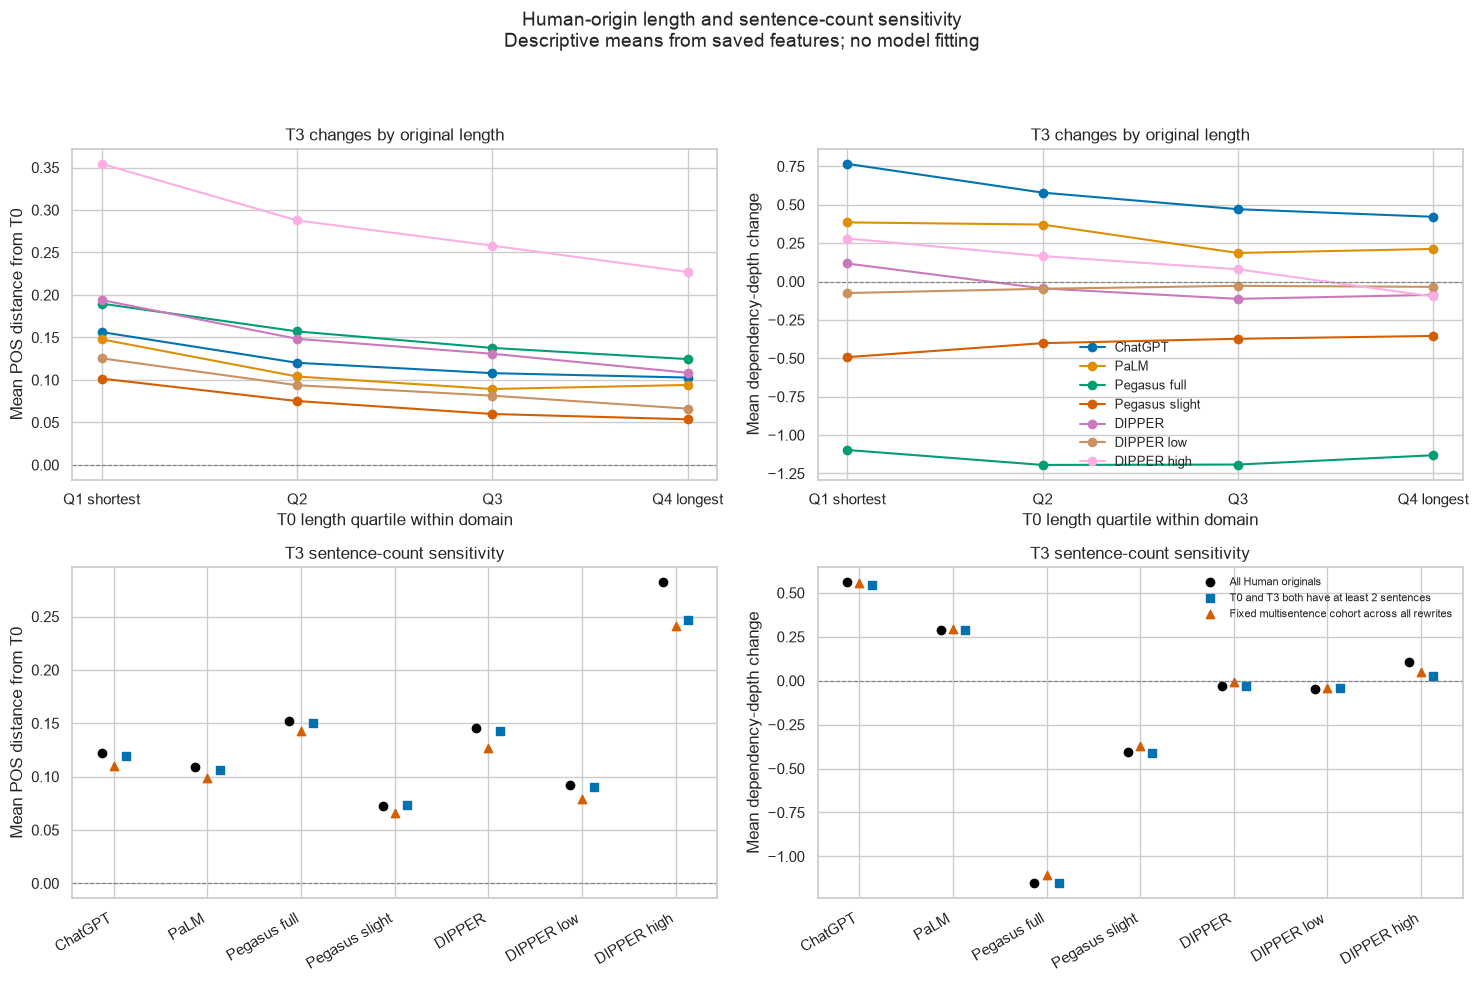

Human originals: 2,351
Fixed multisentence cohort across every configuration and round: 1,622
Original-length quartiles are defined separately within each domain.
Tied token counts stay together; quartile sizes may differ.
Pairwise restrictions can change the sample across stages.
The fixed cohort uses the same originals throughout.
Means and correlations are descriptive; no causal interpretation.
No feature extraction, classifier training, or bootstrap was performed.

T0 length boundaries:


,domain,n_originals,q25_tokens,q50_tokens,q75_tokens
0,cmv,227,233.00,341.0,496.5
1,eli5,452,83.75,166.0,315.5
2,sci_gen,227,126.00,160.0,202.0
3,tldr,371,63.00,83.0,99.0
4,wp,255,222.00,368.0,616.0
5,xsum,336,152.50,242.0,397.5
6,yelp,483,54.00,98.0,166.0



T3 sentence-count sensitivity:


,configuration,iteration,n_all,n_both_multisentence,retained_fraction,pos_distance_all,pos_distance_multisentence,pos_distance_difference,mean_dependency_depth_change_all,mean_dependency_depth_change_multisentence,mean_dependency_depth_change_difference
2,chatgpt,3,2351,2314,0.9843,0.1220,0.1198,-0.0023,0.5604,0.5449,-0.0155
5,dipper,3,2351,2313,0.9838,0.1457,0.1426,-0.0031,-0.0310,-0.0290,0.0020
8,dipper(high),3,2351,1712,0.7282,0.2822,0.2471,-0.0350,0.1077,0.0257,-0.0820
11,dipper(low),3,2351,2324,0.9885,0.0919,0.0903,-0.0017,-0.0465,-0.0415,0.0050
14,palm,3,2351,2305,0.9804,0.1091,0.1059,-0.0031,0.2891,0.2887,-0.0004
17,pegasus(full),3,2351,2321,0.9872,0.1525,0.1507,-0.0019,-1.1532,-1.1511,0.0021
20,pegasus(slight),3,2351,2328,0.9902,0.0728,0.0734,0.0007,-0.4058,-0.4094,-0.0036



T3 fixed-cohort results:


,configuration,iteration,n_originals,pos_distance,mean_dependency_depth_change
3,chatgpt,3,1622,0.1104,0.5576
7,dipper,3,1622,0.1266,-0.0068
11,dipper(high),3,1622,0.2412,0.0517
15,dipper(low),3,1622,0.0794,-0.0392
19,palm,3,1622,0.0983,0.2926
23,pegasus(full),3,1622,0.1429,-1.1077
27,pegasus(slight),3,1622,0.0658,-0.3728



Tables saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/stylometry
Figure saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/figures/update2/17_human_length_sentence_sensitivity.png


In [18]:
# Analyze length and sentence-count sensitivity from saved paired features.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

stylometry_dir = project_root / "experiments/update2/stylometry"
figure_dir = project_root / "figures/update2"
figure_dir.mkdir(parents=True, exist_ok=True)

input_path = stylometry_dir / "human_style_pairs.csv"
if not input_path.is_file():
    raise FileNotFoundError(f"Required saved table is missing: {input_path}")

pairs = pd.read_csv(
    input_path,
    dtype={"domain": str, "source": str, "key": str},
)

keys = ["domain", "source", "key"]
config_labels = {
    "chatgpt": "ChatGPT",
    "palm": "PaLM",
    "pegasus(full)": "Pegasus full",
    "pegasus(slight)": "Pegasus slight",
    "dipper": "DIPPER",
    "dipper(low)": "DIPPER low",
    "dipper(high)": "DIPPER high",
}
configs = list(config_labels)
metrics = ["pos_distance", "mean_dependency_depth_change"]

required = keys + [
    "configuration",
    "iteration",
    "token_count",
    "sentence_count",
    *metrics,
]

missing_columns = sorted(set(required) - set(pairs.columns))
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

assert pairs["source"].eq("Human").all()
assert set(pairs["configuration"]) == set(configs)
assert set(pairs["iteration"]) == {0, 1, 2, 3}
assert not pairs.duplicated(
    keys + ["configuration", "iteration"]
).any()

# T0 is repeated for plotting; verify identical baseline counts.
baseline_rows = pairs.loc[pairs["iteration"].eq(0)].copy()

for column in ["token_count", "sentence_count"]:
    assert (
        baseline_rows.groupby(keys)[column]
        .nunique()
        .eq(1)
        .all()
    ), f"Inconsistent T0 values: {column}"

baseline = (
    baseline_rows[keys + ["token_count", "sentence_count"]]
    .drop_duplicates(keys)
    .rename(columns={
        "token_count": "t0_token_count",
        "sentence_count": "t0_sentence_count",
    })
)

assert len(baseline) == 2351
assert baseline["t0_token_count"].gt(0).all()

# Define within-domain T0 length quartiles.
quartile_labels = ["Q1 shortest", "Q2", "Q3", "Q4 longest"]
baseline["length_group"] = ""

boundary_rows = []

for domain, subset in baseline.groupby("domain", sort=True):
    cuts = subset["t0_token_count"].quantile([0.25, 0.50, 0.75]).to_numpy()

    # Equal token counts stay in the same group.
    groups = np.searchsorted(
        cuts,
        subset["t0_token_count"].to_numpy(),
        side="left",
    )
    baseline.loc[subset.index, "length_group"] = [
        quartile_labels[index] for index in groups
    ]

    boundary_rows.append({
        "domain": domain,
        "n_originals": len(subset),
        "q25_tokens": cuts[0],
        "q50_tokens": cuts[1],
        "q75_tokens": cuts[2],
    })

boundaries = pd.DataFrame(boundary_rows)

data = pairs.merge(
    baseline,
    on=keys,
    how="left",
    validate="many_to_one",
)

assert data["t0_token_count"].notna().all()
assert np.isfinite(data[metrics].to_numpy(dtype=float)).all()

data["token_count_ratio"] = (
    data["token_count"] / data["t0_token_count"]
)
data["both_multisentence"] = (
    data["t0_sentence_count"].ge(2)
    & data["sentence_count"].ge(2)
)

rewrites = data.loc[data["iteration"].gt(0)].copy()

# Summarize style changes within original-length groups.
length_summary = (
    data.groupby(
        ["configuration", "iteration", "length_group"],
        observed=True,
    )
    .agg(
        n_originals=("key", "size"),
        mean_t0_tokens=("t0_token_count", "mean"),
        mean_token_count_ratio=("token_count_ratio", "mean"),
        pos_distance=("pos_distance", "mean"),
        mean_dependency_depth_change=(
            "mean_dependency_depth_change", "mean"
        ),
    )
    .reset_index()
)

# Compare unrestricted means with pairwise multisentence means.
sensitivity_rows = []

for (configuration, iteration), subset in rewrites.groupby(
    ["configuration", "iteration"]
):
    eligible = subset.loc[subset["both_multisentence"]]

    row = {
        "configuration": configuration,
        "iteration": iteration,
        "n_all": len(subset),
        "n_both_multisentence": len(eligible),
        "retained_fraction": len(eligible) / len(subset),
    }

    for metric in metrics:
        full_mean = subset[metric].mean()
        restricted_mean = eligible[metric].mean()

        row[f"{metric}_all"] = full_mean
        row[f"{metric}_multisentence"] = restricted_mean
        row[f"{metric}_difference"] = restricted_mean - full_mean

    sensitivity_rows.append(row)

sentence_sensitivity = pd.DataFrame(sensitivity_rows)

# A fixed cohort supports comparisons across all configurations and rounds.
cohort_flags = rewrites.groupby(keys)["both_multisentence"].all()
cohort_keys = cohort_flags.loc[cohort_flags].reset_index()[keys]

fixed_cohort = data.merge(
    cohort_keys,
    on=keys,
    how="inner",
    validate="many_to_one",
)

if fixed_cohort.empty:
    fixed_summary = pd.DataFrame(columns=[
        "configuration", "iteration", "n_originals",
        "pos_distance", "mean_dependency_depth_change",
    ])
else:
    fixed_summary = (
        fixed_cohort.groupby(["configuration", "iteration"])
        .agg(
            n_originals=("key", "size"),
            pos_distance=("pos_distance", "mean"),
            mean_dependency_depth_change=(
                "mean_dependency_depth_change", "mean"
            ),
        )
        .reset_index()
    )

# Spearman correlations via average ranks; no extra scipy dependency.
def spearman_correlation(x, y):
    if len(x) < 3 or x.nunique() < 2 or y.nunique() < 2:
        return np.nan
    return float(x.rank(method="average").corr(y.rank(method="average")))


correlation_rows = []

for (domain, configuration, iteration), subset in rewrites.groupby(
    ["domain", "configuration", "iteration"]
):
    for metric in metrics:
        correlation_rows.append({
            "domain": domain,
            "configuration": configuration,
            "iteration": iteration,
            "metric": metric,
            "n_originals": len(subset),
            "spearman_rho": spearman_correlation(
                subset["token_count_ratio"],
                subset[metric],
            ),
        })

correlations = pd.DataFrame(correlation_rows)

# Save descriptive outputs.
tables = {
    "human_t0_length_quartile_boundaries.csv": boundaries,
    "human_style_by_t0_length.csv": length_summary,
    "human_multisentence_sensitivity.csv": sentence_sensitivity,
    "human_fixed_multisentence_cohort.csv": fixed_summary,
    "human_length_style_correlations.csv": correlations,
}

for filename, table in tables.items():
    table.to_csv(stylometry_dir / filename, index=False)

# Plot T3 means by original-length group and sentence-count restriction.
sns.set_theme(style="whitegrid", context="notebook")
palette = sns.color_palette("colorblind", len(configs))
config_colors = dict(zip(configs, palette))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metric_labels = {
    "pos_distance": "Mean POS distance from T0",
    "mean_dependency_depth_change": "Mean dependency-depth change",
}

for column, metric in enumerate(metrics):
    ax = axes[0, column]

    for configuration in configs:
        subset = (
            length_summary.loc[
                length_summary["configuration"].eq(configuration)
                & length_summary["iteration"].eq(3)
            ]
            .set_index("length_group")
            .reindex(quartile_labels)
        )

        ax.plot(
            range(4),
            subset[metric],
            marker="o",
            color=config_colors[configuration],
            label=config_labels[configuration],
        )

    ax.set_xticks(range(4), quartile_labels)
    ax.set_xlabel("T0 length quartile within domain")
    ax.set_ylabel(metric_labels[metric])
    ax.set_title("T3 changes by original length")
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    ax = axes[1, column]
    t3 = (
        sentence_sensitivity.loc[
            sentence_sensitivity["iteration"].eq(3)
        ]
        .set_index("configuration")
        .reindex(configs)
    )
    positions = np.arange(len(configs))

    ax.scatter(
        positions - 0.13,
        t3[f"{metric}_all"],
        marker="o",
        color="black",
        label="All Human originals",
    )
    ax.scatter(
        positions + 0.13,
        t3[f"{metric}_multisentence"],
        marker="s",
        color="#0072B2",
        label="T0 and T3 both have at least 2 sentences",
    )

    if not fixed_summary.empty:
        fixed_t3 = (
            fixed_summary.loc[fixed_summary["iteration"].eq(3)]
            .set_index("configuration")
            .reindex(configs)
        )
        ax.scatter(
            positions,
            fixed_t3[metric],
            marker="^",
            color="#D55E00",
            label="Fixed multisentence cohort across all rewrites",
        )

    ax.set_xticks(
        positions,
        [config_labels[configuration] for configuration in configs],
        rotation=30,
        ha="right",
    )
    ax.set_ylabel(metric_labels[metric])
    ax.set_title("T3 sentence-count sensitivity")
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

axes[0, 1].legend(fontsize=9, frameon=False)
axes[1, 1].legend(fontsize=8, frameon=False)

fig.suptitle(
    "Human-origin length and sentence-count sensitivity\n"
    "Descriptive means from saved features; no model fitting",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])

figure_path = (
    figure_dir / "17_human_length_sentence_sensitivity.png"
)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Human originals: {len(baseline):,}")
print(
    "Fixed multisentence cohort across every configuration and round: "
    f"{len(cohort_keys):,}"
)
print("Original-length quartiles are defined separately within each domain.")
print("Tied token counts stay together; quartile sizes may differ.")
print("Pairwise restrictions can change the sample across stages.")
print("The fixed cohort uses the same originals throughout.")
print("Means and correlations are descriptive; no causal interpretation.")
print("No feature extraction, classifier training, or bootstrap was performed.")

print("\nT0 length boundaries:")
display(boundaries.round(2))

print("\nT3 sentence-count sensitivity:")
display(
    sentence_sensitivity.loc[
        sentence_sensitivity["iteration"].eq(3)
    ].round(4)
)

print("\nT3 fixed-cohort results:")
display(
    fixed_summary.loc[
        fixed_summary["iteration"].eq(3)
    ].round(4)
)

print(f"\nTables saved to: {stylometry_dir}")
print(f"Figure saved to: {figure_path}")

### Findings: length and sentence-count sensitivity

At T3, mean POS distance is greater in the shortest than in the longest
within-domain T0 length quartile for all seven configurations. This association
may reflect both linguistic changes and length-dependent variability in
estimated POS proportions; it does not establish greater stylistic loss in
shorter texts.

Requiring both T0 and T3 to contain at least two sentences retains approximately
98–99% of originals for six configurations, with small changes in their mean
POS distances. DIPPER high retains only 72.8%: its mean POS distance decreases
from 0.2822 to 0.2471, and its mean dependency-depth change decreases from
+0.1077 to +0.0257. Its small positive depth change is therefore sensitive to
the sentence-count restriction.

A fixed cohort of 1,622 originals has at least two sentences in T0 and every
rewrite. Within this cohort, DIPPER high still has the largest T3 POS distance
(0.2412). ChatGPT and PaLM retain positive mean depth changes, while both
Pegasus configurations retain negative changes.

These are descriptive sensitivity checks without new confidence intervals.
Restrictions change the analyzed population and do not fully control for
length or establish causal effects.

## 15. Random semantic review of DIPPER high

Sample five complete chains per domain without using similarity scores.
Compare T1, T2 and T3 separately with T0 using the predefined semantic labels.
The following cells export the sample and save the review decisions and evidence.

In [19]:
# Export a reproducible random sample for semantic review.
from pathlib import Path
import html
import json

import numpy as np
import pandas as pd

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

data_root = (
    project_root.parent
    / "Ship_of_theseus_paraphrased_copus"
    / "paraphrased_datasets"
)

manifest_path = (
    project_root / "data/metadata/shared_sample_manifest.csv"
)
audit_dir = project_root / "experiments/update2/semantic_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

domains = ["cmv", "eli5", "sci_gen", "tldr", "wp", "xsum", "yelp"]
keys = ["domain", "source", "key"]
seed = 6120
n_per_domain = 5

versions = {
    "original": 0,
    "dipper(high)": 1,
    "dipper(high)_dipper(high)": 2,
    "dipper(high)_dipper(high)_dipper(high)": 3,
}

sample_path = audit_dir / "dipper_high_random_sample.csv"
review_path = audit_dir / "dipper_high_review_annotations.csv"

manifest = pd.read_csv(
    manifest_path,
    dtype=str,
    keep_default_na=False,
)[keys].sort_values(keys).reset_index(drop=True)

assert len(manifest) == 16659
assert not manifest.duplicated(keys).any()
assert set(manifest["domain"]) == set(domains)

# Preserve the same sample on subsequent runs.
if sample_path.is_file():
    sample = pd.read_csv(
        sample_path,
        dtype=str,
        keep_default_na=False,
    )

    assert set(sample.columns) == set(keys + ["audit_id"])
    assert not sample.duplicated(keys).any()
    assert not sample["audit_id"].duplicated().any()
    assert sample.groupby("domain").size().to_dict() == {
        domain: n_per_domain for domain in domains
    }

    coverage = sample.merge(
        manifest,
        on=keys,
        how="left",
        indicator=True,
        validate="one_to_one",
    )
    assert coverage["_merge"].eq("both").all()
    print("Loaded the existing random sample.")

else:
    rng = np.random.default_rng(seed)
    frames = []

    for domain in domains:
        candidates = manifest.loc[
            manifest["domain"].eq(domain)
        ].reset_index(drop=True)

        if len(candidates) < n_per_domain:
            raise ValueError(f"Insufficient eligible chains: {domain}")

        positions = rng.choice(
            len(candidates),
            size=n_per_domain,
            replace=False,
        )
        frames.append(candidates.iloc[positions])

    sample = pd.concat(frames, ignore_index=True)
    sample.insert(
        0,
        "audit_id",
        [f"DH-{index:03d}" for index in range(1, len(sample) + 1)],
    )
    sample.to_csv(sample_path, index=False)
    print("Created a domain-stratified random sample.")

# Load the sampled texts directly from the original corpus files.
text_frames = []

for domain in domains:
    raw_path = data_root / f"{domain}_paraphrased.csv"

    if not raw_path.is_file():
        raise FileNotFoundError(f"Raw corpus file is missing: {raw_path}")

    raw = pd.read_csv(
        raw_path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
        usecols=["source", "key", "version_name", "text"],
    )

    selected = raw.loc[
        raw["version_name"].isin(versions)
    ].merge(
        sample.loc[
            sample["domain"].eq(domain),
            ["audit_id", "source", "key"],
        ],
        on=["source", "key"],
        how="inner",
        validate="many_to_one",
    )

    selected["domain"] = domain
    selected["iteration"] = selected["version_name"].map(versions)
    text_frames.append(selected)

texts = pd.concat(text_frames, ignore_index=True)

assert len(texts) == len(sample) * 4
assert not texts.duplicated(keys + ["version_name"]).any()
assert texts.groupby("audit_id")["iteration"].apply(
    lambda values: set(values) == {0, 1, 2, 3}
).all()
assert texts["text"].map(
    lambda value: any(character.isalnum() for character in value)
).all()

texts = texts.sort_values(["audit_id", "iteration"])
texts.to_csv(
    audit_dir / "dipper_high_random_sample_texts.csv",
    index=False,
)

# Annotation labels remain blank until a reviewer reads the texts.
annotation_columns = [
    "audit_id",
    *keys,
    "iteration",
    "reviewer",
    "semantic_label",
    "evidence",
    "notes",
]

annotation_rows = [
    {
        "audit_id": row.audit_id,
        "domain": row.domain,
        "source": row.source,
        "key": row.key,
        "iteration": iteration,
        "reviewer": "",
        "semantic_label": "",
        "evidence": "",
        "notes": "",
    }
    for row in sample.itertuples(index=False)
    for iteration in [1, 2, 3]
]

annotations = pd.DataFrame(
    annotation_rows,
    columns=annotation_columns,
)

if review_path.is_file():
    existing = pd.read_csv(
        review_path,
        dtype=str,
        keep_default_na=False,
    )

    id_columns = ["audit_id", *keys, "iteration"]

    expected_ids = set(
        annotations[id_columns].astype(str)
        .itertuples(index=False, name=None)
    )
    existing_ids = set(
        existing[id_columns].astype(str)
        .itertuples(index=False, name=None)
    )

    assert not existing.duplicated(id_columns).any()
    assert existing_ids == expected_ids
    print("Existing annotations preserved; no labels overwritten.")

else:
    annotations.to_csv(review_path, index=False)

guidelines = [
    "# DIPPER High Random Semantic Review",
    "",
    "## Sample",
    "",
    "Five complete chains are sampled uniformly without replacement within",
    "each of seven domains from the 16,659-original clean-chain manifest.",
    "Original source categories are retained but are not separately stratified.",
    "The sample contains 35 chains and 105 T0-versus-rewrite comparisons.",
    "Sampling seed: 6120. Selection does not use similarity scores.",
    "",
    "This exploratory audit includes all original-source categories.",
    "It is not restricted to the Human-origin stylometry sample.",
    "",
    "## Review procedure",
    "",
    "Compare T1, T2 and T3 independently against T0, not the previous round.",
    "Read the full text before assigning one label:",
    "",
    "- preserved: central meaning and important claims remain consistent;",
    "  differences are primarily wording or structure.",
    "- partial_change: the central topic remains, but important information",
    "  is omitted, added or changed.",
    "- major_change: the central message is replaced, substantially contradicted",
    "  or dominated by unrelated content.",
    "- uncertain: the comparison cannot be judged confidently.",
    "",
    "Record a short supporting quotation or concrete discrepancy in evidence.",
    "Enter the reviewer identifier and any qualification in notes.",
    "Labels concern fidelity to T0, not whether T0 itself is factually correct.",
    "Compression alone is not sufficient evidence of major_change.",
    "",
    "For multiple reviewers, copy the annotation template for independent",
    "labeling, then retain individual labels before adjudication.",
    "An AI-assisted review must be identified as such and must not be reported",
    "as independent human annotation.",
    "",
    "## Reporting",
    "",
    "Report reviewed counts and label distributions by stage and domain.",
    "The equal allocation to domains is not proportional to corpus size.",
    "A simple pooled percentage is an equal-domain sample summary,",
    "not an estimate of full-corpus prevalence.",
    "The sample also excludes incomplete and invalid chains.",
    "No labels or semantic findings are generated by the export code.",
    "",
]

(audit_dir / "README_semantic_review.md").write_text(
    "\n".join(guidelines),
    encoding="utf-8",
)

(audit_dir / "sampling_settings.json").write_text(
    json.dumps(
        {
            "seed": seed,
            "configuration": "dipper(high)",
            "sample_frame": str(manifest_path.relative_to(project_root)),
            "originals_in_frame": len(manifest),
            "chains_per_domain": n_per_domain,
            "n_chains": len(sample),
            "selection": "uniform without replacement within domain",
            "selection_uses_similarity_scores": False,
        },
        indent=2,
    ) + "\n",
    encoding="utf-8",
)

# Write a browser-readable page without truncating any text.
page = [
    "<!doctype html>",
    '<html lang="en"><meta charset="utf-8">',
    "<title>DIPPER High Random Semantic Review</title>",
    "<style>",
    "body{font-family:system-ui;max-width:1400px;margin:32px auto;padding:0 20px;}",
    "section{border-top:2px solid #bbb;margin-top:36px;padding-top:12px;}",
    ".texts{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:16px;}",
    "article{background:#f5f6f8;padding:16px;overflow-wrap:anywhere;}",
    "pre{white-space:pre-wrap;font-family:inherit;line-height:1.5;}",
    "@media(max-width:800px){.texts{grid-template-columns:1fr;}}",
    "</style>",
    "<h1>DIPPER High: Random Semantic Review</h1>",
    "<p>Compare each rewrite against T0. Full texts are retained. "
    "Similarity scores are intentionally omitted.</p>",
    "<p>Labels: preserved / partial_change / major_change / uncertain. "
    "Record labels and evidence in the annotation CSV.</p>",
]

for row in sample.itertuples(index=False):
    subset = texts.loc[texts["audit_id"].eq(row.audit_id)]

    title = (
        f"{row.audit_id} | {row.domain} | {row.source} | {row.key}"
    )
    page.extend([
        "<section>",
        f"<h2>{html.escape(title)}</h2>",
        '<div class="texts">',
    ])

    for text_row in subset.itertuples(index=False):
        page.extend([
            "<article>",
            f"<h3>T{text_row.iteration}</h3>",
            f"<pre>{html.escape(text_row.text)}</pre>",
            "</article>",
        ])

    page.extend(["</div>", "</section>"])

page.append("</html>")

html_path = audit_dir / "dipper_high_random_review.html"
html_path.write_text("\n".join(page), encoding="utf-8")

print(f"\nSampled chains: {len(sample):,}")
print(f"Exported text versions: {len(texts):,}")
print(f"Comparisons awaiting annotation: {len(annotations):,}")
print("No model inference or automatic semantic labeling was performed.")

display(
    sample.groupby(["domain", "source"])
    .size()
    .unstack(fill_value=0)
)

print(f"\nReview page: {html_path}")
print(f"Annotation table: {review_path}")
print(f"All review files saved to: {audit_dir}")

Created a domain-stratified random sample.

Sampled chains: 35
Exported text versions: 140
Comparisons awaiting annotation: 105
No model inference or automatic semantic labeling was performed.


source,BigScience,Eleuther-AI,Human,LLAMA,OpenAI,PaLM,Tsinghua
domain,,,,,,,
cmv,0,0,1,2,2,0,0
eli5,2,1,0,1,0,0,1
sci_gen,0,0,0,1,2,1,1
tldr,2,1,0,0,1,1,0
wp,3,0,1,0,1,0,0
xsum,0,1,1,0,0,1,2
yelp,0,0,0,1,0,3,1



Review page: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/semantic_audit/dipper_high_random_review.html
Annotation table: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/semantic_audit/dipper_high_review_annotations.csv
All review files saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/semantic_audit


In [20]:
# Save completed semantic comparisons and descriptive summaries.
from pathlib import Path

import pandas as pd

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

audit_dir = project_root / "experiments/update2/semantic_audit"
input_path = audit_dir / "dipper_high_random_sample_texts.csv"

texts = pd.read_csv(
    input_path,
    dtype={
        "audit_id": str,
        "domain": str,
        "source": str,
        "key": str,
    },
    keep_default_na=False,
)

texts["iteration"] = pd.to_numeric(
    texts["iteration"], errors="raise"
).astype(int)

assert len(texts) == 140
assert not texts.duplicated(["audit_id", "iteration"]).any()

# Each entry contains a T0 summary and separate T1, T2, T3 observations.
review = {
    "DH-001": [
        "Marriage history, contemporary marriage and Hindu wedding traditions.",
        "A boy walks through a city and countryside and encounters his father.",
        "Family relationships, roads, villages and a coastal scene replace the marriage discussion.",
        "Yuku, flooding, roads and village life replace the marriage discussion.",
    ],
    "DH-002": [
        "American national pride, historical shortcomings and positive national achievements.",
        "A young king visits a sick father and asks forgiveness.",
        "A son, a physician, a palace and an imperial command replace the historical argument.",
        "Animal comparisons, threats and laughter replace the historical argument.",
    ],
    "DH-003": [
        "Bernie Sanders's political effectiveness and gun-control record.",
        "An aeronaut and aircraft narrative dominates; isolated gun references do not preserve the political argument.",
        "Bazarov and personal dialogue dominate; a pistol reference does not retain the claims about Sanders.",
        "Bazarov discusses a window, an enemy and boxes; the political argument is absent.",
    ],
    "DH-004": [
        "A Cutthroat Kitchen strategy: concentrate sabotages on one competitor.",
        "A king, property, money and a merchant's wife replace the cooking-game strategy.",
        "Eagles, chickens, geese and old men replace the cooking-game strategy.",
        "A general and dragon exchange dialogue; the competition and strategy are absent.",
    ],
    "DH-005": [
        "How presidents and legislators can influence the economy through policy.",
        "Ancestral kingdoms, a dungeon, a palace and family matters replace economic policy.",
        "Sleep, health, death and a mother's reassurance replace economic policy.",
        "Personal recollections of London and Ned Land replace economic policy.",
    ],
    "DH-006": [
        "The Simpsons animation methods, cels, layers and computer production.",
        "A foundry, military movements, government and religious commentary replace animation methods.",
        "Pierre, a village journey, carts and cooking imagery replace animation methods.",
        "Crewmen, fortifications, ships and travel replace animation methods.",
    ],
    "DH-007": [
        "Dry eyes, contact solution and an eye-symptom questionnaire.",
        "Major Ahab and military or social encounters replace the eye discussion.",
        "A detachment captain visits officials and complains of being slighted.",
        "A general and Nikolay Parfenovitch exchange unrelated dialogue.",
    ],
    "DH-008": [
        "Impact, falling, reaction forces and a personal falling anecdote.",
        "A river scene involving Pazhuvettarayar and Vandiyadeva replaces the physical explanation.",
        "Boats, an elephant, a palanquin and Chola figures replace the physical explanation.",
        "A curtain, women and a Vaishnavite altercation replace the physical explanation.",
    ],
    "DH-009": [
        "A mixed discussion of budgets, economics, books, politics, consultancy and a watch.",
        "A carriage, Mitford, pins and accusations of theft replace the original subjects.",
        "Only a short statement about a penny remains; the original claims are not retained.",
        "A curate's dinner, Naples, beggars and the Church replace the original subjects.",
    ],
    "DH-010": [
        "Spacecraft maintenance, deorbiting and claims about Columbia's onboard systems.",
        "The Palmerston, cargo holds, sails and a lost screw replace the spacecraft discussion.",
        "Ships, pirates, sailors and wind replace the spacecraft discussion.",
        "A vessel, a captain and threats of a massacre replace the spacecraft discussion.",
    ],
    "DH-011": [
        "Perturbations on a rod, boundary conditions and Laplace-transform solutions.",
        "Characters discuss tricks, betting and koans instead of the mathematical problem.",
        "Named characters, supernatural powers and koans replace the mathematical problem.",
        "Monkey, Guanyin, Buddha and heavenly gates replace the mathematical problem.",
    ],
    "DH-012": [
        "Eigenvalue conditions for edge-disjoint spanning trees in regular graphs.",
        "Grass, lips and a person writing replace the graph-theoretic conditions.",
        "A person sits in a doorway looking at paper; the graph-theoretic result is absent.",
        "A remembered woman, Heaven and a proverb replace the graph-theoretic result.",
    ],
    "DH-013": [
        "Efficient and accurate pseudoinverse computation for sparse feature matrices.",
        "Fields, soil, trees and a plantation replace the matrix-computation discussion.",
        "A dove, townsfolk and a grove replace the matrix-computation discussion.",
        "A personal remark about names and counting replaces the matrix-computation discussion.",
    ],
    "DH-014": [
        "Gradient-based adversarial text generation to evaluate classifier robustness.",
        "Kohe speaks about Heaven, bodies, friends and enemies instead of adversarial text.",
        "Fragmentary dialogue about refusal replaces the algorithm and evaluation.",
        "Vandiyathevan discusses the price of a painting instead of classifier robustness.",
    ],
    "DH-015": [
        "A variational-autoencoder architecture for music source separation.",
        "A magic herb, Gautama, rivers and lotus flowers replace the source-separation method.",
        "Monkey and the Master discuss religious matters instead of the source-separation method.",
        "Monkey mentions mountain spirits; the technical method and results are absent.",
    ],
    "DH-016": [
        "Vultr Talon cloud GPUs, virtual machines and pricing.",
        "A king's daughter, Nandini, Sita and divine imagery replace cloud computing.",
        "Sandesh, Chola royalty and marriage rites replace cloud computing.",
        "Sandesh, palace guards and a commander replace cloud computing.",
    ],
    "DH-017": [
        "Grafana Mimir, Prometheus monitoring, storage and dashboard components.",
        "Mitterrand's convulsions and his mother's efforts replace monitoring software.",
        "Madame Aubert and derogatory personal commentary replace monitoring software.",
        "Madame de Morcerf and Monsieur de Lorimier discuss spying instead of software.",
    ],
    "DH-018": [
        "Assam internet shutdowns, citizenship protests, arrests and communication restrictions.",
        "Travel to Amaravati, a river crossing and fetching a prince replace the protest report.",
        "Scriptures, guards, imperial edicts and a boat replace the protest report.",
        "A temple journey, scrolls and an old man's movements replace the protest report.",
    ],
    "DH-019": [
        "Nebular UI components, themes and authentication modules.",
        "Officials are thrown from a boat; the UI library and its features are absent.",
        "Named characters conduct an ambush; the software description is absent.",
        "Cao Huan attacks with a sword; the software description is absent.",
    ],
    "DH-020": [
        "Facebook Horizon, virtual reality, avatars, creation tools and moderation.",
        "A journey, wolves, a killing and an injured woman replace the VR platform description.",
        "Peter Perkhotin, Ivan Fyodorovich, horses and wolves replace the VR platform description.",
        "Dialogue about wolves and holding a candle replaces the VR platform description.",
    ],
    "DH-021": [
        "An imminent-death scenario followed by questions about medical help.",
        "The mother comparison remains briefly, but sociability and a musket scene replace the emergency.",
        "Brother Jin's optimism and conversational preferences replace the medical emergency.",
        "Named companions, a river and a steep path replace the medical emergency.",
    ],
    "DH-022": [
        "A blindness narrative followed by administrative grant and deadline provisions.",
        "A king, a falcon, Nandini and killing demons replace both original subjects.",
        "Returning to a palace, refreshments and a battle replace both original subjects.",
        "Tea, food and a girlfriend's affection replace both original subjects.",
    ],
    "DH-023": [
        "A mother's illness, family involvement in life support and treatment uncertainty.",
        "A vigil, vengeance, divine will and saving a sister replace the medical discussion.",
        "A storm, dogs, a mill, chickens and a lion replace the medical discussion.",
        "An actress and a network of household characters replace the medical discussion.",
    ],
    "DH-024": [
        "A romantic opening followed by extensive material on illegal dumping, waste policy and other news.",
        "A kissing fragment remains, but unrelated surreal scenes dominate and the extensive policy material is absent.",
        "A Canadian, Courfeyrac, insults and drinking replace the original mixture of subjects.",
        "Le Brun, Condor, a Canadian and confrontational dialogue replace the original mixture of subjects.",
    ],
    "DH-025": [
        "A narrator envies others' deaths while a demon slowly dismembers them.",
        "Military dialogue about being shot replaces the named characters and demon scenario.",
        "Lieutenant Andreyev and Nelyudov discuss a story and soup instead of the demon scenario.",
        "Nikolay Parfenovich speaks about stories; the demon scenario is absent.",
    ],
    "DH-026": [
        "The Nobel Peace Prize shared by Sirleaf, Gbowee and Karman.",
        "Oblomov, a mule and another character replace the prize announcement.",
        "A crowd greets a visiting officer instead of describing the peace prize.",
        "Nastasia, a dagger and a squad replace the peace-prize announcement.",
    ],
    "DH-027": [
        "A Jet2 aircraft evacuation and investigation of electrical and escape-chute failures.",
        "Corpses, death imagery and a strange room replace the aircraft incident.",
        "Boats, sailors, seating and death imagery replace the aircraft investigation.",
        "A church-going house, Ivan and personal encounters replace the aircraft investigation.",
    ],
    "DH-028": [
        "Liverpool musician Angus Carpenter's fraud charges, conviction and retrial.",
        "Philip's anniversary, an army shipment and Caesar replace the fraud case.",
        "Town sewers, gamekeepers, fleas and knights replace the fraud case.",
        "An upstart riding and deceiving men replaces the fraud case.",
    ],
    "DH-029": [
        "A mixed sports report containing named players, scores and suspensions.",
        "A mistress of war, an ecclesiastical vestry and domestic relations replace the sports events.",
        "A company advances toward monarchs; the sports events and results are absent.",
        "Only a statement about Nandini remains; the sports report is absent.",
    ],
    "DH-030": [
        "Terrorism-related arrests in Italy, Britain and Norway and alleged Syria or Iraq travel.",
        "Arrest vocabulary remains, but countries, events and claims are replaced by unrelated attacks and character descriptions.",
        "Personal treason, British tabloids and a joke replace the arrest report.",
        "A personal question about respect and a bed replaces the arrest report.",
    ],
    "DH-031": [
        "A positive Sonoma Grille review covering service, dishes, drinks and repeat visits.",
        "A rally, a gun battery, General Plehwe and military orders replace the restaurant review.",
        "A landlady, ballroom dancing and supplying vegetables to regiments replace the restaurant review.",
        "Weapons, an apartment, a ward and hypnosis replace the restaurant review.",
    ],
    "DH-032": [
        "A positive hair-coloring review praising same-day availability, price and results.",
        "Establishments, guest rooms, dresses and fish replace the hair-coloring experience.",
        "Ladders, windows, snow and a child's coastal imaginings replace the salon review.",
        "A chain, water, a mirror and crystal imagery replace the salon review.",
    ],
    "DH-033": [
        "A Marquee Dayclub review discussing music, crowds, pools, price and location.",
        "Caves, boats and travel toward southern India replace the venue review.",
        "A river, Egyptian horses, pilgrims and a bath replace the venue review.",
        "A koodam, boats, bathing and a cave replace the venue review.",
    ],
    "DH-034": [
        "Repeated failed window-tinting appointments and unanswered calls involving Steve.",
        "A short Steve/tinting fragment survives at the end, but extensive unrelated literary and historical material dominates.",
        "A brief Steve/next-day fragment remains, but the tinting complaint is largely replaced by unrelated scenes.",
        "Religious commentary, gems, military scenes and injuries replace the tinting complaint.",
    ],
    "DH-035": [
        "A positive Claim Jumpers group-meal review describing bread, appetizers, steak and seafood.",
        "A lighthouse, company business, an alleged murder and a captain replace the meal review.",
        "A constable, horses, council business and money replace the meal review.",
        "An argument involving Meiers and a consul replaces the meal review.",
    ],
}

assert set(review) == set(texts["audit_id"])
assert all(len(entry) == 4 for entry in review.values())

records = []

for audit_id, subset in texts.groupby("audit_id", sort=True):
    assert set(subset["iteration"]) == {0, 1, 2, 3}
    assert len(subset[["domain", "source", "key"]].drop_duplicates()) == 1

    stages = subset.set_index("iteration")
    baseline = stages.loc[0]
    observations = review[audit_id]

    for iteration in [1, 2, 3]:
        current = stages.loc[iteration]

        records.append({
            "audit_id": audit_id,
            "domain": baseline["domain"],
            "source": baseline["source"],
            "key": baseline["key"],
            "iteration": iteration,
            "semantic_label": "major_change",
            "t0_content": observations[0],
            "rewrite_content": observations[iteration],
            "evidence": (
                f"T0: {observations[0]} "
                f"T{iteration}: {observations[iteration]} "
                "The central content is replaced or dominated by unrelated material."
            ),
            "t0_excerpt": baseline["text"].strip()[:250],
            "rewrite_excerpt": current["text"].strip()[:250],
        })

results = pd.DataFrame(records)

assert len(results) == 105
assert not results.duplicated(["audit_id", "iteration"]).any()
assert results["evidence"].str.len().gt(0).all()

labels = ["preserved", "partial_change", "major_change", "uncertain"]

stage_summary = pd.crosstab(
    results["iteration"],
    results["semantic_label"],
).reindex(index=[1, 2, 3], columns=labels, fill_value=0)
stage_summary["n_comparisons"] = stage_summary[labels].sum(axis=1)

domain_summary = pd.crosstab(
    [results["domain"], results["iteration"]],
    results["semantic_label"],
).reindex(columns=labels, fill_value=0)
domain_summary["n_comparisons"] = domain_summary[labels].sum(axis=1)

results_path = audit_dir / "dipper_high_semantic_review_results.csv"

# Preserve a differing existing result instead of silently replacing it.
if results_path.is_file():
    existing = pd.read_csv(results_path, keep_default_na=False)
    if not existing.astype(str).equals(results.astype(str)):
        raise FileExistsError(
            "A different review result already exists. "
            "Preserve or rename that file before saving this version."
        )
    print("Identical review results already exist.")
else:
    results.to_csv(results_path, index=False)

stage_summary.to_csv(
    audit_dir / "dipper_high_semantic_review_by_stage.csv"
)
domain_summary.to_csv(
    audit_dir / "dipper_high_semantic_review_by_domain.csv"
)

print(f"Complete chains reviewed: {results['audit_id'].nunique()}")
print(f"T0-versus-rewrite comparisons: {len(results)}")
print("Excerpts are navigation aids; judgments use the complete supplied texts.")
print("Results describe this sample, not full-corpus prevalence.")

display(stage_summary)
print(f"Results saved to: {results_path}")

Complete chains reviewed: 35
T0-versus-rewrite comparisons: 105
Excerpts are navigation aids; judgments use the complete supplied texts.
Results describe this sample, not full-corpus prevalence.


semantic_label,preserved,partial_change,major_change,uncertain,n_comparisons
iteration,,,,,
1,0,0,35,0,35
2,0,0,35,0,35
3,0,0,35,0,35


Results saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/experiments/update2/semantic_audit/dipper_high_semantic_review_results.csv


### Findings: random semantic review of DIPPER high

We examined 35 randomly selected complete chains, with five chains per domain.
Each rewrite was compared with its own T0, yielding 105 comparisons.

All 35 comparisons at each of T1, T2 and T3 were classified as major semantic
changes. The dominant pattern was replacement of the original subject with
unrelated narrative. Some rewrites retained isolated phrases or entities,
but these fragments did not preserve the central content.

These findings extend the earlier score-selected diagnostic cases to a
domain-stratified random sample. They do not establish that every DIPPER high
output changes meaning, identify the cause of the deviations, or provide
independent annotation agreement. The three stages belong to the same 35
chains and are not 105 independent samples.

DIPPER high should therefore be interpreted cautiously in style and attribution
analyses: observed changes cannot be assumed to arise from content-preserving
paraphrasing.

## 16. Saved-artifact checks and review packaging

Check required tables for existence and nonempty content, then package the saved notebook, selected result tables and figures. Archive integrity and artifact checks do not establish successful end-to-end execution from an empty kernel.

Save the notebook before packaging. The bundle contains the notebook version saved on disk, not unsaved editor changes.

In [14]:
# Verify saved analysis artifacts and package the Update 2 results.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (
        path for path in candidates
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Run this notebook from the project directory or its notebooks folder."
    )

output_dir = project_root / "experiments" / "update2"
figure_dir = project_root / "figures" / "update2"
notebook_path = project_root / "notebooks" / "02_update2.ipynb"

required_tables = {
    "Stylometry": (
        output_dir / "stylometry" / "human_style_overall.csv"
    ),
    "Stylometry uncertainty": (
        output_dir / "stylometry" / "human_style_bootstrap_ci.csv"
    ),
    "PCA coordinates": (
        output_dir / "identity_trajectory"
        / "human_test_pca_coordinates.csv"
    ),
    "Dispersion robustness": (
        output_dir / "identity_trajectory"
        / "human_test_dispersion_robustness.csv"
    ),
    "Source attribution": (
        output_dir / "source_attribution" / "test_metrics.csv"
    ),
    "Source attribution uncertainty": (
        output_dir / "source_attribution"
        / "test_group_bootstrap_ci.csv"
    ),
    "Paraphraser fingerprints": (
        output_dir / "paraphraser_fingerprints"
        / "syntax_test_metrics.csv"
    ),
    "Fingerprint uncertainty": (
        output_dir / "paraphraser_fingerprints"
        / "syntax_test_group_bootstrap_ci.csv"
    ),
    "Fingerprint paired comparisons": (
        output_dir / "paraphraser_fingerprints"
        / "syntax_paired_comparisons.csv"
    ),
}

missing = [
    str(path.relative_to(project_root))
    for path in [notebook_path, *required_tables.values()]
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Required files are missing:\n" + "\n".join(missing)
    )

audit_rows = []

for analysis, path in required_tables.items():
    table = pd.read_csv(path)

    if table.empty:
        raise ValueError(f"Saved table is empty: {path}")

    audit_rows.append({
        "analysis": analysis,
        "rows": len(table),
        "file": str(path.relative_to(project_root)),
    })

audit = pd.DataFrame(audit_rows)
print("Required saved tables are present and nonempty.")
display(audit)

analysis_directories = [
    output_dir / "stylometry",
    output_dir / "identity_trajectory",
    output_dir / "source_attribution",
    output_dir / "paraphraser_fingerprints",
]

package_files = {notebook_path}

for directory in analysis_directories:
    package_files.update(directory.rglob("*.csv"))

package_files.update(output_dir.glob("*.csv"))
package_files.update(figure_dir.glob("*.png"))
package_files.update(figure_dir.glob("*.pdf"))

package_files = sorted(
    path for path in package_files if path.is_file()
)

archive_path = project_root / "update2_review_bundle.zip"

with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for path in package_files:
        archive.write(
            path,
            arcname=str(path.relative_to(project_root)),
        )

with ZipFile(archive_path, "r") as archive:
    damaged_member = archive.testzip()

if damaged_member is not None:
    raise RuntimeError(f"Archive verification failed: {damaged_member}")

print(f"Packaged files: {len(package_files):,}")
print(f"Archive size: {archive_path.stat().st_size / (1024 ** 2):.1f} MB")
print(f"Review bundle saved to: {archive_path}")
print("Archive integrity check passed.")
print("This check verifies saved files, not end-to-end notebook execution.")

Required saved tables are present and nonempty.


,analysis,rows,file
0,Stylometry,28,experiments/update2/stylometry/human_style_ove...
1,Stylometry uncertainty,56,experiments/update2/stylometry/human_style_boo...
2,PCA coordinates,7810,experiments/update2/identity_trajectory/human_...
3,Dispersion robustness,84,experiments/update2/identity_trajectory/human_...
4,Source attribution,28,experiments/update2/source_attribution/test_me...
5,Source attribution uncertainty,22,experiments/update2/source_attribution/test_gr...
6,Paraphraser fingerprints,4,experiments/update2/paraphraser_fingerprints/s...
7,Fingerprint uncertainty,5,experiments/update2/paraphraser_fingerprints/s...
8,Fingerprint paired comparisons,8,experiments/update2/paraphraser_fingerprints/s...


Packaged files: 48
Archive size: 26.1 MB
Review bundle saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/update2_review_bundle.zip
Archive integrity check passed.
This check verifies saved files, not end-to-end notebook execution.


## 17. Archive historical split manifests

Move the two obsolete 12,523-original split manifests to `experiments/update2/archive/legacy_12523_split/`. Preserve the current `full_clean_v1` manifests and exclude historical splits from the review bundle.

In [15]:
# Archive obsolete split manifests and rebuild the review bundle.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

output_dir = project_root / "experiments" / "update2"
figure_dir = project_root / "figures" / "update2"
notebook_path = project_root / "notebooks" / "02_update2.ipynb"
archive_dir = output_dir / "archive" / "legacy_12523_split"

current_names = [
    "group_split_full_clean_v1.csv",
    "original_split_full_clean_v1.csv",
]

legacy_names = [
    "group_split_manifest.csv",
    "original_split_manifest.csv",
]

# Verify current artifacts before moving any legacy files.
for path in [notebook_path, *[output_dir / name for name in current_names]]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file is missing: {path}")

# Check every destination before making changes.
for name in legacy_names:
    source = output_dir / name
    destination = archive_dir / name

    if source.exists() and destination.exists():
        raise FileExistsError(
            f"Both active and archived copies exist: {name}. "
            "Resolve the duplicate before rerunning this cell."
        )

archive_dir.mkdir(parents=True, exist_ok=True)

for name in legacy_names:
    source = output_dir / name
    destination = archive_dir / name

    if source.is_file():
        source.rename(destination)
        print(f"Archived: {name}")
    elif destination.is_file():
        print(f"Already archived: {name}")
    else:
        print(f"Legacy file not present: {name}")

# Include only current root-level tables and analysis outputs.
package_files = {notebook_path}
package_files.update(output_dir.glob("*.csv"))

for directory_name in [
    "stylometry",
    "identity_trajectory",
    "source_attribution",
    "paraphraser_fingerprints",
]:
    package_files.update(
        (output_dir / directory_name).rglob("*.csv")
    )

package_files.update(figure_dir.glob("*.png"))
package_files.update(figure_dir.glob("*.pdf"))
package_files = sorted(path for path in package_files if path.is_file())

assert not any(path.name in legacy_names for path in package_files)
assert not any(archive_dir in path.parents for path in package_files)

bundle_path = project_root / "update2_review_bundle.zip"
temporary_bundle = bundle_path.with_suffix(".zip.tmp")

try:
    with ZipFile(temporary_bundle, "w", ZIP_DEFLATED) as bundle:
        for path in package_files:
            bundle.write(path, arcname=str(path.relative_to(project_root)))

    with ZipFile(temporary_bundle) as bundle:
        damaged_member = bundle.testzip()
        if damaged_member is not None:
            raise RuntimeError(f"Archive verification failed: {damaged_member}")

        names = set(bundle.namelist())
        for name in current_names:
            assert f"experiments/update2/{name}" in names

        assert not any(
            Path(name).name in legacy_names for name in names
        )

    temporary_bundle.replace(bundle_path)
finally:
    if temporary_bundle.exists():
        temporary_bundle.unlink()

print(f"\nCurrent split files verified: {len(current_names)}")
print("Legacy split manifests excluded from the review bundle.")
print(f"Packaged files: {len(package_files):,}")
print(f"Review bundle saved to: {bundle_path}")

Already archived: group_split_manifest.csv
Already archived: original_split_manifest.csv

Current split files verified: 2
Legacy split manifests excluded from the review bundle.
Packaged files: 48
Review bundle saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/update2_review_bundle.zip


## 18. Environment and execution documentation

Record installed direct dependency versions and the exact spaCy pipeline. Generate `requirements-update2.txt` and `README_UPDATE2.md`, covering installation, raw data, feature caches, current splits, saved models and execution steps.

This documentation step does not fit models or extract features. Add the two generated files to the review packaging list.

In [ ]:
# Record the installed environment and write Update 2 documentation.
from pathlib import Path
from importlib import metadata
import platform

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "spacy",
    "scikit-learn",
    "joblib",
    "tqdm",
    "ipykernel",
]

versions = {}
missing = []

for package in packages:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        missing.append(package)

if missing:
    raise RuntimeError("Missing required packages: " + ", ".join(missing))

try:
    model_version = metadata.version("en-core-web-sm")
except metadata.PackageNotFoundError:
    raise RuntimeError(
        "en_core_web_sm is missing from the selected notebook environment."
    ) from None

if versions["spacy"] != "3.8.16" or model_version != "3.8.0":
    raise RuntimeError(
        "Expected spaCy 3.8.16 and en_core_web_sm 3.8.0. "
        f"Found spaCy {versions['spacy']} and model {model_version}."
    )

model_url = (
    "https://github.com/explosion/spacy-models/releases/download/"
    f"en_core_web_sm-{model_version}/"
    f"en_core_web_sm-{model_version}-py3-none-any.whl"
)

requirements_lines = [
    "# Direct dependencies for notebooks/02_update2.ipynb.",
    "# Exact installed versions; not a complete transitive lockfile.",
    f"# Recorded Python version: {platform.python_version()}",
    "",
]

requirements_lines.extend(
    f"{package}=={version}"
    for package, version in versions.items()
)

requirements_lines.extend([
    "",
    "# Exact spaCy pipeline used in Update 1 and Update 2.",
    f"en-core-web-sm @ {model_url}",
    "",
])

readme_lines = [
    "# Update 2: Environment and Execution",
    "",
    "## Scope",
    "",
    "Notebook: `notebooks/02_update2.ipynb`",
    "",
    "- Human-origin POS and dependency-depth changes across T0-T3.",
    "- PCA trajectories and full-feature style dispersion.",
    "- Seven-class original-source attribution.",
    "- Four-family paraphraser identification.",
    "- Bootstrap uncertainty and selected sensitivity analyses.",
    "",
    "Source labels identify original source categories, not individual authors.",
    "",
    "## Recorded environment",
    "",
    f"- Python: {platform.python_version()}",
    f"- Recorded platform: {platform.system()} {platform.machine()}",
    f"- spaCy: {versions['spacy']}",
    f"- English pipeline: en_core_web_sm {model_version}",
    f"- scikit-learn: {versions['scikit-learn']}",
    "- Random seed: 6120",
    "- Bootstrap replicates: 2,000",
    "",
    "`requirements-update2.txt` pins installed direct dependencies and the",
    "spaCy pipeline. It is not a complete transitive dependency lockfile.",
    "Keep the existing repository dependency specifications for other notebooks.",
    "",
    "## Installation",
    "",
    "Run the following commands from the project root in a Python environment",
    "matching the recorded Python version:",
    "",
    "    python -m pip install -r requirements-update2.txt",
    "    python -m pip check",
    "    python -m spacy validate",
    '    python -m ipykernel install --user --name cs6120-update2 '
    '--display-name "CS6120 Update 2"',
    "",
    "Select **CS6120 Update 2** as the notebook kernel.",
    "",
    "The requirements file installs the exact spaCy pipeline.",
    "To install that pipeline separately in the same environment:",
    "",
    f'    python -m pip install "{model_url}"',
    "",
    "## Raw data and directory layout",
    "",
    "The project directory and corpus directory are siblings:",
    "",
    "    cs6120-group-project/",
    "        cs6120-ship-of-theseus/",
    "            pyproject.toml",
    "            notebooks/",
    "            data/",
    "            experiments/",
    "        Ship_of_theseus_paraphrased_copus/",
    "            paraphrased_datasets/",
    "",
    "The raw-data directory must contain:",
    "",
    "- `cmv_paraphrased.csv`",
    "- `eli5_paraphrased.csv`",
    "- `sci_gen_paraphrased.csv`",
    "- `tldr_paraphrased.csv`",
    "- `wp_paraphrased.csv`",
    "- `xsum_paraphrased.csv`",
    "- `yelp_paraphrased.csv`",
    "",
    "Corpus repository:",
    "https://github.com/tripto03/Ship_of_theseus_paraphrased_copus",
    "",
    "Update 2 trains classifiers using splits of the paraphrased files.",
    "It does not use the corpus's separately supplied training CSVs.",
    "",
    "Authoritative clean-chain identity manifest:",
    "",
    "`data/metadata/shared_sample_manifest.csv`",
    "",
    "This manifest contains 16,659 originals. Each has 22 versions:",
    "one T0 plus seven configurations times three rewrite rounds.",
    "The complete feature table therefore contains 366,498 records.",
    "",
    "## Feature caches",
    "",
    "Complete feature table:",
    "",
    "`experiments/update2/style_features_full_clean_v1/full_style_features.csv`",
    "",
    "Resumable extraction checkpoints:",
    "",
    "`experiments/update2/style_features_full_clean_v1/chunks/`",
    "",
    "Reusable Update 1 per-text feature caches:",
    "",
    "`experiments/style_features_spacy_v1/<domain>/`",
    "",
    "Cell 2 loads and validates the complete table when available.",
    "Otherwise, it reads raw data, reuses eligible cached records and",
    "checkpoints, and extracts missing features. Preserve these caches",
    "to avoid repeating expensive extraction.",
    "",
    "## Current splits",
    "",
    "- `experiments/update2/group_split_full_clean_v1.csv`",
    "- `experiments/update2/original_split_full_clean_v1.csv`",
    "- `experiments/update2/split_summary_full_clean_v1.csv`",
    "",
    "All source variants and rewrites of a `(domain, key)` group stay together.",
    "Groups are assigned within domains using approximately 70/15/15 splits.",
    "",
    "| Split | Groups | Originals | Human originals |",
    "| --- | ---: | ---: | ---: |",
    "| Train | 2,092 | 11,620 | 1,637 |",
    "| Validation | 447 | 2,496 | 359 |",
    "| Test | 455 | 2,543 | 355 |",
    "",
    "Historical split location:",
    "",
    "`experiments/update2/archive/legacy_12523_split/`",
    "",
    "Historical manifests are excluded from the current analysis and bundle.",
    "",
    "## Saved models",
    "",
    "Original-source classifier:",
    "",
    "`experiments/update2/source_attribution/source_model.joblib`",
    "",
    "Stores the fitted pipeline, features, labels, selected C and random seed.",
    "Training and validation use T0 only. The fixed model evaluates held-out",
    "T0-T3 texts.",
    "",
    "Paraphraser-family classifier:",
    "",
    "`experiments/update2/paraphraser_fingerprints/syntax_fingerprint_model.joblib`",
    "",
    "Stores the fitted pipeline, features, family mapping, selected C and",
    "weighting description. Training uses rewritten training records.",
    "Evaluation balances families and configurations within each family.",
    "",
    "## PCA artifacts",
    "",
    "Files under `experiments/update2/identity_trajectory/`:",
    "",
    "- `pca_feature_settings.csv`: training means, scales and PC1/PC2 loadings.",
    "- `pca_explained_variance.csv`: component variance ratios.",
    "- `human_test_pca_coordinates.csv`: held-out two-dimensional coordinates.",
    "- `human_test_standardized_features.npz`: standardized features, identities",
    "  and fitted transformation arrays.",
    "",
    "Standardization and PCA use training Human T0 only.",
    "PC1 and PC2 explain approximately 37.4% of training variance.",
    "Dispersion uses the selected standardized feature space, not just PC1/PC2.",
    "",
    "## Execution",
    "",
    "1. Select the correct notebook kernel.",
    "2. Confirm the manifest and raw data or complete feature cache exist.",
    "3. Run analysis cells 1-10 in order.",
    "4. Run cell 11 for fingerprint uncertainty and feature associations.",
    "5. Run cell 12 for refined PCA figures.",
    "6. Run documentation and historical-file archival cells, if present.",
    "7. Save the notebook before running the packaging cell.",
    "8. Save again after packaging; rebuild if the saved notebook changed.",
    "",
    "A full run loads existing features but still fits classifiers and",
    "computes bootstrap analyses. Cells 11 and 12 reuse saved artifacts",
    "without retraining or refitting when their required inputs are available.",
    "",
    "Saved outputs from multiple sessions do not establish a clean-kernel run.",
    "",
    "## Outputs",
    "",
    "Analysis directories under `experiments/update2/`:",
    "",
    "- `stylometry/`",
    "- `identity_trajectory/`",
    "- `source_attribution/`",
    "- `paraphraser_fingerprints/`",
    "",
    "Figures: `figures/update2/`",
    "",
    "Review bundle: `update2_review_bundle.zip`",
    "",
    "Include this README and `requirements-update2.txt` in the packaging code.",
    "The review bundle otherwise selects notebook, CSV tables and figures.",
    "Model joblib files, NPZ arrays, raw data and the complete feature cache",
    "are not automatically included. Preserve them separately.",
    "The review bundle alone is not a complete execution environment.",
    "",
    "## Interpretation limits",
    "",
    "- POS distance is not calibrated semantic loss or author-identity loss.",
    "- PCA centroid movement does not measure distribution contraction.",
    "- Bootstrap intervals are pointwise without multiplicity correction.",
    "- Classifier intervals condition on the fitted model.",
    "- Dispersion intervals condition on the training transformation.",
    "- The domain-conditioned independence reference is descriptive,",
    "  not a retrained permutation test.",
    "- Coefficients describe model associations, not causal linguistic rules.",
    "- Background-normalized POS change exceeds SBERT change in T3 departure",
    "  and average T1-to-T3 growth across all seven configurations. This supports",
    "  faster relative change under the selected measures and training references,",
    "  not a universal difference between stylistic and semantic decay.", ,
    "",
]

requirements_path = project_root / "requirements-update2.txt"
readme_path = project_root / "README_UPDATE2.md"

requirements_path.write_text(
    "\n".join(requirements_lines),
    encoding="utf-8",
)
readme_path.write_text(
    "\n".join(readme_lines),
    encoding="utf-8",
)

print(f"Saved: {requirements_path}")
print(f"Saved: {readme_path}")
print(f"Python: {platform.python_version()}")
print(f"spaCy: {versions['spacy']}")
print(f"English pipeline: {model_version}")

artifact_paths = [
    "data/metadata/shared_sample_manifest.csv",
    "experiments/update2/style_features_full_clean_v1/full_style_features.csv",
    "experiments/update2/source_attribution/source_model.joblib",
    "experiments/update2/paraphraser_fingerprints/syntax_fingerprint_model.joblib",
]

print("\nLocal artifact availability:")
for relative_path in artifact_paths:
    status = "PRESENT" if (project_root / relative_path).is_file() else "MISSING"
    print(f"{status}: {relative_path}")

Saved: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/requirements-update2.txt
Saved: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/README_UPDATE2.md
Python: 3.13.1
spaCy: 3.8.16
English pipeline: 3.8.0

Local artifact availability:
PRESENT: data/metadata/shared_sample_manifest.csv
PRESENT: experiments/update2/style_features_full_clean_v1/full_style_features.csv
PRESENT: experiments/update2/source_attribution/source_model.joblib
PRESENT: experiments/update2/paraphraser_fingerprints/syntax_fingerprint_model.joblib


## 19. Findings and remaining work

### RQ1: Style versus semantic change
On 1,711 matched held-out originals, background-normalized POS distance
shows greater T3 departure and faster average T1-to-T3 growth than SBERT
distance for all seven configurations. The direction persists using either
training-background medians or means.

This supports the hypothesis under the selected POS/SBERT measures and
reference normalization, rather than establishing a universal difference
between stylistic and semantic decay.

### RQ2: Original-source attribution
Source classification weakens after rewriting. Under the fixed classifier
and descriptive independence reference, residual source signal remains
through T3; no complete-loss boundary is observed.

### RQ3: Initial paraphraser fingerprints
POS and syntax support four-family identification, with overall weighted
accuracy of 0.5128 and T3 accuracy of 0.5440.

### Supporting checks
Length and sentence-count sensitivity analyses are complete.
The random review of 35 DIPPER high chains found major semantic changes
in all 105 comparisons, limiting content-preserving interpretations.

### Remaining work for Weeks 10–12
Evaluate cross-domain generalization, inspect classification errors,
and assess broader measurement and reference-calibration sensitivity.
Independent annotation agreement remains unassessed.

In [25]:
# Package the saved notebook, current results, and review documentation.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

project_root = next(
    (
        path
        for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "pyproject.toml").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

output_dir = project_root / "experiments/update2"
figure_dir = project_root / "figures/update2"

required_relative_paths = [
    "notebooks/02_update2.ipynb",
    "README_UPDATE2.md",
    "requirements-update2.txt",
    "experiments/update2/group_split_full_clean_v1.csv",
    "experiments/update2/original_split_full_clean_v1.csv",
    "experiments/update2/stylometry/human_style_by_t0_length.csv",
    "experiments/update2/stylometry/human_multisentence_sensitivity.csv",
    "experiments/update2/stylometry/human_fixed_multisentence_cohort.csv",
    "experiments/update2/stylometry/human_length_style_correlations.csv",
    "experiments/update2/semantic_audit/dipper_high_random_sample.csv",
    "experiments/update2/semantic_audit/dipper_high_random_sample_texts.csv",
    "experiments/update2/semantic_audit/dipper_high_semantic_review_results.csv",
    "experiments/update2/semantic_audit/dipper_high_semantic_review_by_stage.csv",
    "experiments/update2/semantic_audit/dipper_high_semantic_review_by_domain.csv",
    "experiments/update2/semantic_audit/README_semantic_review.md",
    "experiments/update2/semantic_audit/sampling_settings.json",
    "figures/update2/17_human_length_sentence_sensitivity.png",
]

missing = [
    name for name in required_relative_paths
    if not (project_root / name).is_file()
]

if missing:
    raise FileNotFoundError(
        "Required files are missing:\n" + "\n".join(missing)
    )

package_files = {
    project_root / name for name in required_relative_paths
}

legacy_names = {
    "group_split_manifest.csv",
    "original_split_manifest.csv",
}

# Current root-level summary and split tables.
package_files.update(
    path for path in output_dir.glob("*.csv")
    if path.name not in legacy_names
)

# Analysis result tables.
for directory_name in [
    "stylometry",
    "identity_trajectory",
    "source_attribution",
    "paraphraser_fingerprints",
    "rq1_style_content",
]:
    package_files.update(
        (output_dir / directory_name).glob("*.csv")
    )
package_files.update(
    (output_dir / "rq1_style_content").glob("*.json")
)
# Include the complete small semantic-review directory.
semantic_dir = output_dir / "semantic_audit"
for pattern in ["*.csv", "*.md", "*.json", "*.html"]:
    package_files.update(semantic_dir.glob(pattern))

for pattern in ["*.png", "*.pdf"]:
    package_files.update(figure_dir.glob(pattern))

package_files = sorted(
    path for path in package_files if path.is_file()
)

assert not any(
    path.name in legacy_names for path in package_files
)
assert not any(
    "archive" in path.relative_to(output_dir).parts
    for path in package_files
    if path.is_relative_to(output_dir)
)

bundle_path = project_root / "update2_review_bundle.zip"
temporary_path = bundle_path.with_suffix(".zip.tmp")

try:
    with ZipFile(temporary_path, "w", ZIP_DEFLATED) as bundle:
        for path in package_files:
            bundle.write(
                path,
                arcname=str(path.relative_to(project_root)),
            )

    with ZipFile(temporary_path, "r") as bundle:
        damaged_member = bundle.testzip()
        if damaged_member is not None:
            raise RuntimeError(
                f"Archive verification failed: {damaged_member}"
            )

        archived_names = set(bundle.namelist())
        assert set(required_relative_paths).issubset(archived_names)
        assert not any(
            Path(name).name in legacy_names
            for name in archived_names
        )

    temporary_path.replace(bundle_path)

finally:
    if temporary_path.exists():
        temporary_path.unlink()

print(f"Packaged files: {len(package_files):,}")
print(f"Archive size: {bundle_path.stat().st_size / 1024**2:.1f} MB")
print("Length sensitivity results included.")
print("Semantic review texts, results, and guidelines included.")
print("Environment documentation included.")
print("Historical split manifests excluded.")
print("Archive integrity check passed.")
print("No experiments were executed.")
print(f"Review bundle saved to: {bundle_path}")

Packaged files: 75
Archive size: 49.7 MB
Length sensitivity results included.
Semantic review texts, results, and guidelines included.
Environment documentation included.
Historical split manifests excluded.
Archive integrity check passed.
No experiments were executed.
Review bundle saved to: /Users/ikemefunayang/Documents/cs6120-group-project/cs6120-ship-of-theseus/update2_review_bundle.zip
